In [ ]:
# One-bit correlation under unknown threshold drift
from dataclasses import dataclass, replace
from functools import lru_cache
from itertools import combinations, product
from pathlib import Path
from time import perf_counter

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.polynomial.legendre import leggauss
from scipy import ndimage, optimize, signal, special, stats

SEED = 20261108
PROFILE = "full"  # Set to "quick" for a shorter rerun.

mpl.rcParams.update({
    "figure.dpi": 115, "savefig.dpi": 135,
    "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.20,
    "legend.frameon": False, "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 25)

RHO_LIMIT = 0.98
PROB_FLOOR = 0.004
SQRT_2PI = np.sqrt(2.0 * np.pi)
Q_NODES, Q_WEIGHTS = leggauss(24)
Q_NODES, Q_WEIGHTS = (Q_NODES + 1.0) / 2.0, Q_WEIGHTS / 2.0


In [ ]:
# Capture settings
CAPTURE_CSV = Path("comparator_capture.csv")
UPLOAD_CAPTURE = False  # Set True to select the capture CSV in Colab.
TRACE_RUN = None  # Defaults to the first valid run with recorded drift.
SNAPSHOTS_PER_RUN = 4096
MIN_SNAPSHOTS = 128
MAX_SPACING_ERROR = 0.03
BOOTSTRAP_DRAWS = 4000


In [ ]:
# Binary observation model and optional front-end calibration
@dataclass(frozen=True)
class Calibration:
    df: float = np.inf
    flips: tuple = (0.0, 0.0)

    def __post_init__(self):
        flips = np.asarray(self.flips, dtype=float)
        if flips.shape != (2,) or not np.all(np.isfinite(flips) & (flips >= 0) & (flips < 0.45)):
            raise ValueError("flips must contain two probabilities in [0, 0.45).")
        if not (self.df == np.inf or np.isfinite(self.df) and 3 <= self.df <= 100):
            raise ValueError("df must be infinity or between 3 and 100.")

    @property
    def flip_array(self):
        return np.asarray(self.flips, dtype=float)

    @property
    def gain(self):
        return 1.0 - 2.0 * self.flip_array


GAUSSIAN = Calibration()


def bounded_prob(p, calibration):
    lower = calibration.flip_array + calibration.gain * PROB_FLOOR
    return np.clip(p, lower, 1.0 - lower)


def normal_pdf(x):
    return np.exp(-0.5 * np.square(x)) / SQRT_2PI


def t_pdf(x, df):
    log_constant = special.gammaln((df + 1) / 2) - special.gammaln(df / 2)
    log_constant -= 0.5 * np.log(df * np.pi)
    return np.exp(log_constant - (df + 1) / 2 * np.log1p(np.square(x) / df))


def normal_copula(u, v, a, b, rho):
    scale = np.sqrt(1.0 - rho * rho)
    general = (np.abs(a) > 1e-10) & (np.abs(b) > 1e-10)
    result = np.empty_like(a)
    if np.all(general):
        return ((u + v) / 2
                - special.owens_t(a, (b / a - rho) / scale)
                - special.owens_t(b, (a / b - rho) / scale)
                - (1.0 - np.sign(a) * np.sign(b)) / 4.0)
    ag, bg = a[general], b[general]
    result[general] = (
        (u[general] + v[general]) / 2
        - special.owens_t(ag, (bg / ag - rho) / scale)
        - special.owens_t(bg, (ag / bg - rho) / scale)
        - (1.0 - np.sign(ag) * np.sign(bg)) / 4.0
    )
    z = np.where(np.abs(a[~general]) > 1e-10, a[~general], b[~general])
    result[~general] = special.ndtr(z) / 2 + special.owens_t(z, rho / scale)
    return result


@lru_cache(maxsize=24)
def radial_quadrature(df):
    nodes, weights = special.roots_genlaguerre(28, df / 2.0 - 1.0)
    return np.sqrt(2.0 * nodes / df), weights / weights.sum()


class BinaryLink:
    def __init__(self, p, calibration=GAUSSIAN, *, clip=True):
        self.cal = calibration
        self.p = bounded_prob(np.asarray(p, dtype=float), calibration) if clip else np.asarray(p, dtype=float)
        self.eta = calibration.flip_array
        self.gain = calibration.gain
        self.u, self.v = ((self.p - self.eta) / self.gain).T
        self.gaussian = self.cal.df == np.inf
        if self.gaussian:
            self.a, self.b = special.ndtri(self.u), special.ndtri(self.v)
            self.fa, self.fb = normal_pdf(self.a), normal_pdf(self.b)
        else:
            df = self.cal.df
            self.a, self.b = special.stdtrit(df, self.u), special.stdtrit(df, self.v)
            self.fa, self.fb = t_pdf(self.a, df), t_pdf(self.b, df)
            radial, weight = radial_quadrature(df)
            x = special.ndtr(self.a[:, None] * radial) - 0.5
            y = special.ndtr(self.b[:, None] * radial) - 0.5
            self.at_zero = (self.u + self.v) / 2.0 - 0.25 + np.sum(x * y * weight, axis=1)
        self.sum_sq = self.a * self.a + self.b * self.b
        self.ab = self.a * self.b
        self.uv = self.u * self.v
        self.observed_product = self.p[:, 0] * self.p[:, 1]

    def rho_derivative(self, rho):
        v = 1.0 - rho * rho
        d = np.maximum((self.sum_sq - 2.0 * rho * self.ab) / v, 0.0)
        if self.gaussian:
            radial = np.exp(-0.5 * d)
        else:
            radial = np.exp(-0.5 * self.cal.df * np.log1p(d / self.cal.df))
        return self.gain.prod() * radial / (2.0 * np.pi * np.sqrt(v))

    def coincidence(self, rho):
        if self.gaussian:
            latent = normal_copula(self.u, self.v, self.a, self.b, rho)
        else:
            r = rho * Q_NODES
            v = 1.0 - r * r
            d = (self.sum_sq[:, None] - 2.0 * self.ab[:, None] * r) / v
            density = np.exp(-0.5 * self.cal.df * np.log1p(d / self.cal.df))
            area = np.sum(density * Q_WEIGHTS / np.sqrt(v), axis=1)
            latent = self.at_zero + rho * area / (2.0 * np.pi)
        q = self.observed_product + self.gain.prod() * (latent - self.uv)
        lower = np.maximum(0.0, self.p[:, 0] + self.p[:, 1] - 1.0)
        upper = np.minimum(self.p[:, 0], self.p[:, 1])
        return np.clip(q, lower, upper)

    def marginal_derivatives(self, rho, *, hessian=True):
        scale = np.sqrt(1.0 - rho * rho)
        if self.gaussian:
            sa = sb = scale
            za, zb = (self.b - rho * self.a) / sa, (self.a - rho * self.b) / sb
            ga, gb = special.ndtr(za), special.ndtr(zb)
            if hessian:
                ra, rb = normal_pdf(za), normal_pdf(zb)
                haa, hbb = -rho * ra / (sa * self.fa), -rho * rb / (sb * self.fb)
        else:
            df = self.cal.df
            sa = scale * np.sqrt((df + self.a * self.a) / (df + 1))
            sb = scale * np.sqrt((df + self.b * self.b) / (df + 1))
            za, zb = (self.b - rho * self.a) / sa, (self.a - rho * self.b) / sb
            ga, gb = special.stdtr(df + 1, za), special.stdtr(df + 1, zb)
            if hessian:
                ra, rb = t_pdf(za, df + 1), t_pdf(zb, df + 1)
                haa = ra * (-rho / sa - za * self.a / (df + self.a * self.a)) / self.fa
                hbb = rb * (-rho / sb - zb * self.b / (df + self.b * self.b)) / self.fb
        grad = np.column_stack((self.eta[1] + self.gain[1] * ga,
                                self.eta[0] + self.gain[0] * gb))
        if not hessian:
            return grad, None
        hab = ra / (sa * self.fb)
        return grad, np.column_stack((haa * self.gain[1] / self.gain[0],
                                      hab,
                                      hbb * self.gain[0] / self.gain[1]))


def cell_probabilities(p, q):
    return np.column_stack((1.0 - p[:, 0] - p[:, 1] + q, p[:, 0] - q, p[:, 1] - q, q))


def guarded_root(score, *, limit=RHO_LIMIT, anchor=0.0):
    lo, hi = -limit, limit
    left, right = score(lo), score(hi)
    if left >= 0.0 >= right:
        return float(optimize.brentq(score, lo, hi, xtol=2e-6))
    grid = np.linspace(lo, hi, 17)
    values = np.array([score(x) for x in grid])
    changes = np.flatnonzero(values[:-1] * values[1:] < 0.0)
    if len(changes):
        midpoints = (grid[changes] + grid[changes + 1]) / 2
        j = changes[np.argmin(np.abs(midpoints - anchor))]
        return float(optimize.brentq(score, grid[j], grid[j + 1], xtol=2e-6))
    j = int(np.argmin(np.abs(values)))
    if j in (0, len(grid) - 1):
        return float(grid[j])
    fit = optimize.minimize_scalar(lambda x: abs(score(x)), method="bounded",
                                   bounds=(grid[j - 1], grid[j + 1]),
                                   options={"xatol": 2e-6})
    return float(fit.x if fit.fun < abs(values[j]) else grid[j])


def composite_mle(link, frequencies):
    def score(rho):
        probabilities = np.maximum(cell_probabilities(link.p, link.coincidence(rho)), 1e-10)
        a, b, c, d = (frequencies / probabilities).T
        signed_counts = a - b - c + d
        return float(np.sum(link.rho_derivative(rho) * signed_counts))
    return guarded_root(score)


In [ ]:
# Input checks, multiscale marginal pilots, and lag selection
def checked_bits(bits):
    bits = np.asarray(bits, dtype=float)
    if bits.ndim != 2 or bits.shape[1] != 2 or len(bits) < 32:
        raise ValueError("Expected an n × 2 bit array with n ≥ 32.")
    valid = ~np.isnan(bits)
    if np.any(valid & (bits != 0.0) & (bits != 1.0)):
        raise ValueError("Bits must be 0, 1, or NaN.")
    return bits


def pair_status(bits):
    complete = bits[np.isfinite(bits).all(axis=1)]
    if len(complete) < 24:
        return "Too few pairs"
    if np.any(np.ptp(complete, axis=0) == 0):
        return "Constant channel"
    return "OK"


def prefix_sum(x):
    zeros = np.zeros_like(x[:1], dtype=float)
    return np.concatenate((zeros, np.cumsum(x, axis=0, dtype=float)), axis=0)


class PilotWindows:
    def __init__(self, bits, train):
        self.n = len(bits)
        self.x = np.arange(self.n) / self.n
        valid = (np.isfinite(bits) & train[:, None]).astype(float)
        y = np.where(valid != 0, bits, 0.0)
        x = self.x[:, None]
        self.prefix = prefix_sum(np.stack((valid, y, valid * x, valid * x * x, y * x), axis=-1))
        totals = self.prefix[-1]
        self.prior = (totals[:, 1] + 0.5) / (totals[:, 0] + 1.0)

    def window(self, centers, radius, *, leave=None, linear=True):
        lo = np.maximum(centers - radius, 0)
        hi = np.minimum(centers + radius + 1, self.n)
        totals = self.prefix[hi] - self.prefix[lo]
        if leave is not None:
            gap_lo = np.maximum(lo, centers - leave)
            gap_hi = np.minimum(hi, centers + leave + 1)
            totals -= self.prefix[gap_hi] - self.prefix[gap_lo]
        count, y, sx, sx2, sxy = np.moveaxis(totals, -1, 0)
        mean = (y + 0.35 * self.prior) / (count + 0.35)
        if not linear or radius >= self.n - 1:
            return mean
        size = np.maximum(count, 1.0)
        shift = sx / size - self.x[centers, None]
        xx = np.maximum(sx2 - sx * sx / size, 0.0)
        xy = sxy - sx * y / size
        ridge = 0.09 * size * (radius / self.n) ** 2
        adjustment = np.clip(shift * xy / np.maximum(xx + ridge, 1e-12), -0.18, 0.18)
        return mean - np.where(count >= 12, adjustment, 0.0)


def harmonic_prediction(bits, use, trend, residual, arg, power):
    n = len(bits)
    probe = np.exp(-1j * arg)[:, None] * residual
    left, right = np.sum(probe[:n // 2], axis=0), np.sum(probe[n // 2:], axis=0)
    agreement = np.real(np.vdot(left, right)) / max(np.linalg.norm(left) * np.linalg.norm(right), 1e-12)
    if agreement < 0.56:
        return None
    harmonics = np.column_stack((np.sin(arg), np.cos(arg)))
    design = np.column_stack((trend, harmonics))
    adjustment = np.zeros_like(bits)
    for j in range(2):
        observed = use[:, j]
        if power[j] >= 3.5:
            coefficient = np.linalg.lstsq(design[observed], bits[observed, j], rcond=None)[0]
            adjustment[:, j] = harmonics @ coefficient[-2:]
    return np.clip(adjustment, -0.38, 0.38)


def chirp_prediction(bits, use, trend, residual):
    n = len(bits)
    present = use[:-1] & use[1:]
    left, right = residual[:-1] * present, residual[1:] * present
    lag_one = np.sum(left * right) / max(np.sqrt(np.sum(left ** 2) * np.sum(right ** 2)), 1e-12)
    if n < 256 or not 0.035 <= lag_one <= 0.33:
        return None
    stride = max(1, n // 1000)
    count = n // stride
    r = residual[:count * stride].reshape(count, stride, 2).sum(axis=1)
    t = (np.arange(count) * stride + (stride - 1) / 2) / n - 0.5
    spacing = stride / n
    fft_size = 2 * (1 << (count - 1).bit_length())
    frequency = np.arange(fft_size // 2) / (fft_size * spacing)
    scale = np.maximum(np.sum(r ** 2, axis=0), 1e-9)
    candidates = []
    for sweep in (-44, -36, -28, -20, -12, 12, 20, 28, 36, 44):
        dechirped = r * np.exp(-1j * np.pi * sweep * t ** 2)[:, None]
        spectrum = np.fft.fft(dechirped, n=fft_size, axis=0)[:len(frequency)]
        profile = np.mean(np.abs(spectrum) ** 2 / scale, axis=1)
        valid = (frequency > 0.5 * abs(sweep) + 0.45) & (frequency < min(75, n / 8))
        index = int(np.argmax(np.where(valid, profile, -np.inf)))
        local = (np.abs(frequency - frequency[index]) > 1.8) & (np.abs(frequency - frequency[index]) < 9)
        background = max(np.median(profile[local]), 0.35)
        if profile[index] > max(8.7, 6.8 * background):
            candidates.append((profile[index], frequency[index], sweep))
    t_full = np.arange(n) / n - 0.5
    full_scale = np.maximum(np.sum(residual ** 2, axis=0), 1e-9)
    for _, f0, sweep in sorted(candidates, reverse=True)[:3]:
        def loss(parameters):
            f, b = parameters
            wave = np.exp(-2j * np.pi * (f * t + 0.5 * b * t ** 2))
            return -np.mean(np.abs(np.sum(wave[:, None] * r, axis=0)) ** 2 / scale)
        fit = optimize.minimize(loss, (f0, sweep), method="L-BFGS-B",
                                bounds=((f0 - 0.9, f0 + 0.9), (sweep - 4.5, sweep + 4.5)),
                                options={"maxiter": 11})
        f, b = fit.x
        arg = 2 * np.pi * (f * t_full + 0.5 * b * t_full ** 2)
        power = np.abs(np.sum(np.exp(-1j * arg)[:, None] * residual, axis=0)) ** 2 / full_scale
        if np.mean(power) < 8.7 or min(power) < 3.2:
            continue
        prediction = harmonic_prediction(bits, use, trend, residual, arg, power)
        if prediction is not None:
            return prediction
    return None


def spectral_line(bits, train):
    n = len(bits)
    use = np.isfinite(bits) & train[:, None]
    if n < 128 or np.min(use.sum(axis=0)) < 72:
        return np.zeros_like(bits)
    t = np.arange(n) / n
    phase = 2 * np.pi * t
    trend = np.column_stack((np.ones(n), t - 0.5, np.sin(phase), np.cos(phase),
                             np.sin(2 * phase), np.cos(2 * phase)))
    residual = np.zeros_like(bits)
    for j in range(2):
        observed = use[:, j]
        coefficient = np.linalg.lstsq(trend[observed], bits[observed, j], rcond=None)[0]
        residual[observed, j] = bits[observed, j] - trend[observed] @ coefficient
    fft_size = 4 * (1 << (n - 1).bit_length())
    spectrum = np.fft.rfft(residual, n=fft_size, axis=0)
    power = np.abs(spectrum) ** 2 / np.maximum(np.sum(residual ** 2, axis=0), 1e-9)
    aggregate = np.mean(power, axis=1)
    start, stop = int(np.ceil(5 * fft_size / n)), int(0.145 * fft_size)
    peaks = signal.find_peaks(aggregate[start:stop])[0] + start
    peaks = peaks[np.argsort(aggregate[peaks])[-5:][::-1]]
    half_width = int(8 * fft_size / n)
    notch = int(1.6 * fft_size / n)
    for k in peaks:
        neighborhood = np.r_[aggregate[max(1, k - half_width):k - notch],
                             aggregate[k + notch + 1:k + half_width + 1]]
        noise = max(np.median(neighborhood), 0.30)
        if aggregate[k] < 9.5 or aggregate[k] < 7.5 * noise:
            continue
        if min(power[k]) < 4.0 and max(power[k]) < 21.0:
            continue
        y0, y1, y2 = np.log(np.maximum(aggregate[k - 1:k + 2], 1e-9))
        offset = np.clip(0.5 * (y0 - y2) / min(y0 - 2 * y1 + y2, -1e-9), -0.5, 0.5)
        arg = 2 * np.pi * (k + offset) * np.arange(n) / fft_size
        prediction = harmonic_prediction(bits, use, trend, residual, arg, power[k])
        if prediction is not None:
            return prediction
    prediction = chirp_prediction(bits, use, trend, residual)
    return prediction if prediction is not None else np.zeros_like(bits)


def residual_lags(bits, radius, max_lag):
    valid = np.isfinite(bits)
    windows = PilotWindows(bits, np.ones(len(bits), dtype=bool))
    centers = np.arange(len(bits))
    mean = np.clip(windows.window(centers, radius, leave=1), 0.025, 0.975)
    residual = np.where(valid, (bits - mean) / np.sqrt(mean * (1 - mean)), 0.0)
    trace = np.zeros(max_lag)
    for lag in range(1, max_lag + 1):
        present = valid[lag:] & valid[:-lag]
        left, right = residual[:-lag] * present, residual[lag:] * present
        scale = np.sqrt(np.sum(left * left) * np.sum(right * right))
        trace[lag - 1] = np.sum(left * right) / max(scale, 1e-12)
    return trace


def serial_gap(bits):
    n = len(bits)
    max_lag = min(30, max(4, n // 14))
    cleaned = bits - spectral_line(bits, np.ones(n, dtype=bool))
    short = residual_lags(cleaned, int(np.clip(n // 56, 16, 100)), max_lag)
    long = residual_lags(cleaned, int(np.clip(n // 16, 30, 260)), max_lag)
    trace = 0.55 * short + 0.45 * long
    sample_count = np.isfinite(bits).sum() / 2.0
    detect = max(0.13, 3.35 / np.sqrt(max(sample_count, 1)))
    if max(abs(trace[0]), abs(trace[1])) < detect:
        return 1, trace
    tail = max(0.028, 1.8 / np.sqrt(max(sample_count, 1)))
    if abs(trace[0]) >= 0.28:
        trace = 0.20 * short + 0.80 * long
    abs_trace = np.abs(trace)
    extrapolated = 1
    if abs_trace[0] >= 0.25:
        early = abs_trace[:min(5, len(trace))]
        ratios = early[1:] / np.maximum(early[:-1], 1e-8)
        reliable = (early[:-1] > 0.09) & (early[1:] > 0.05) & (ratios < 1.08)
        if np.count_nonzero(reliable) >= 2:
            decay = np.clip(np.median(ratios[reliable]), 0.20, 0.88)
            extrapolated = int(np.ceil(1 + np.log(tail / abs_trace[0]) / np.log(decay)))
    limit = min(max_lag, 26, max(2, n // 13))
    for lag in range(2, max_lag - 1):
        window = abs_trace[lag - 1:lag + 2]
        if np.median(window) <= tail and window[0] <= 1.25 * tail:
            return min(limit, max(lag, extrapolated)), trace
    return limit, trace


def adaptive_pilots(bits, centers, fold, sample_fold, block, guard, calibration, mode, spectral):
    n = len(bits)
    forecasts = np.empty((len(centers), 2))
    selected_radii = np.empty_like(forecasts)
    adjustment = np.zeros_like(bits)
    min_radius = max(10, block + 2 * guard + 2)
    radii = np.unique(np.minimum(n - 1, [
        min_radius, 2 * min_radius, 4 * min_radius, 8 * min_radius,
        max(12 * min_radius, round(1.7 * n ** (2 / 3))), n - 1,
    ]))
    single_radius = min(n - 1, max(min_radius, round(0.82 * n ** (2 / 3))))
    for k in np.unique(fold):
        use = fold == k
        excluded = sample_fold == k
        if guard:
            excluded = ndimage.maximum_filter1d(excluded, 2 * guard + 1, mode="constant", cval=0)
        train = ~excluded
        line = spectral_line(bits, train) if spectral and mode == "multi" else np.zeros_like(bits)
        adjustment[sample_fold == k] = line[sample_fold == k]
        windows = PilotWindows(bits - line, train)
        target = centers[use]
        if mode == "fixed":
            forecasts[use] = windows.window(target, single_radius, linear=False)
            selected_radii[use] = single_radius
            continue
        cv = np.flatnonzero(train & np.isfinite(bits).any(axis=1))
        cv = cv[::max(1, len(cv) // 850)]
        if len(cv) < 18:
            forecasts[use] = windows.window(target, single_radius)
            selected_radii[use] = single_radius
            continue

        candidates = np.stack([windows.window(target, r) for r in radii], axis=1)
        heldout = np.stack([bounded_prob(windows.window(cv, r, leave=block // 2 + guard) + line[cv], calibration)
                            for r in radii], axis=1)
        y = bits[cv, None, :]
        available = np.isfinite(y)
        loss = np.where(available, (heldout - y) ** 2, 0.0)
        loss -= loss[:, -1:, :].copy()
        counts = prefix_sum(available)
        scores = prefix_sum(loss)
        global_risk = scores[-1] / np.maximum(counts[-1], 1.0)
        context = max(50, min(n // 3, max(n // 9, 4 * min_radius)))
        lo = np.searchsorted(cv, target - context, side="left")
        hi = np.searchsorted(cv, target + context, side="right")
        local_count = counts[hi] - counts[lo]
        local_risk = (scores[hi] - scores[lo] + 32 * global_risk) / (local_count + 32)
        risk = 0.70 * local_risk + 0.30 * global_risk
        temperature = 0.0025 + 0.085 / np.sqrt(max(len(cv), 1))
        weight = special.softmax(-risk / temperature, axis=1)
        forecasts[use] = np.sum(weight * candidates, axis=1)
        selected_radii[use] = np.sum(weight * radii[None, :, None], axis=1)
    return forecasts, selected_radii, adjustment


In [ ]:
# Matched pair moments, information weighting, and shrinkage
@dataclass
class BlockMoments:
    link: BinaryLink
    centers: np.ndarray
    scale: np.ndarray
    size: int
    gap: int
    trace: np.ndarray
    counts: np.ndarray
    residual_mean: np.ndarray
    cross: np.ndarray
    frequencies: np.ndarray
    full_count: int
    total_blocks: int
    block_indices: np.ndarray
    pilot_grid: np.ndarray


def prepare_moments(bits, calibration=GAUSSIAN, *, block=8, gap=None, pilot="multi",
                    use_guard=True, spectral=True, serial=None):
    if pilot not in {"multi", "fixed"}:
        raise ValueError("pilot must be 'multi' or 'fixed'.")
    if gap is None:
        gap, trace = serial if serial is not None else serial_gap(bits)
    else:
        gap = int(gap)
        trace = serial[1] if serial is not None else np.empty(0)
    if gap < 1:
        raise ValueError("gap must be positive.")
    gap = min(gap, max(1, len(bits) // 8))
    size = min(max(int(block), 2 * gap + 6 if gap > 1 else 2), max(4, len(bits) // 3))
    if size < 2:
        raise ValueError("block must be at least two.")
    starts = np.arange(0, len(bits), size)
    centers = np.minimum(starts + (size - 1) // 2, len(bits) - 1)
    if pilot == "fixed":
        fold = np.arange(len(starts)) % 3
    else:
        fold_rng = np.random.default_rng(12673)
        fold = np.argsort(fold_rng.random(((len(starts) + 2) // 3, 3)), axis=1).ravel()[:len(starts)]
    sample_fold = fold[np.arange(len(bits)) // size]
    guard = min(gap - 1, size // 2) if use_guard else 0
    p, scale, line = adaptive_pilots(bits, centers, fold, sample_fold, size, guard, calibration, pilot, spectral)
    pilot_grid = bounded_prob(p[np.arange(len(bits)) // size] + line, calibration)
    time_varying = bool(np.any(line))

    pad = len(starts) * size - len(bits)
    samples = np.pad(bits, ((0, pad), (0, 0)), constant_values=np.nan).reshape(-1, size, 2)
    complete = np.isfinite(samples).all(axis=2)
    keep = complete.any(axis=1)
    indices = np.flatnonzero(keep)
    complete, samples, p = complete[keep], samples[keep], p[keep]
    x = np.where(complete[:, :, None], samples, 0.0)
    n_valid = complete.sum(axis=1)
    lag = np.abs(np.arange(size)[:, None] - np.arange(size))
    adjacency = (lag >= gap).astype(float)
    degree = complete * (complete.astype(float) @ adjacency)
    total = degree.sum(axis=1)
    endpoints = np.where(total[:, None] > 0, degree, complete)
    endpoints /= endpoints.sum(axis=1, keepdims=True)

    a, b = np.moveaxis(x, -1, 0)
    xy = a * b
    outcomes = np.stack((1 - a - b + xy, a - xy, b - xy, xy), axis=2)
    counts = 1.0 / np.sum(endpoints ** 2, axis=1)
    if time_varying:
        grid = np.pad(pilot_grid, ((0, pad), (0, 0)), mode="edge").reshape(-1, size, 2)[keep]
        errors = np.where(complete[:, :, None], x - grid, 0.0)
        partners = (adjacency @ errors) / np.maximum(degree[:, :, None], 1.0)
        cross = 0.5 * np.stack((errors[:, :, 0] * partners[:, :, 0],
                                errors[:, :, 0] * partners[:, :, 1] + errors[:, :, 1] * partners[:, :, 0],
                                errors[:, :, 1] * partners[:, :, 1]), axis=2)
        take = endpoints > 0
        return BlockMoments(BinaryLink(grid[take], calibration), centers[keep], scale[keep], size, gap, trace,
                            (counts[:, None] * endpoints)[take], errors[take], cross[take],
                            outcomes[take], int(n_valid.sum()), len(starts),
                            np.broadcast_to(indices[:, None], take.shape)[take], pilot_grid)
    p = bounded_prob(p, calibration)
    errors = np.where(complete[:, :, None], x - p[:, None, :], 0.0)
    residual_mean = np.einsum("bm,bmi->bi", endpoints, errors)
    cross = np.einsum("bmi,bmj->bij", errors, adjacency @ errors)
    cross /= 2 * np.maximum(total[:, None, None], 1.0)
    cross = np.column_stack((cross[:, 0, 0], 2 * cross[:, 0, 1], cross[:, 1, 1]))
    frequencies = np.einsum("bm,bmi->bi", endpoints, outcomes)
    return BlockMoments(BinaryLink(p, calibration), centers[keep], scale[keep], size, gap, trace,
                        counts, residual_mean, cross, frequencies, int(n_valid.sum()),
                        len(starts), indices, pilot_grid)


@dataclass(frozen=True)
class Estimate:
    rho: float
    lower: float = np.nan
    upper: float = np.nan
    se: float = np.nan
    bias_guard: float = np.nan
    gap: int = 1
    block: int = 0
    shrink: float = np.nan
    information: float = np.nan
    status: str = "OK"


def hac_variance(values, lags):
    n = len(values)
    lags = min(lags, n - 1)
    zero = np.dot(values, values)
    variance = zero
    for lag in range(1, lags + 1):
        variance += 2.0 * (1.0 - lag / (lags + 1)) * np.dot(values[lag:], values[:-lag])
    return max(variance, 0.10 * zero, 0.0) * n / max(n - 1, 1)


class MomentEstimator:
    def __init__(self, data, *, order=2, shrink=True, weighted=True, stabilize=True):
        if order not in {0, 1, 2}:
            raise ValueError("order must be 0, 1, or 2.")
        self.data = data
        self.order = order
        self.use_shrink = shrink and order == 2
        self.weighted = weighted and order >= 1
        self.stabilize = stabilize and order >= 1
        self.base = data.counts / data.counts.sum()
        self.obs = data.frequencies[:, 3]

    def evaluate(self, rho, *, details=False):
        link = self.data.link
        q = link.coincidence(rho)
        first = self.obs - q
        weights = self.base
        second = np.zeros_like(q)
        ridge = 0.0
        if self.order >= 1:
            grad, hessian = link.marginal_derivatives(rho, hessian=self.order == 2)
            first -= np.sum(grad * self.data.residual_mean, axis=1)
            if self.weighted or self.stabilize:
                u, v = link.p.T
                ga, gb = grad.T
                mean = q - ga * u - gb * v
                squared = q * (1 - ga - gb) ** 2 + (u - q) * ga ** 2 + (v - q) * gb ** 2
                var = np.maximum(squared - mean * mean, 1e-5)
                derivative = link.rho_derivative(rho)
                if self.weighted:
                    reliability = np.clip(derivative / var, 0.12, 14.0)
                    weights = self.base * reliability
                    weights /= weights.sum()
                if self.stabilize:
                    score_var = np.sum(weights ** 2 * var / self.data.counts)
                    inflation = min(2.5, 1.0 + 0.11 * (self.data.gap - 1))
                    ridge = inflation * rho * score_var / (0.70 ** 2 * max(weights @ derivative, 0.002))
            if self.order == 2:
                second = np.sum(hessian * self.data.cross, axis=1)
        average = float(weights @ second)
        strength = 1.0 if self.order == 2 else 0.0
        if self.use_shrink:
            by_block = np.bincount(self.data.block_indices, weights=weights * (second - average),
                                   minlength=self.data.total_blocks)
            noise = np.dot(by_block, by_block)
            serial_inflation = 0.8 + 1.4 * (self.data.gap > 3)
            strength = average ** 2 / (average ** 2 + serial_inflation * noise + 1e-15)
        errors = first - strength * second
        value = float(weights @ errors - ridge)
        if details:
            return value, errors, weights, strength, (1 - strength) * abs(average), ridge
        return value

    def fit(self, *, interval=False):
        rho = guarded_root(self.evaluate)
        if not interval:
            return Estimate(rho, gap=self.data.gap, block=self.data.size)
        value, errors, weights, strength, unused, ridge = self.evaluate(rho, details=True)
        contribution = np.bincount(self.data.block_indices, weights=weights * (errors - value - ridge),
                                   minlength=self.data.total_blocks)
        lags = 0 if self.data.gap == 1 else max(2, round(1.2 * len(contribution) ** 0.25))
        variance = hac_variance(contribution, lags)
        low, high = max(-RHO_LIMIT, rho - 0.0005), min(RHO_LIMIT, rho + 0.0005)
        low_detail = self.evaluate(low, details=True)
        high_detail = self.evaluate(high, details=True)
        slope = (low_detail[0] - high_detail[0]) / (high - low)
        data_slope = slope + (low_detail[-1] - high_detail[-1]) / (high - low)
        se = np.sqrt(variance) / max(slope, 1e-8)
        guard = (unused + abs(ridge)) / max(slope, 1e-8)
        radius = stats.norm.ppf(0.975) * se + guard
        status = "OK"
        if data_slope <= 0.01 or radius > 0.48:
            status = "Weak information"
        elif abs(rho) >= RHO_LIMIT - 2e-5:
            status = "Boundary"
        if status == "Weak information":
            lower, upper = -RHO_LIMIT, RHO_LIMIT
        else:
            lower, upper = max(-RHO_LIMIT, rho - radius), min(RHO_LIMIT, rho + radius)
        return Estimate(rho, lower, upper, se, guard, self.data.gap, self.data.size,
                        strength, float(data_slope), status)


def fit_onebit(bits, *, calibration=GAUSSIAN, gap=None, block=8):
    bits = checked_bits(bits)
    status = pair_status(bits)
    if status != "OK":
        return Estimate(np.nan, -RHO_LIMIT, RHO_LIMIT, status=status)
    data = prepare_moments(bits, calibration, gap=gap, block=block)
    return MomentEstimator(data).fit(interval=True)


def arcsine_estimate(bits):
    both = bits[np.isfinite(bits).all(axis=1)]
    agreement = np.mean((2 * both[:, 0] - 1) * (2 * both[:, 1] - 1))
    return float(np.sin(np.pi * agreement / 2))


def pooled_estimate(bits):
    both = bits[np.isfinite(bits).all(axis=1)]
    link = BinaryLink(both.mean(axis=0, keepdims=True))
    q = np.mean(both[:, 0] * both[:, 1])
    return guarded_root(lambda r: q - link.coincidence(r).item())


def threshold_oracle(bits, true_prob, calibration):
    complete = np.isfinite(bits).all(axis=1)
    y = bits[complete]
    observed = np.eye(4)[(y[:, 0] + 2 * y[:, 1]).astype(int)]
    return composite_mle(BinaryLink(true_prob[complete], calibration, clip=False), observed)


In [ ]:
# Reproducible threshold, signal, and front-end stress models
@dataclass(frozen=True)
class Scenario:
    family: str = "Core"
    drift: str = "Slow"
    n: int = 1536
    rho: float = 0.45
    level: float = 0.0
    ar: float = 0.0
    ma: float = 0.0
    df: float = np.inf
    dropout: float = 0.0
    burst_loss: float = 0.0
    informative: float = 0.0
    flips: tuple = (0.0, 0.0)
    burst_flips: float = 0.0
    impulses: float = 0.0
    saturation: float = 0.0

    @property
    def calibration(self):
        return Calibration(self.df, self.flips)


CORE_DRIFTS = ("Balanced", "Fixed offset", "Ramp", "Slow", "Counterphase",
               "Fast shared", "Chirp", "Steps", "Multiscale")


def drift_probabilities(kind, n, rng, *, saturation=0.0):
    t = (np.arange(n) + 0.5) / n
    phase = rng.uniform(0, 2 * np.pi)
    centers = np.array([0.46, 0.55]) + rng.uniform(-0.035, 0.035, 2)
    wave = np.sin(2 * np.pi * t + phase)
    if kind == "Balanced":
        p = np.full((n, 2), 0.5)
    elif kind == "Fixed offset":
        p = np.broadcast_to([0.24, 0.66], (n, 2)).copy()
    elif kind == "Ramp":
        p = centers + (2 * t[:, None] - 1) * np.array([0.26, 0.21])
    elif kind == "Slow":
        p = centers + 0.20 * np.column_stack((wave, np.sin(2 * np.pi * t + phase + 0.75)))
    elif kind == "Counterphase":
        p = centers + 0.21 * np.column_stack((wave, np.sin(2 * np.pi * t + phase + 2.7)))
    elif kind == "Fast shared":
        cycles = rng.uniform(18, 32)
        fast = 2 * np.pi * cycles * t[:, None] + phase + np.array([0.0, 0.22])
        p = centers + 0.10 * wave[:, None] + np.array([0.23, 0.21]) * np.sin(fast)
    elif kind == "Chirp":
        edge = rng.uniform(1.5, 5)
        sweep = rng.uniform(20, 35) * rng.choice([-1, 1])
        start = edge + max(0, -sweep)
        bend = rng.uniform(-0.8, 0.8) * np.sin(2 * np.pi * t)
        carrier = 2 * np.pi * (start * t + 0.5 * sweep * t * t) + phase + bend
        p = centers + 0.24 * np.sin(carrier[:, None] + np.array([0, 0.42]))
        p += 0.08 * np.sin(6 * np.pi * t[:, None] + np.array([0, -0.9]))
    elif kind == "Steps":
        knots = np.r_[0, np.sort(rng.uniform(0.08, 0.92, 7)), 1]
        zone = np.searchsorted(knots[1:], t, side="right")
        levels = rng.uniform(-0.31, 0.31, len(knots) - 1)
        levels[1::2] *= -1
        p = centers + np.column_stack((levels[zone], 0.7 * levels[zone] + rng.uniform(-0.12, 0.12, len(levels))[zone]))
    elif kind == "Multiscale":
        k = np.arange(min(8, max(2, int(np.log2(n)) - 3)))
        frequency = 2.0 ** k
        spectral = 2.0 ** (-0.29 * k)
        angle = 2 * np.pi * t[:, None] * frequency + rng.uniform(0, 2 * np.pi, len(k))
        u = np.sin(angle) @ spectral
        v = np.sin(angle + rng.uniform(-0.75, 0.75, len(k))) @ spectral
        uv = np.column_stack((u, v))
        p = centers + 0.33 * uv / np.maximum(np.max(np.abs(uv), axis=0), 1e-8)
    else:
        raise ValueError(f"Unknown drift family {kind!r}.")
    if saturation:
        p = (1 - saturation) * p + saturation * np.array([0.006, 0.945])
    return np.clip(p, 0.0015, 0.9985)


def colored_normal(n, correlation, rng, *, ar=0.0, ma=0.0):
    chol = np.linalg.cholesky(correlation)
    channels = len(chol)
    z = rng.standard_normal((n, channels)) @ chol.T
    if ar:
        start = rng.standard_normal((1, channels)) @ chol.T
        z, _ = signal.lfilter([np.sqrt(1 - ar * ar)], [1, -ar], z, axis=0, zi=ar * start)
    if ma:
        lead = rng.standard_normal((2, channels)) @ chol.T
        coefficients = np.array([1.0, ma, -0.35 * ma])
        coefficients /= np.linalg.norm(coefficients)
        z = signal.lfilter(coefficients, [1.0], np.concatenate((lead, z)), axis=0)[2:]
    return z


def burst_mask(n, fraction, rng, count=6):
    mask = np.zeros(n, dtype=bool)
    if fraction <= 0:
        return mask
    length = max(1, round(n * fraction / count))
    for start in rng.integers(0, max(n - length + 1, 1), count):
        mask[start:start + length] = True
    return mask


def simulate(case, seed, *, probabilities=None):
    rng = np.random.default_rng(seed)
    n = case.n
    p = drift_probabilities(case.drift, n, rng, saturation=case.saturation) if probabilities is None else probabilities
    analog = colored_normal(n, np.array([[1, case.rho], [case.rho, 1]]), rng, ar=case.ar, ma=case.ma)
    if np.isfinite(case.df):
        analog *= np.sqrt(case.df / rng.chisquare(case.df, size=(n, 1)))
        threshold = special.stdtrit(case.df, p)
    else:
        threshold = special.ndtri(p)
    if case.impulses:
        impulsive = rng.random(n) < case.impulses
        sign = rng.choice([-1.0, 1.0], size=(impulsive.sum(), 1))
        analog[impulsive] += sign * rng.uniform(3.0, 7.0, size=(impulsive.sum(), 1))

    bits = analog <= threshold
    flips = np.asarray(case.flips)
    if np.any(flips):
        bits ^= rng.random((n, 2)) < flips
    observed_p = flips + (1 - 2 * flips) * p
    if case.burst_flips:
        bits[burst_mask(n, case.burst_flips, rng), 1] ^= True
    lost = rng.random((n, 2)) < case.dropout
    if case.burst_loss:
        for col in range(2):
            lost[:, col] |= burst_mask(n, case.burst_loss, rng)
    if case.informative:
        lost[:, 1] |= (rng.random(n) < case.informative) & bits[:, 0] & bits[:, 1]
    return np.where(lost, np.nan, bits.astype(float)), observed_p, analog


In [ ]:
# Estimator comparisons and per-trial metrics
CORE_METHODS = ("Arcsine", "Pooled", "Local plug-in", "Local MLE",
                "First order", "Original SO", "Adaptive SO", "Threshold oracle")
PRIMARY = ("Pooled", "Local MLE", "Original SO", "Adaptive SO", "Threshold oracle")


def fit_comparison(bits, p, case, *, ablate=False, compact=False):
    status = pair_status(bits)
    calibrated = case.calibration != GAUSSIAN
    if status != "OK":
        estimate = Estimate(np.nan, -RHO_LIMIT, RHO_LIMIT, status=status)
        results = {name: np.nan for name in CORE_METHODS}
        return results, {"Adaptive SO": estimate}

    serial = serial_gap(bits)
    data = prepare_moments(bits, serial=serial)
    enhanced = MomentEstimator(data).fit(interval=True)
    estimates = {"Adaptive SO": enhanced}
    values = {"Adaptive SO": enhanced.rho, "Pooled": pooled_estimate(bits)}
    fixed = prepare_moments(bits, block=8, gap=1, pilot="fixed")
    values["Original SO"] = MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho
    values["Local MLE"] = composite_mle(data.link, data.frequencies * data.counts[:, None])
    oracle_valid = not (case.impulses or case.informative or case.burst_flips)
    if not compact:
        values["Arcsine"] = arcsine_estimate(bits)
        values["Local plug-in"] = MomentEstimator(data, order=0).fit().rho
        values["First order"] = MomentEstimator(data, order=1, weighted=False, stabilize=False).fit().rho
    if oracle_valid:
        values["Threshold oracle"] = threshold_oracle(bits, p, case.calibration)
    if calibrated:
        corrected = prepare_moments(bits, case.calibration, serial=serial)
        estimate = MomentEstimator(corrected).fit(interval=True)
        values["Calibrated SO"] = estimate.rho
        estimates["Calibrated SO"] = estimate
    if ablate:
        no_gap = data if data.gap == 1 else prepare_moments(bits, gap=1, serial=serial)
        no_pilot = prepare_moments(bits, gap=data.gap, pilot="fixed", serial=serial)
        no_spectral = prepare_moments(bits, gap=data.gap, spectral=False, serial=serial)
        values["No lag buffer"] = MomentEstimator(no_gap).fit().rho
        values["Fixed pilot"] = MomentEstimator(no_pilot).fit().rho
        values["No spectral pilot"] = MomentEstimator(no_spectral).fit().rho
        values["No shrinkage"] = MomentEstimator(data, shrink=False).fit().rho
        values["Uniform weights"] = MomentEstimator(data, weighted=False).fit().rho
        values["No quadratic term"] = MomentEstimator(data, order=1).fit().rho
        values["No stabilization"] = MomentEstimator(data, stabilize=False).fit().rho
    return values, estimates


def trial_record(case, rep, seed, *, ablate=False, compact=False):
    bits, p, _ = simulate(case, seed)
    values, diagnostic = fit_comparison(bits, p, case, ablate=ablate, compact=compact)
    base = {
        "family": case.family, "drift": case.drift, "n": case.n, "truth": case.rho,
        "level": case.level, "rep": rep, "complete": int(np.isfinite(bits).all(axis=1).sum()),
    }
    records = []
    for name, rho in values.items():
        fit = diagnostic.get(name)
        row = dict(base, method=name, estimate=rho, error=rho - case.rho)
        if fit is not None:
            row.update(gap=fit.gap, block=fit.block, shrink=fit.shrink,
                       se=fit.se, bias_guard=fit.bias_guard, status=fit.status,
                       lower=fit.lower, upper=fit.upper,
                       covered=float(fit.lower <= case.rho <= fit.upper),
                       width=fit.upper - fit.lower)
        records.append(row)
    return records


def benchmark(cases, trials, seed, *, ablate=False, compact=False):
    seeds = np.random.SeedSequence(seed).spawn(len(cases))
    records = []
    started = perf_counter()
    for j, (case, case_seed) in enumerate(zip(cases, seeds)):
        trial_seeds = case_seed.generate_state(trials, dtype=np.uint64)
        for rep, trial_seed in enumerate(trial_seeds):
            records.extend(trial_record(case, rep, trial_seed, ablate=ablate, compact=compact))
        if len(cases) >= 30 and (j + 1) % max(10, len(cases) // 4) == 0 and j + 1 < len(cases):
            print(f"{j + 1}/{len(cases)} settings complete", flush=True)
    print(f"{len(cases):,} settings · {len(cases) * trials:,} trials · {perf_counter() - started:.1f} s")
    return pd.DataFrame.from_records(records)


def rmse(error):
    values = np.asarray(error, dtype=float)
    values = values[np.isfinite(values)]
    return float(np.sqrt(np.mean(values ** 2))) if len(values) else np.nan


def empirical_metrics(frame, by):
    clean = frame.assign(squared=frame["error"] ** 2, absolute=frame["error"].abs())
    groups = clean.groupby(by, sort=False, observed=True, dropna=False)
    result = groups.agg(trials=("error", "size"), valid=("error", "count"),
                        bias=("error", "mean"), mse=("squared", "mean"),
                        mse_sd=("squared", "std"), mae=("absolute", "mean"),
                        p90=("absolute", lambda a: a.quantile(0.90))).reset_index()
    result["rmse"] = np.sqrt(result.pop("mse"))
    result["rmse_se"] = result.pop("mse_sd") / (
        2 * result["rmse"].clip(lower=1e-12) * np.sqrt(result["valid"].clip(lower=1))
    )
    return result


In [ ]:
# Fixed-block estimator with a smoothness-free n^(1/3) pilot radius
def fixed_block_moments(bits, *, radius=None, block=8):
    bits = checked_bits(bits)
    n = len(bits)
    radius = max(2 * block, round(3.0 * n ** (1 / 3))) if radius is None else int(radius)
    if radius < block or not 2 <= block <= n // 3:
        raise ValueError("Choose a valid block size and a pilot radius at least as large as the block.")
    starts = np.arange(0, n, block)
    centers = np.minimum(starts + (block - 1) // 2, n - 1)
    fold = np.arange(len(starts)) % 2
    sample_fold = fold[np.arange(n) // block]
    p = np.empty((len(centers), 2))
    for k in (0, 1):
        take = fold == k
        p[take] = PilotWindows(bits, sample_fold != k).window(centers[take], radius, linear=False)
    p = bounded_prob(p, GAUSSIAN)
    grid = p[np.arange(n) // block]
    pad = len(starts) * block - n
    blocks = np.pad(bits, ((0, pad), (0, 0)), constant_values=np.nan).reshape(-1, block, 2)
    present = np.isfinite(blocks).all(axis=2)
    keep = present.any(axis=1)
    p, blocks, present = p[keep], blocks[keep], present[keep]
    count = present.sum(axis=1)
    residual = np.where(present[:, :, None], blocks - p[:, None, :], 0.0)
    total = residual.sum(axis=1)
    cross = (np.einsum("bi,bj->bij", total, total)
             - np.einsum("bki,bkj->bij", residual, residual))
    cross /= 2.0 * np.maximum(count * (count - 1), 1)[:, None, None]
    cross = np.column_stack((cross[:, 0, 0], 2 * cross[:, 0, 1], cross[:, 1, 1]))
    a, b = np.moveaxis(np.where(present[:, :, None], blocks, 0.0), -1, 0)
    ab = (a * b).sum(axis=1)
    marginal_a, marginal_b = a.sum(axis=1), b.sum(axis=1)
    frequencies = np.column_stack((count - marginal_a - marginal_b + ab,
                                   marginal_a - ab, marginal_b - ab, ab)) / count[:, None]
    return BlockMoments(BinaryLink(p), centers[keep], np.full_like(p, radius), block, 1,
                        np.empty(0), count, total / count[:, None], cross, frequencies,
                        int(count.sum()), len(starts), np.flatnonzero(keep), grid)


def fit_smoothness_free(bits, *, block=8):
    bits = checked_bits(bits)
    status = pair_status(bits)
    if status != "OK":
        return Estimate(np.nan, -RHO_LIMIT, RHO_LIMIT, status=status)
    data = fixed_block_moments(bits, block=block)
    return MomentEstimator(data, weighted=False, shrink=False, stabilize=False).fit(interval=True)


In [ ]:
# Tuned joint bivariate probit benchmark
# Related model family: Marra and Radice (2017), doi:10.1515/demo-2017-0016.
from scipy import interpolate, sparse

SPL_SEED = 427931
SPL_FULL = PROFILE == "full"
SPL_METHODS = ("First order", "Local MLE", "Spline joint MLE", "Original SO",
               "Adaptive SO", "Threshold oracle")
SPL_COLORS = {
    "Adaptive SO": "#007D70", "Original SO": "#C85833", "Local MLE": "#4975A4",
    "Spline joint MLE": "#744E99", "First order": "#6E7B88",
    "Threshold oracle": "#303842", "Calibrated loss": "#007D70",
    "Misspecified calibration": "#BC8141", "Complete cases": "#A04D64",
}


def spline_design(n, count):
    x = np.linspace(0.0, 1.0, n)
    degree = 3
    knots = np.r_[np.zeros(degree), np.linspace(0, 1, count - degree + 1), np.ones(degree)]
    basis = sparse.csr_matrix(interpolate.BSpline.design_matrix(x, knots, degree))
    difference = np.diff(np.eye(count), n=2, axis=0)
    return basis, difference.T @ difference


def signed_observations(bits):
    return np.where(np.isfinite(bits), 2.0 * bits - 1.0, 0.0)


def joint_probability(threshold, signed, rho):
    a, b = threshold.T
    sa, sb = signed.T
    left, right = sa != 0, sb != 0
    both = left & right
    product_sign = sa * sb
    x, y = a * sa, b * sb
    p = np.ones(len(a))
    derivative = np.zeros((len(a), 3))
    scale = np.sqrt(1.0 - rho * rho)
    for sign in (-1, 1):
        use = product_sign == sign
        xj, yj = x[use], y[use]
        p[use] = normal_copula(special.ndtr(xj), special.ndtr(yj), xj, yj, sign * rho)
    ax, by = a[both], b[both]
    sx, sy = sa[both], sb[both]
    derivative[both, 0] = sx * normal_pdf(ax) * special.ndtr(sy * (by - rho * ax) / scale)
    derivative[both, 1] = sy * normal_pdf(by) * special.ndtr(sx * (ax - rho * by) / scale)
    derivative[both, 2] = (sx * sy * np.exp(-(ax * ax - 2.0 * rho * ax * by + by * by)
                                          / (2.0 * scale * scale)) / (2.0 * np.pi * scale))
    for j, use in enumerate((left & ~right, right & ~left)):
        z = threshold[use, j] * signed[use, j]
        p[use] = special.ndtr(z)
        derivative[use, j] = signed[use, j] * normal_pdf(z)
    return np.maximum(p, 1e-13), derivative


def marginal_spline(basis, signed, offset, penalty):
    coefficients = np.zeros((basis.shape[1], 2))
    for j in range(2):
        use = signed[:, j] != 0
        x, sign, center = basis[use], signed[use, j], offset[use, j]
        for _ in range(8):
            z = sign * (x @ coefficients[:, j] + center)
            ratio = np.exp(-0.5 * z ** 2 - np.log(SQRT_2PI) - special.log_ndtr(z))
            gradient = penalty @ coefficients[:, j] - x.T @ (sign * ratio)
            hessian = penalty + (x.T @ x.multiply((ratio * (ratio + z))[:, None])).toarray()
            step = np.linalg.solve(hessian, gradient)
            coefficients[:, j] -= np.clip(step, -1.1, 1.1)
            if np.max(np.abs(step)) < 2e-5:
                break
    return coefficients


def joint_spline_objective(theta, basis, signed, offset, penalty):
    coef = theta[:-1].reshape(-1, 2)
    probabilities, dp = joint_probability(basis @ coef + offset, signed, theta[-1])
    transform = -dp / probabilities[:, None]
    smoothness = penalty @ coef
    value = -np.log(probabilities).sum() + 0.5 * np.sum(coef * smoothness)
    gradient = np.r_[(basis.T @ transform[:, :2] + smoothness).ravel(),
                     transform[:, 2].sum()]
    return float(value), gradient


def optimize_joint(basis, signed, offset, penalty, start):
    limits = [(-4.0, 4.0)] * (len(start) - 1) + [(-RHO_LIMIT, RHO_LIMIT)]
    return optimize.minimize(joint_spline_objective, start, args=(basis, signed, offset, penalty),
                             method="L-BFGS-B", jac=True, bounds=limits,
                             options={"maxiter": 160, "ftol": 1e-9, "gtol": 2e-5, "maxls": 24})


@dataclass(frozen=True)
class SplineFit:
    rho: float
    basis_size: int
    pilot_offset: bool
    converged: bool
    iterations: int


def tuned_spline_probit(bits, adaptive_data=None):
    bits = checked_bits(bits)
    if pair_status(bits) != "OK":
        return SplineFit(np.nan, 0, False, False, 0)
    n = len(bits)
    t = np.arange(n)
    test = (t // max(2, n // 512)) % 5 == 2
    training_bits = bits.copy()
    training_bits[test] = np.nan
    training_data = prepare_moments(training_bits)
    adaptive_data = prepare_moments(bits) if adaptive_data is None else adaptive_data
    signed = signed_observations(bits)
    pilot_train = special.ndtri(training_data.pilot_grid)
    pilot_full = special.ndtri(adaptive_data.pilot_grid)
    empty = np.zeros_like(pilot_full)
    specs = [(9, 0.45, False), (23, 0.70, False), (min(76, n // 10), 1.20, False),
             (13, 1.20, True), (min(48, n // 12), 2.4, True)]
    candidates = []
    start_rho = np.clip(pooled_estimate(training_bits), -0.84, 0.84)
    for count, smoothness, use_pilot in specs:
        basis, curvature = spline_design(n, max(count, 4))
        penalty = smoothness * curvature + np.eye(basis.shape[1]) * 0.045
        offset = pilot_train if use_pilot else empty
        coefficients = marginal_spline(basis[~test], signed[~test], offset[~test], penalty)
        z = signed[test] * (basis[test] @ coefficients + offset[test])
        marginal_validation = -np.sum(np.where(signed[test] != 0, special.log_ndtr(z), 0.0))
        start = np.r_[coefficients.ravel(), start_rho]
        candidates.append((marginal_validation, use_pilot, basis, penalty, start))
    shortlist = sorted(candidates, key=lambda x: x[0])[:2]
    best = None
    for _, use_pilot, basis, penalty, start in shortlist:
        offset = pilot_train if use_pilot else empty
        fit = optimize_joint(basis[~test], signed[~test], offset[~test], penalty, start)
        p, _ = joint_probability(basis[test] @ fit.x[:-1].reshape(-1, 2) + offset[test], signed[test], fit.x[-1])
        validation = -np.log(p).sum()
        if best is None or validation < best[0]:
            best = validation, use_pilot, basis, penalty, fit.x
    _, use_pilot, basis, penalty, initial = best
    offset = pilot_full if use_pilot else empty
    fit = optimize_joint(basis, signed, offset, penalty, initial)
    return SplineFit(float(fit.x[-1]), basis.shape[1], use_pilot, bool(fit.success), int(fit.nit))


In [ ]:
# Numerical and API checks
def validate_implementation():
    rng = np.random.default_rng(SEED + 8)
    p = np.vstack(([[0.5, 0.5], [0.5, 0.17], [0.82, 0.5]],
                   rng.uniform(0.17, 0.83, size=(36, 2))))
    eps = 2e-5
    calibrations = (GAUSSIAN, Calibration(flips=(0.04, 0.10)),
                    Calibration(df=5), Calibration(df=3, flips=(0.02, 0.06)))
    for cal, rho in product(calibrations, (-0.91, -0.40, 0.0, 0.55, 0.91)):
        link = BinaryLink(p, cal)
        q = link.coincidence(rho)
        grad, hess = link.marginal_derivatives(rho)
        numerical_rho = (link.coincidence(rho + eps) - link.coincidence(rho - eps)) / (2 * eps)
        np.testing.assert_allclose(numerical_rho, link.rho_derivative(rho), atol=3e-5, rtol=2e-4)
        probabilities = cell_probabilities(link.p, q)
        np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-12)
        assert probabilities.min() >= -1e-12
        for j in range(2):
            perturbation = eps * np.eye(2)[j]
            up, down = BinaryLink(p + perturbation, cal), BinaryLink(p - perturbation, cal)
            numerical_grad = (up.coincidence(rho) - down.coincidence(rho)) / (2 * eps)
            np.testing.assert_allclose(numerical_grad, grad[:, j], atol=4e-5, rtol=2e-4)
            numerical_hess = (up.marginal_derivatives(rho)[0] - down.marginal_derivatives(rho)[0]) / (2 * eps)
            np.testing.assert_allclose(numerical_hess, hess[:, j:j + 2], atol=4e-5, rtol=3e-4)

    balanced = BinaryLink(np.full((1, 2), 0.5))
    for rho in np.linspace(-0.97, 0.97, 25):
        np.testing.assert_allclose(balanced.coincidence(rho), 0.25 + np.arcsin(rho) / (2 * np.pi), atol=1e-12)
    delta = 0.12
    confounded = BinaryLink(np.array([[0.5 + delta] * 2, [0.5 - delta] * 2]))
    q = np.mean(confounded.coincidence(0.0))
    np.testing.assert_allclose(q, balanced.coincidence(np.sin(2 * np.pi * delta ** 2)).item(), atol=1e-13)

    case = Scenario(n=4096, rho=-0.57, drift="Fast shared", dropout=0.13)
    bits, _, _ = simulate(case, SEED + 27)
    fit = fit_onebit(bits, gap=1)
    swapped = fit_onebit(bits[:, ::-1], gap=1)
    negated = fit_onebit(np.column_stack((1 - bits[:, 0], bits[:, 1])), gap=1)
    assert abs(fit.rho - case.rho) < 0.11
    np.testing.assert_allclose([swapped.rho, -negated.rho], fit.rho, atol=1e-5)
    assert fit.lower <= fit.rho <= fit.upper
    assert fit_onebit(np.ones((64, 2))).status == "Constant channel"
    assert fit_onebit(np.full((64, 2), np.nan)).status == "Too few pairs"
    for invalid in (np.ones((64, 3)), np.full((64, 2), 0.5), np.full((64, 2), np.inf)):
        try:
            fit_onebit(invalid)
        except ValueError:
            continue
        raise AssertionError("Invalid input was accepted.")

    # Match the original complete-block quadratic formula.
    demo, _, _ = simulate(Scenario(n=256), SEED + 29)
    data = prepare_moments(demo, block=8, gap=1, pilot="fixed")
    first = demo[:8] - data.link.p[0]
    H = data.link.marginal_derivatives(0.30)[1][0]
    hessian = np.array([[H[0], H[1]], [H[1], H[2]]])
    reference = sum(first[i] @ hessian @ first[j] for i, j in combinations(range(8), 2)) / 56
    np.testing.assert_allclose(data.cross[0] @ H, reference, atol=1e-13)
    print("Passed: probability laws, derivatives, matched moments, symmetries, missing data, and invalid inputs.")


validate_implementation()


Passed: probability laws, derivatives, matched moments, symmetries, missing data, and invalid inputs.


In [ ]:
# Check the likelihood gradient and endpoint handling
def check_spline_comparator():
    rng = np.random.default_rng(SPL_SEED)
    basis, curvature = spline_design(75, 9)
    signed = rng.choice([-1.0, 0.0, 1.0], size=(75, 2), p=(0.46, 0.08, 0.46))
    offset = rng.normal(0, 0.25, size=(75, 2))
    theta = np.r_[rng.normal(0, 0.24, 18), -0.43]
    penalty = curvature + np.eye(9) * 0.08
    _, analytic = joint_spline_objective(theta, basis, signed, offset, penalty)
    epsilon = 1e-5
    numeric = np.array([
        (joint_spline_objective(theta + epsilon * u, basis, signed, offset, penalty)[0]
         - joint_spline_objective(theta - epsilon * u, basis, signed, offset, penalty)[0]) / (2 * epsilon)
        for u in np.eye(len(theta))
    ])
    np.testing.assert_allclose(analytic, numeric, atol=3e-7, rtol=2e-6)
    case = Scenario(n=1600, rho=-0.55, drift="Slow", dropout=0.08)
    bits, _, _ = simulate(case, SPL_SEED + 1)
    check = tuned_spline_probit(bits)
    assert abs(check.rho - case.rho) < 0.14 and check.converged
    print("Spline likelihood passed analytic-gradient and incomplete-row checks.")


check_spline_comparator()


Spline likelihood passed analytic-gradient and incomplete-row checks.


In [ ]:
# Fixed-block estimator entry point
bits_demo, _, _ = simulate(Scenario(n=3072, rho=0.52, drift="Fast shared"), SEED + 809)
demo = fit_smoothness_free(bits_demo)
print(f"Fixed-block estimate {demo.rho:.4f} · block {demo.block} · {demo.status}")


Fixed-block estimate 0.5346 · block 8 · OK


In [ ]:
# Held-out threshold profiles and matched comparison
SPL_FAMILIES = ("Frequency hopping", "Overlapping bursts", "Resonant random drift", "Switching offset and tone")


def unit_trace(x):
    return np.clip(x / max(np.quantile(np.abs(x), 0.94), 1e-9), -1.25, 1.25)


def holdout_thresholds(family, n, rng):
    t = (np.arange(n) + 0.5) / n
    phase = rng.uniform(0, 2 * np.pi)
    slow = 0.065 * np.sin(2 * np.pi * 1.3 * t + phase)
    if family == "Frequency hopping":
        boundaries = np.r_[np.sort(rng.uniform(0.10, 0.90, 5)), 1]
        state = np.searchsorted(boundaries, t)
        frequency = rng.uniform(10, 41, len(boundaries))[state]
        carrier = 2 * np.pi * np.cumsum(frequency) / n + phase
        u, v = np.sin(carrier), np.sin(carrier + rng.uniform(0.12, 0.9))
    elif family == "Overlapping bursts":
        centers = np.linspace(0.15, 0.88, 5) + rng.uniform(-0.05, 0.05, 5)
        envelope = np.exp(-0.5 * ((t[:, None] - centers) / rng.uniform(0.038, 0.13, 5)) ** 2)
        wave = 2 * np.pi * t[:, None] * rng.uniform(13, 46, 5) + rng.uniform(0, 2 * np.pi, 5)
        u = unit_trace(np.sum(envelope * np.sin(wave), axis=1))
        v = unit_trace(np.sum(envelope * np.sin(wave + rng.uniform(-0.55, 0.55, 5)), axis=1))
    elif family == "Resonant random drift":
        sos = signal.butter(3, [rng.uniform(6, 13), rng.uniform(27, 43)],
                            btype="bandpass", fs=n, output="sos")
        residual = signal.sosfiltfilt(sos, rng.standard_normal((n, 2)), axis=0)
        u = unit_trace(residual[:, 0])
        v = unit_trace(0.78 * residual[:, 0] + 0.38 * residual[:, 1])
    elif family == "Switching offset and tone":
        state = np.searchsorted(np.sort(rng.uniform(0.05, 0.95, 11)), t)
        levels = rng.uniform(-1, 1, state.max() + 1)
        smooth = np.sin(2 * np.pi * rng.uniform(9, 23) * t + phase)
        u = 0.70 * levels[state] + 0.56 * smooth
        v = 0.62 * levels[state] + 0.48 * np.roll(smooth, max(1, n // 210))
    else:
        raise ValueError(f"Unknown holdout drift {family!r}.")
    alignment = rng.choice([1.0, 1.0, 1.0, -1.0])
    centers = np.array([0.47, 0.52]) + rng.uniform(-0.055, 0.055, 2)
    amplitude = rng.uniform(0.16, 0.28)
    return np.clip(centers + slow[:, None] + amplitude * np.column_stack((u, alignment * v)), 0.04, 0.96)


def holdout_benchmark(seed):
    from time import process_time
    main_reps, serial_reps = (15, 10) if SPL_FULL else (2, 2)
    settings = [
        (family, n, rho, ar, loss, reps)
        for family, rho in product(SPL_FAMILIES, (-0.72, 0.0, 0.72))
        for n, ar, loss, reps in ((640, 0, 0, main_reps), (2560, 0, 0, main_reps),
                                  (1280, 0.55, 0.15, serial_reps))
    ]
    rows = []
    started = perf_counter()
    for index, (config, child) in enumerate(zip(settings, np.random.SeedSequence(seed).spawn(len(settings)))):
        family, n, rho, ar, loss, reps = config
        regime = "Independent" if ar == 0 else "Serial and loss"
        case = Scenario(n=n, rho=rho, ar=ar, dropout=loss)
        for rep, trial_seed in enumerate(child.spawn(reps)):
            rng = np.random.default_rng(trial_seed)
            probabilities = holdout_thresholds(family, n, rng)
            bits, p, _ = simulate(case, rng.integers(0, 2**63), probabilities=probabilities)

            tick = process_time()
            data = prepare_moments(bits)
            overhead = process_time() - tick
            tick = process_time()
            adaptive = MomentEstimator(data).fit(interval=True)
            estimates = {"Adaptive SO": (adaptive.rho, overhead + process_time() - tick)}
            tick = process_time()
            first = MomentEstimator(data, order=1, shrink=False).fit().rho
            estimates["First order"] = (first, overhead + process_time() - tick)
            tick = process_time()
            local = composite_mle(data.link, data.frequencies * data.counts[:, None])
            estimates["Local MLE"] = (local, overhead + process_time() - tick)
            tick = process_time()
            fixed = prepare_moments(bits, block=8, gap=1, pilot="fixed")
            original = MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho
            estimates["Original SO"] = (original, process_time() - tick)
            tick = process_time()
            spline = tuned_spline_probit(bits, adaptive_data=data)
            estimates["Spline joint MLE"] = (spline.rho, overhead + process_time() - tick)
            tick = process_time()
            oracle = threshold_oracle(bits, p, GAUSSIAN)
            estimates["Threshold oracle"] = (oracle, process_time() - tick)
            for name, (estimate, elapsed) in estimates.items():
                rows.append({"regime": regime, "family": family, "n": n, "truth": rho,
                             "rep": rep, "method": name, "estimate": estimate, "error": estimate - rho,
                             "cpu_ms": 1000 * elapsed,
                             "converged": spline.converged if name == "Spline joint MLE" else True,
                             "coverage": adaptive.lower <= rho <= adaptive.upper if name == "Adaptive SO" else np.nan})
        if (index + 1) % 12 == 0:
            print(f"{index + 1}/{len(settings)} holdout settings complete", flush=True)
    print(f"{len(rows) // len(SPL_METHODS):,} matched holdout trials in {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows)


In [ ]:
# Paired bootstrap within matched simulation settings
def paired_rmse_intervals(frame, methods, *, seed, replicates=2500):
    group = ["regime", "family", "n", "truth"]
    wide = frame.pivot(index=[*group, "rep"], columns="method", values="error").reindex(columns=methods).dropna()
    rng = np.random.default_rng(seed)
    values = wide.to_numpy() ** 2
    sums = np.zeros((replicates, len(methods)))
    for indices in wide.groupby(level=group, sort=False).indices.values():
        draws = rng.choice(indices, size=(replicates, len(indices)), replace=True)
        sums += values[draws].sum(axis=1)
    sampled = np.sqrt(sums / len(values))
    estimate = np.sqrt(values.mean(axis=0))
    point = 100 * (1 - estimate[0] / estimate[1:])
    distribution = 100 * (1 - sampled[:, :1] / sampled[:, 1:])
    lower, upper = np.quantile(distribution, [0.025, 0.975], axis=0)
    by_setting = wide.pow(2).groupby(level=group).mean()
    wins = np.sum(by_setting.to_numpy()[:, :1] < by_setting.to_numpy()[:, 1:], axis=0)
    return pd.DataFrame({"baseline": methods[1:], "RMSE reduction (%)": point,
                         "95% lower": lower, "95% upper": upper,
                         "settings won": wins, "settings": len(by_setting)})


In [ ]:
# Confirmatory benchmark for the smoothness-free estimator
def confirmation_benchmark(seed):
    reps = 10 if SPL_FULL else 2
    sizes = (704, 2816) if SPL_FULL else (704, 1408)
    settings = list(product(SPL_FAMILIES, sizes, (-0.70, 0.0, 0.70)))
    rows = []
    started = perf_counter()
    for (family, n, rho), child in zip(settings, np.random.SeedSequence(seed).spawn(len(settings))):
        for rep, trial_seed in enumerate(child.spawn(reps)):
            rng = np.random.default_rng(trial_seed)
            p = holdout_thresholds(family, n, rng)
            analog = colored_normal(n, np.array([[1, rho], [rho, 1]]), rng)
            bits = (analog <= special.ndtri(p)).astype(float)
            base = prepare_moments(bits)
            fixed = fixed_block_moments(bits)
            estimates = {
                "Smoothness-free SO": MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho,
                "Matched first order": MomentEstimator(fixed, order=1, weighted=False, stabilize=False).fit().rho,
                "Adaptive SO": MomentEstimator(base).fit().rho,
                "Spline joint MLE": tuned_spline_probit(bits, adaptive_data=base).rho,
                "Threshold oracle": threshold_oracle(bits, p, GAUSSIAN),
            }
            for name, estimate in estimates.items():
                rows.append({"regime": "Independent confirmation", "family": family, "n": n, "truth": rho,
                             "rep": rep, "method": name, "error": estimate - rho})
    print(f"{len(settings) * reps} confirmatory trials in {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows)


confirmation = confirmation_benchmark(SPL_SEED + 5000)
assert confirmation.error.notna().all()


240 confirmatory trials in 25.7 s


,rmse,mae,bias,RMSE reduction (%),95% lower,95% upper,settings won,settings
method,,,,,,,,
Smoothness-free SO,0.0555,0.0376,0.0111,NaN,NaN,NaN,NaN,NaN
Matched first order,0.1240,0.0875,0.0456,55.2637,50.9454,59.3259,23.0,24.0
Adaptive SO,0.0667,0.0413,0.0153,16.8640,7.0656,25.1290,15.0,24.0
Spline joint MLE,0.0837,0.0594,0.0302,33.6764,29.3047,38.1208,22.0,24.0
Threshold oracle,0.0414,0.0297,0.0040,NaN,NaN,NaN,NaN,NaN


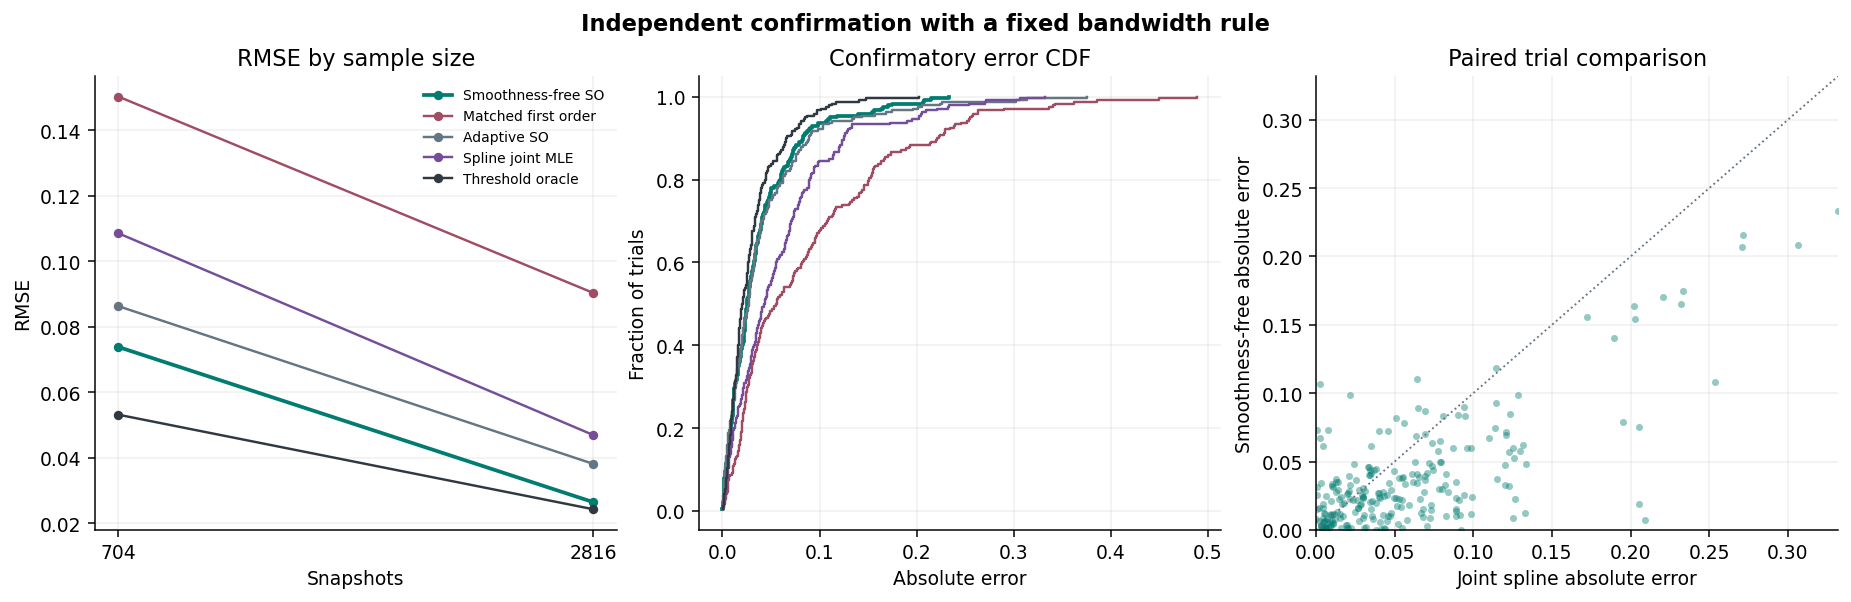

In [ ]:
# Matched first-order ablation and comparison with joint likelihood
confirmation_order = ("Smoothness-free SO", "Matched first order", "Adaptive SO", "Spline joint MLE", "Threshold oracle")
confirmation_metrics = empirical_metrics(confirmation, ["method"]).set_index("method")
confirmation_effects = paired_rmse_intervals(confirmation, confirmation_order[:-1], seed=SPL_SEED + 90)
confirmation_table = confirmation_metrics.loc[:, ["rmse", "mae", "bias"]].join(
    confirmation_effects.set_index("baseline")
).reindex(confirmation_order)
display(confirmation_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.35), layout="constrained")
colors = {**SPL_COLORS, "Smoothness-free SO": "#007D70", "Adaptive SO": "#647584",
          "Matched first order": "#A04D64"}
split = empirical_metrics(confirmation, ["n", "method"])
for name in confirmation_order:
    part = split.loc[split.method.eq(name)].sort_values("n")
    axes[0].plot(part.n, part.rmse, color=colors[name], marker="o", markersize=4,
                 linewidth=2 if name == "Smoothness-free SO" else 1.3, label=name)
    error = np.sort(confirmation.loc[confirmation.method.eq(name), "error"].abs().to_numpy())
    axes[1].step(error, np.arange(1, len(error) + 1) / len(error), where="post",
                 color=colors[name], linewidth=2 if name == "Smoothness-free SO" else 1.3)
axes[0].set(title="RMSE by sample size", xlabel="Snapshots", ylabel="RMSE",
            xticks=np.sort(confirmation.n.unique()))
axes[0].legend(fontsize=7.4)
axes[1].set(title="Confirmatory error CDF", xlabel="Absolute error", ylabel="Fraction of trials")
wide = confirmation.pivot(index=["family", "n", "truth", "rep"], columns="method", values="error").abs()
x, y = wide["Spline joint MLE"], wide["Smoothness-free SO"]
top = max(x.max(), y.max())
axes[2].plot([0, top], [0, top], color="#647584", linewidth=1, linestyle=":")
axes[2].scatter(x, y, color=colors["Smoothness-free SO"], s=14, alpha=0.42, linewidths=0)
axes[2].set(title="Paired trial comparison", xlabel="Joint spline absolute error",
            ylabel="Smoothness-free absolute error", xlim=(0, top), ylim=(0, top))
fig.suptitle("Independent confirmation with a fixed bandwidth rule", fontweight="bold")
plt.show()


In [ ]:
# Verify the Taylor remainder and the neighboring-pair curvature identity
def quadratic_form(x, h, y):
    return np.einsum("...i,...ij,...j->...", x, h, y)


def curvature_check(seed):
    rng = np.random.default_rng(seed)
    pilot = rng.uniform(0.23, 0.77, (1450, 2))
    direction = rng.uniform(-1, 1, (len(pilot), 2))
    link = BinaryLink(pilot)
    eps_grid = np.geomspace(0.0018, 0.12, 13)
    rows = []
    for rho in (-0.72, 0.28, 0.67):
        q = link.coincidence(rho)
        grad, h = link.marginal_derivatives(rho)
        hessian = np.stack((h[:, [0, 1]], h[:, [1, 2]]), axis=1)
        for eps in eps_grid:
            d = eps * direction
            exact = BinaryLink(pilot + d).coincidence(rho)
            linear = (grad * d).sum(axis=1)
            quadratic = 0.5 * quadratic_form(d, hessian, d)
            for name, residual in (("Plug-in", exact - q),
                                   ("First order", exact - q - linear),
                                   ("Second order", exact - q - linear - quadratic)):
                rows.append((rho, eps, name, rmse(residual)))
        deviations = rng.uniform(-0.08, 0.08, (len(pilot), 8, 2))
        i, j = np.triu_indices(8, k=1)
        expanded_h = hessian[:, None, :, :]
        same = 0.5 * quadratic_form(deviations, expanded_h, deviations).mean(axis=1)
        cross = quadratic_form(deviations[:, i], expanded_h, deviations[:, j]).sum(axis=1) / 56
        difference = deviations[:, i] - deviations[:, j]
        mismatch = quadratic_form(difference, expanded_h, difference).sum(axis=1) / 112
        np.testing.assert_allclose(same - cross, mismatch, atol=1e-13)
    return pd.DataFrame(rows, columns=("truth", "epsilon", "term", "rms"))


remainders = curvature_check(SPL_SEED + 30)
remainder_slopes = remainders.groupby(["term", "truth"])[["epsilon", "rms"]].apply(
    lambda x: np.polyfit(np.log(x.epsilon), np.log(x.rms), 1)[0]
).unstack()
np.testing.assert_allclose(remainder_slopes.loc[["Plug-in", "First order", "Second order"]].mean(axis=1),
                           [1, 2, 3], atol=0.09)
print("Mean Taylor slopes", remainder_slopes.mean(axis=1).round(3).to_dict())


Mean Taylor slopes {'First order': 1.999, 'Plug-in': 1.001, 'Second order': 3.0}


In [ ]:
# Separate rate benchmark with fixed smoothness-free and smoothness-informed windows
def holder_thresholds(n, smoothness, rng):
    t = (np.arange(n) + 0.5) / n
    levels = np.arange(min(10, int(np.log2(n)) - 2))
    scale = 2.0 ** (-smoothness * levels)
    angle = 2 * np.pi * (2.0 ** levels) * t[:, None] + rng.uniform(0, 2 * np.pi, len(levels))
    common = np.sin(angle) @ scale / scale.sum()
    other = np.sin(angle + rng.uniform(-0.95, 0.95, len(levels))) @ scale / scale.sum()
    return np.clip(np.array([0.47, 0.54]) + 0.36 * np.column_stack((common, other)), 0.07, 0.93)


def fixed_rate_benchmark(seed):
    reps = 12 if SPL_FULL else 2
    n_grid = (512, 2048, 8192) if SPL_FULL else (512, 2048)
    settings = list(product(n_grid, (0.10, 0.20, 0.25, 0.50, 0.80), (-0.68, 0.0, 0.68)))
    rows = []
    started = perf_counter()
    for (n, s, rho), child in zip(settings, np.random.SeedSequence(seed).spawn(len(settings))):
        informed_radius = max(16, round(3.0 * n ** (2 * s / (2 * s + 1))))
        for rep, trial_seed in enumerate(child.spawn(reps)):
            rng = np.random.default_rng(trial_seed)
            p = holder_thresholds(n, s, rng)
            analog = colored_normal(n, np.array([[1, rho], [rho, 1]]), rng)
            bits = (analog <= special.ndtri(p)).astype(float)
            fixed = fixed_block_moments(bits)
            informed = fixed_block_moments(bits, radius=informed_radius)
            for name, data, order in (("Smoothness-free SO", fixed, 2), ("Known-s SO", informed, 2),
                                      ("Matched first order", fixed, 1)):
                estimate = MomentEstimator(data, order=order, weighted=False, shrink=False, stabilize=False).fit().rho
                rows.append((n, s, rho, rep, name, estimate - rho))
    print(f"{len(settings) * reps} independent fixed-bandwidth trials in {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows, columns=("n", "s", "truth", "rep", "method", "error"))


fixed_rate = fixed_rate_benchmark(SPL_SEED + 4000)
assert fixed_rate.error.notna().all()


540 independent fixed-bandwidth trials in 4.3 s


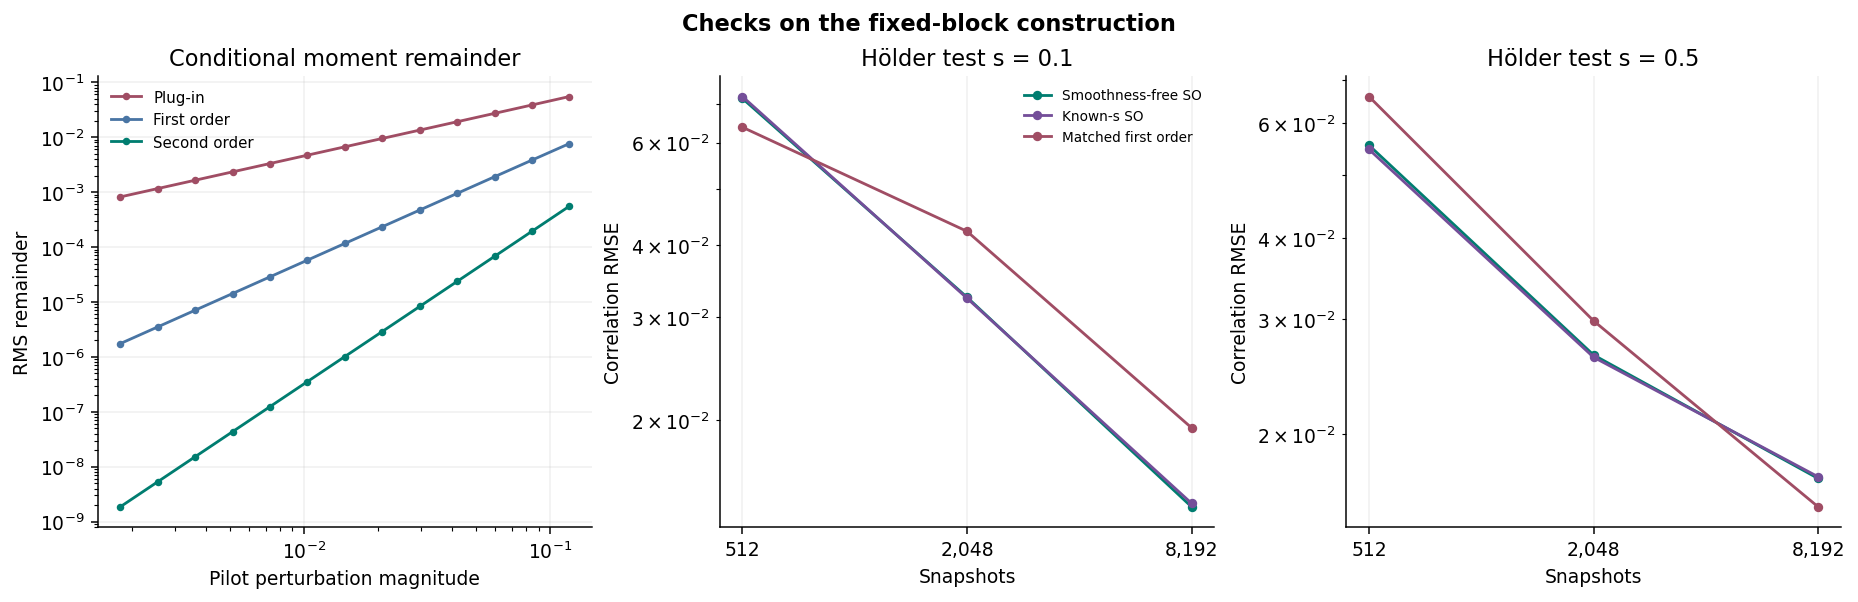

In [ ]:
# Pilot-error orders and empirical error on smoothness classes
fig, axes = plt.subplots(1, 3, figsize=(13.65, 4.35), layout="constrained")
term_colors = {"Plug-in": "#A04D64", "First order": "#4975A4", "Second order": "#007D70"}
for name, group in remainders.groupby("term", sort=False):
    curve = group.groupby("epsilon")["rms"].median()
    axes[0].loglog(curve.index, curve, marker="o", markersize=3, color=term_colors[name], label=name)
axes[0].set(title="Conditional moment remainder", xlabel="Pilot perturbation magnitude", ylabel="RMS remainder")
axes[0].legend(fontsize=8)
colors = {"Smoothness-free SO": "#007D70", "Known-s SO": "#744E99", "Matched first order": "#A04D64"}
for ax, s in zip(axes[1:], (0.10, 0.50)):
    for name, group in fixed_rate.loc[fixed_rate.s.eq(s)].groupby("method", sort=False):
        curve = group.groupby("n")["error"].agg(rmse)
        ax.loglog(curve.index, curve, color=colors[name], marker="o", markersize=4, label=name)
    ax.set(title=f"Hölder test s = {s:g}", xlabel="Snapshots", ylabel="Correlation RMSE")
    ax.set_xticks(curve.index, [f"{n:,}" for n in curve.index])
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
axes[1].legend(fontsize=7.3)
fig.suptitle("Checks on the fixed-block construction", fontweight="bold")
plt.show()


In [ ]:
# Benchmark grid and independent random seeds
if PROFILE not in {"quick", "full"}:
    raise ValueError("PROFILE must be 'quick' or 'full'.")
FULL = PROFILE == "full"
BENCHMARK_SEED = 20261203
CORE_REPS, STRESS_REPS, ABLATION_REPS, RATE_REPS = (20, 14, 18, 38) if FULL else (2, 2, 2, 3)
CORE_N = (384, 1536, 6144) if FULL else (384, 1536, 3072)
STRESS_N = (768, 3072) if FULL else (384, 1536)
RHO_GRID = (-0.88, -0.45, 0.0, 0.45, 0.88)

core_cases = [Scenario(drift=drift, n=n, rho=rho) for drift, n, rho in product(CORE_DRIFTS, CORE_N, RHO_GRID)]

STRESS_GRID = {
    "AR positive": ("Slow", [(x, {"ar": x}) for x in (0, 0.35, 0.63, 0.86)]),
    "AR negative": ("Steps", [(x, {"ar": -x}) for x in (0, 0.40, 0.72)]),
    "MA dependence": ("Multiscale", [(x, {"ma": x}) for x in (0, 0.40, 0.82)]),
    "Random loss": ("Steps", [(x, {"dropout": x}) for x in (0, 0.15, 0.35, 0.52)]),
    "Burst loss": ("Chirp", [(x, {"burst_loss": x}) for x in (0, 0.15, 0.35, 0.55)]),
    "Independent flips": ("Fast shared", [(x, {"flips": (x, 1.35 * x)}) for x in (0, 0.025, 0.065, 0.115)]),
    "Heavy tails": ("Fixed offset", [(i, {"df": x}) for i, x in enumerate((np.inf, 12, 6, 3))]),
    "Saturation": ("Ramp", [(x, {"saturation": x}) for x in (0, 0.50, 0.78, 0.95)]),
    "Impulsive signals": ("Counterphase", [(x, {"impulses": x}) for x in (0, 0.03, 0.10)]),
    "Informative loss": ("Slow", [(x, {"informative": x}) for x in (0, 0.15, 0.36)]),
    "Burst bit errors": ("Slow", [(x, {"burst_flips": x}) for x in (0, 0.06, 0.15)]),
    "Fast drift + AR": ("Fast shared", [(x, {"ar": x}) for x in (0, 0.42, 0.70)]),
    "Fast drift + AR + loss": ("Fast shared", [(x, {"ar": 0.63, "dropout": x}) for x in (0.18, 0.40)]),
    "Heavy tails + flips": ("Slow", [(x, {"df": 4, "flips": (x, x)}) for x in (0.04, 0.10)]),
}
stress_cases = [
    Scenario(family=family, drift=drift, n=n, rho=rho, level=level, **options)
    for family, (drift, settings) in STRESS_GRID.items()
    for (level, options), n, rho in product(settings, STRESS_N, (-0.62, 0.62))
]

ABLATION_GRID = (
    ("Stable", "Fixed offset", {}), ("Smooth", "Slow", {}),
    ("Periodic", "Fast shared", {}), ("Chirp", "Chirp", {}),
    ("Steps + loss", "Steps", {"dropout": 0.32}),
    ("Serial", "Slow", {"ar": 0.80}),
    ("Periodic + serial", "Fast shared", {"ar": 0.68}),
    ("Saturation", "Ramp", {"saturation": 0.88}),
)
ablation_cases = [Scenario(family=family, drift=drift, n=n, rho=rho, **options)
                  for family, drift, options in ABLATION_GRID
                  for n, rho in product(STRESS_N, (-0.65, 0.0, 0.65))]


In [ ]:
# Core benchmark
core = benchmark(core_cases, CORE_REPS, BENCHMARK_SEED + 1000)
assert core.loc[core["method"] == "Adaptive SO", "estimate"].notna().all()


33/135 settings complete
66/135 settings complete
99/135 settings complete
132/135 settings complete
135 settings · 2,700 trials · 106.7 s


In [ ]:
# Stress benchmark
stress = benchmark(stress_cases, STRESS_REPS, BENCHMARK_SEED + 2000, compact=True)


46/184 settings complete
92/184 settings complete
138/184 settings complete
184 settings · 2,576 trials · 79.6 s


In [ ]:
# Matched ablations
ablation = benchmark(ablation_cases, ABLATION_REPS, BENCHMARK_SEED + 3000, ablate=True, compact=True)


12/48 settings complete
24/48 settings complete
36/48 settings complete
48 settings · 864 trials · 52.2 s


In [ ]:
# Hard-drift rate experiment with identical observations in two worlds
def rate_study(seed):
    rng = np.random.default_rng(seed)
    sample_sizes = (256, 512, 1024, 2048, 4096, 8192) if FULL else (256, 1024, 4096)
    exponents = (0.10, 0.18, 0.25, 0.50)
    rows = []
    started = perf_counter()
    for n, smoothness in product(sample_sizes, exponents):
        delta = 0.43 * n ** (-smoothness)
        other_rho = np.sin(2 * np.pi * delta ** 2)
        for rep in range(RATE_REPS):
            sign = rng.choice([-1, 1], size=(n, 1))
            margins = 0.5 + delta * sign
            bits = (rng.random((n, 2)) <= margins).astype(float)
            adaptive = fit_onebit(bits, gap=1).rho
            fixed = prepare_moments(bits, block=8, gap=1, pilot="fixed")
            original = MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho
            for name, estimate in (("Adaptive SO", adaptive), ("Original SO", original)):
                rows.append((n, smoothness, rep, name, estimate, other_rho,
                             estimate, estimate - other_rho))
    print(f"{len(sample_sizes) * len(exponents) * RATE_REPS:,} draws · two indistinguishable worlds per draw · {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows, columns=("n", "s", "rep", "method", "estimate",
                                       "separation", "error_drift", "error_fixed"))


rate = rate_study(BENCHMARK_SEED + 4000)


912 draws · two indistinguishable worlds per draw · 13.7 s


In [ ]:
# Plot palette and compact summaries
PALETTE = {
    "Adaptive SO": "#007D70", "Original SO": "#C85833", "Local MLE": "#285C9B",
    "Pooled": "#7A6888", "Threshold oracle": "#303842", "Arcsine": "#A68955",
    "Local plug-in": "#7B8693", "First order": "#428EA3", "Calibrated SO": "#8E449D",
}
LINESTYLES = {"Adaptive SO": "-", "Calibrated SO": "-", "Threshold oracle": ":",
              "Original SO": "--", "Local MLE": "-.", "Pooled": "--"}
MARKERS = {"Adaptive SO": "o", "Original SO": "s", "Local MLE": "D",
           "Pooled": "^", "Threshold oracle": "x", "Calibrated SO": "P"}


def method_curve(ax, x, y, method, *, band=None, markers=True):
    color = PALETTE[method]
    ax.plot(np.asarray(x), np.asarray(y), label=method, color=color,
            linestyle=LINESTYLES.get(method, "-"), marker=MARKERS.get(method, "o") if markers else None,
            linewidth=2.05 if method in {"Adaptive SO", "Calibrated SO"} else 1.35, markersize=4)
    if band is not None:
        low, high = band
        ax.fill_between(np.asarray(x), np.asarray(low), np.asarray(high), color=color,
                        alpha=0.105, linewidth=0)


def figure_key(fig, axes, columns=5):
    labels_to_handles = {}
    for ax in np.ravel(axes):
        handles, labels = ax.get_legend_handles_labels()
        for label, handle in zip(labels, handles):
            labels_to_handles.setdefault(label, handle)
    fig.legend(labels_to_handles.values(), labels_to_handles.keys(), loc="outside lower center",
               ncol=columns, fontsize=9)


def pivot_rmse(frame, group):
    return empirical_metrics(frame, [group, "method"]).pivot(index=group, columns="method", values="rmse")


core_lookup = {
    **dict.fromkeys(("Balanced", "Fixed offset"), "Stable"),
    **dict.fromkeys(("Ramp", "Slow", "Counterphase"), "Slow drift"),
    **dict.fromkeys(("Fast shared", "Chirp", "Steps", "Multiscale"), "Rapid or irregular"),
}
core_grouped = core.assign(drift_group=core["drift"].map(core_lookup))
core_summary = empirical_metrics(core, ["method"]).set_index("method")
core_table = pivot_rmse(core_grouped, "drift_group").T
core_table["All RMSE"] = core_summary["rmse"]
core_table["All MAE"] = core_summary["mae"]
core_table["P90 absolute error"] = core_summary["p90"]
core_table["Mean signed error"] = core_summary["bias"]
display(core_table.reindex(CORE_METHODS)[[
    "Stable", "Slow drift", "Rapid or irregular", "All RMSE", "All MAE",
    "P90 absolute error", "Mean signed error"
]].round(4))


drift_group,Stable,Slow drift,Rapid or irregular,All RMSE,All MAE,P90 absolute error,Mean signed error
method,,,,,,,
Arcsine,0.2574,0.1539,0.1961,0.1992,0.1420,0.3313,0.0341
Pooled,0.0436,0.1521,0.1957,0.1586,0.1138,0.2708,0.0748
Local plug-in,0.0438,0.0522,0.0765,0.0628,0.0412,0.1000,0.0166
Local MLE,0.0444,0.0428,0.0642,0.0537,0.0334,0.0816,0.0086
First order,0.0422,0.0431,0.0649,0.0538,0.0333,0.0799,0.0092
Original SO,0.0452,0.0438,0.0735,0.0591,0.0360,0.0885,0.0067
Adaptive SO,0.0426,0.0425,0.0489,0.0455,0.0300,0.0727,0.0030
Threshold oracle,0.0434,0.0415,0.0387,0.0408,0.0273,0.0672,-0.0006


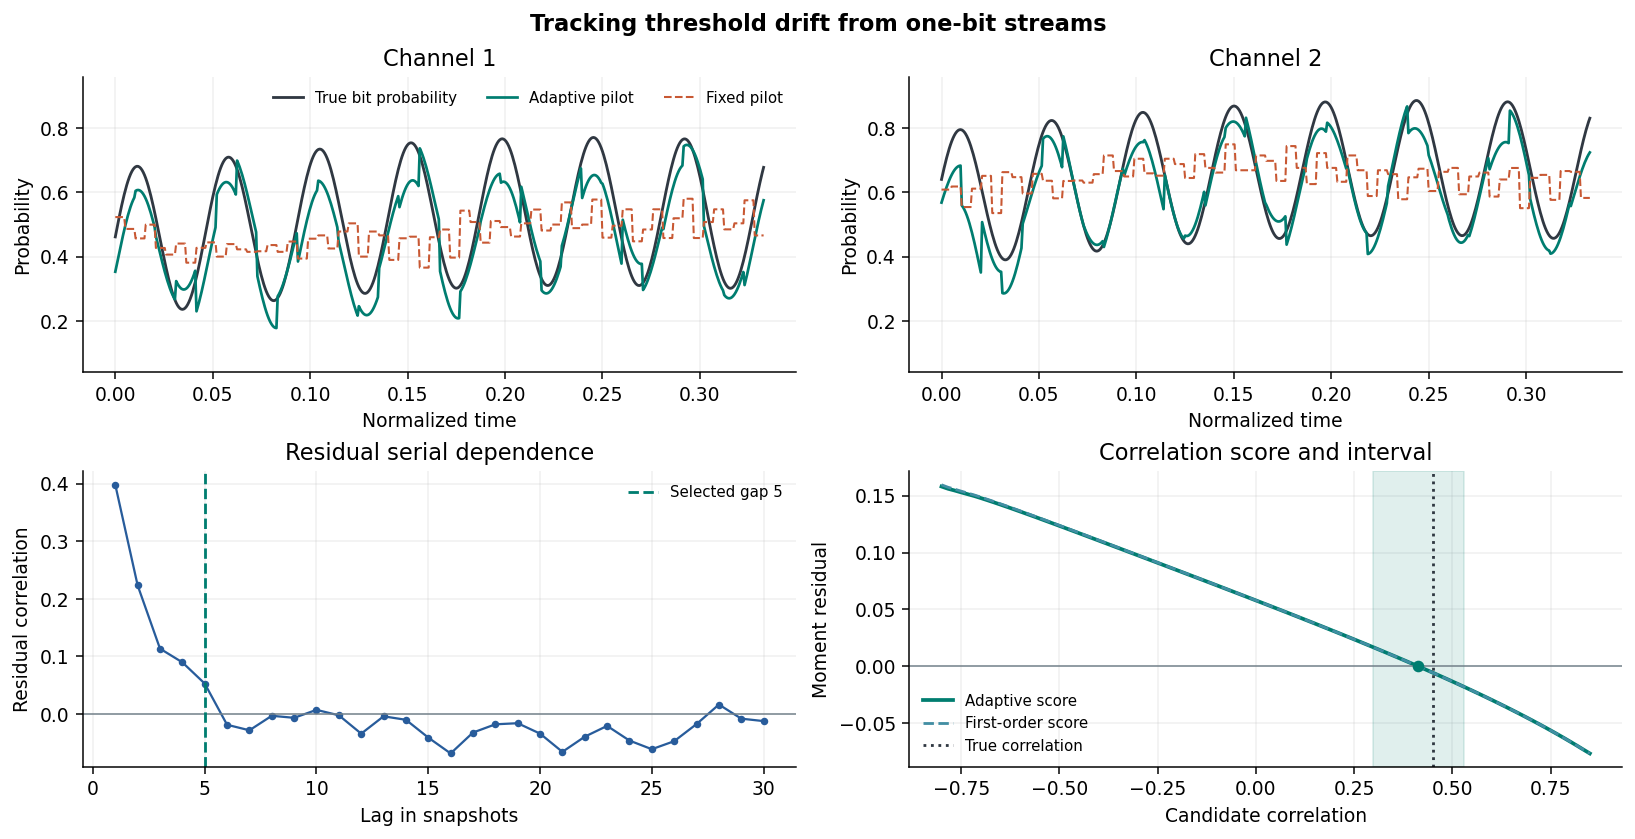

In [ ]:
# Example diagnostics and score inversion
example_case = Scenario(n=1536, rho=0.45, drift="Fast shared", ar=0.58, dropout=0.08)
example_bits, example_p, _ = simulate(example_case, SEED + 704)
example_data = prepare_moments(example_bits)
example_fit = MomentEstimator(example_data).fit(interval=True)
example_fixed = prepare_moments(example_bits, block=8, gap=1, pilot="fixed")

fig, axes = plt.subplots(2, 2, figsize=(12, 6.1), layout="constrained")
time = np.arange(len(example_bits)) / len(example_bits)
part = slice(0, len(time) // 3)
for j, ax in enumerate(axes[0]):
    ax.plot(time[part], example_p[part, j], color="#303842", linewidth=1.5, label="True bit probability")
    ax.plot(time[part], example_data.pilot_grid[part, j], color=PALETTE["Adaptive SO"], linewidth=1.45,
            label="Adaptive pilot")
    ax.plot(time[part], example_fixed.pilot_grid[part, j], color=PALETTE["Original SO"], linestyle="--",
            linewidth=1.1, label="Fixed pilot")
    ax.set(title=f"Channel {j + 1}", xlabel="Normalized time", ylabel="Probability", ylim=(0.04, 0.96))
axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
axes[1, 0].plot(np.arange(1, len(example_data.trace) + 1), example_data.trace,
                color="#285C9B", marker=".", linewidth=1.2)
axes[1, 0].axhline(0, color="#73818A", linewidth=0.8)
axes[1, 0].axvline(example_data.gap, color=PALETTE["Adaptive SO"], linestyle="--",
                  label=f"Selected gap {example_data.gap}")
axes[1, 0].set(title="Residual serial dependence", xlabel="Lag in snapshots", ylabel="Residual correlation")
axes[1, 0].legend(fontsize=8)
rho_grid = np.linspace(-0.80, 0.85, 100)
proposed_score = MomentEstimator(example_data)
uncorrected_score = MomentEstimator(example_data, order=1)
axes[1, 1].plot(rho_grid, [proposed_score.evaluate(r) for r in rho_grid], color=PALETTE["Adaptive SO"],
                linewidth=2, label="Adaptive score")
axes[1, 1].plot(rho_grid, [uncorrected_score.evaluate(r) for r in rho_grid],
                color=PALETTE["First order"], linestyle="--", label="First-order score")
axes[1, 1].axhline(0, color="#73818A", linewidth=0.8)
axes[1, 1].axvline(example_case.rho, color="#303842", linestyle=":", label="True correlation")
axes[1, 1].axvspan(example_fit.lower, example_fit.upper, color=PALETTE["Adaptive SO"], alpha=0.12)
axes[1, 1].scatter(example_fit.rho, 0, s=27, color=PALETTE["Adaptive SO"], zorder=4)
axes[1, 1].set(title="Correlation score and interval", xlabel="Candidate correlation", ylabel="Moment residual")
axes[1, 1].legend(fontsize=8)
fig.suptitle("Tracking threshold drift from one-bit streams", fontweight="bold")
plt.show()


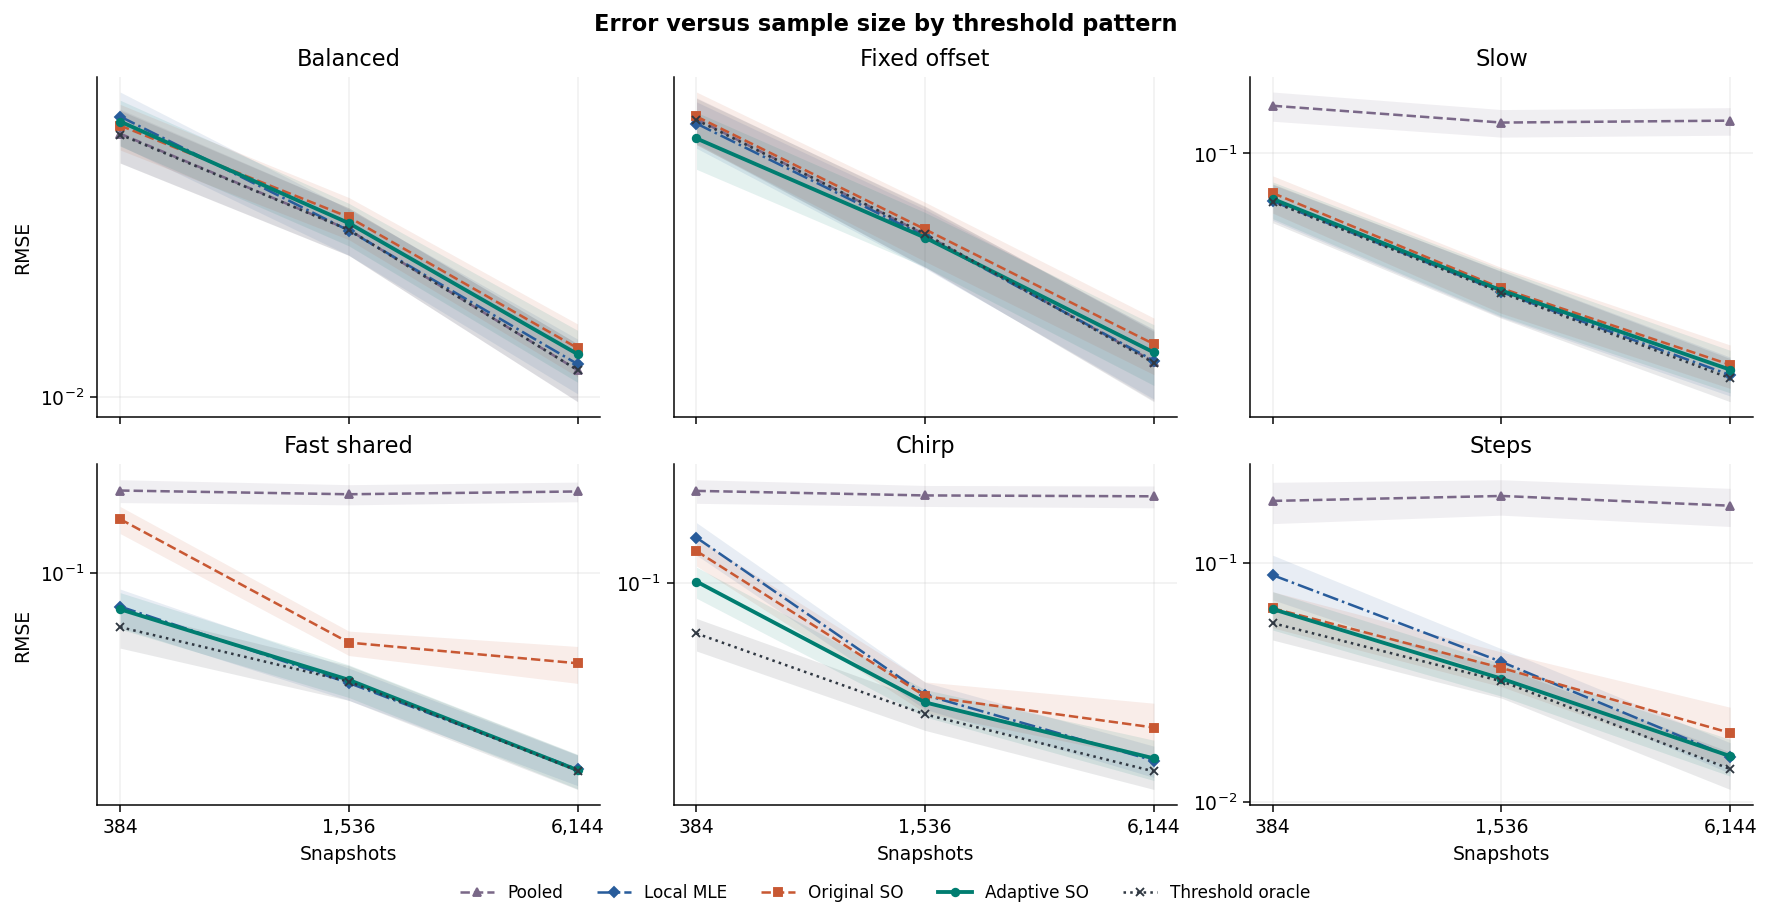

In [ ]:
# Error scaling across drift families
scaling = empirical_metrics(core, ["drift", "n", "method"])
panels = ("Balanced", "Fixed offset", "Slow", "Fast shared", "Chirp", "Steps")
fig, axes = plt.subplots(2, 3, figsize=(13.0, 6.7), layout="constrained", sharex=True)
for ax, drift in zip(axes.flat, panels):
    for name in PRIMARY:
        s = scaling.loc[(scaling["drift"] == drift) & (scaling["method"] == name)].sort_values("n")
        half = 1.96 * s["rmse_se"].fillna(0)
        method_curve(ax, s["n"], s["rmse"], name,
                     band=((s["rmse"] - half).clip(lower=1e-4), s["rmse"] + half))
    ax.set(xscale="log", yscale="log", title=drift, xticks=CORE_N)
    ax.set_xticklabels([f"{n:,}" for n in CORE_N])
    ax.minorticks_off()
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE")
for ax in axes[-1]:
    ax.set_xlabel("Snapshots")
figure_key(fig, axes)
fig.suptitle("Error versus sample size by threshold pattern", fontweight="bold")
plt.show()


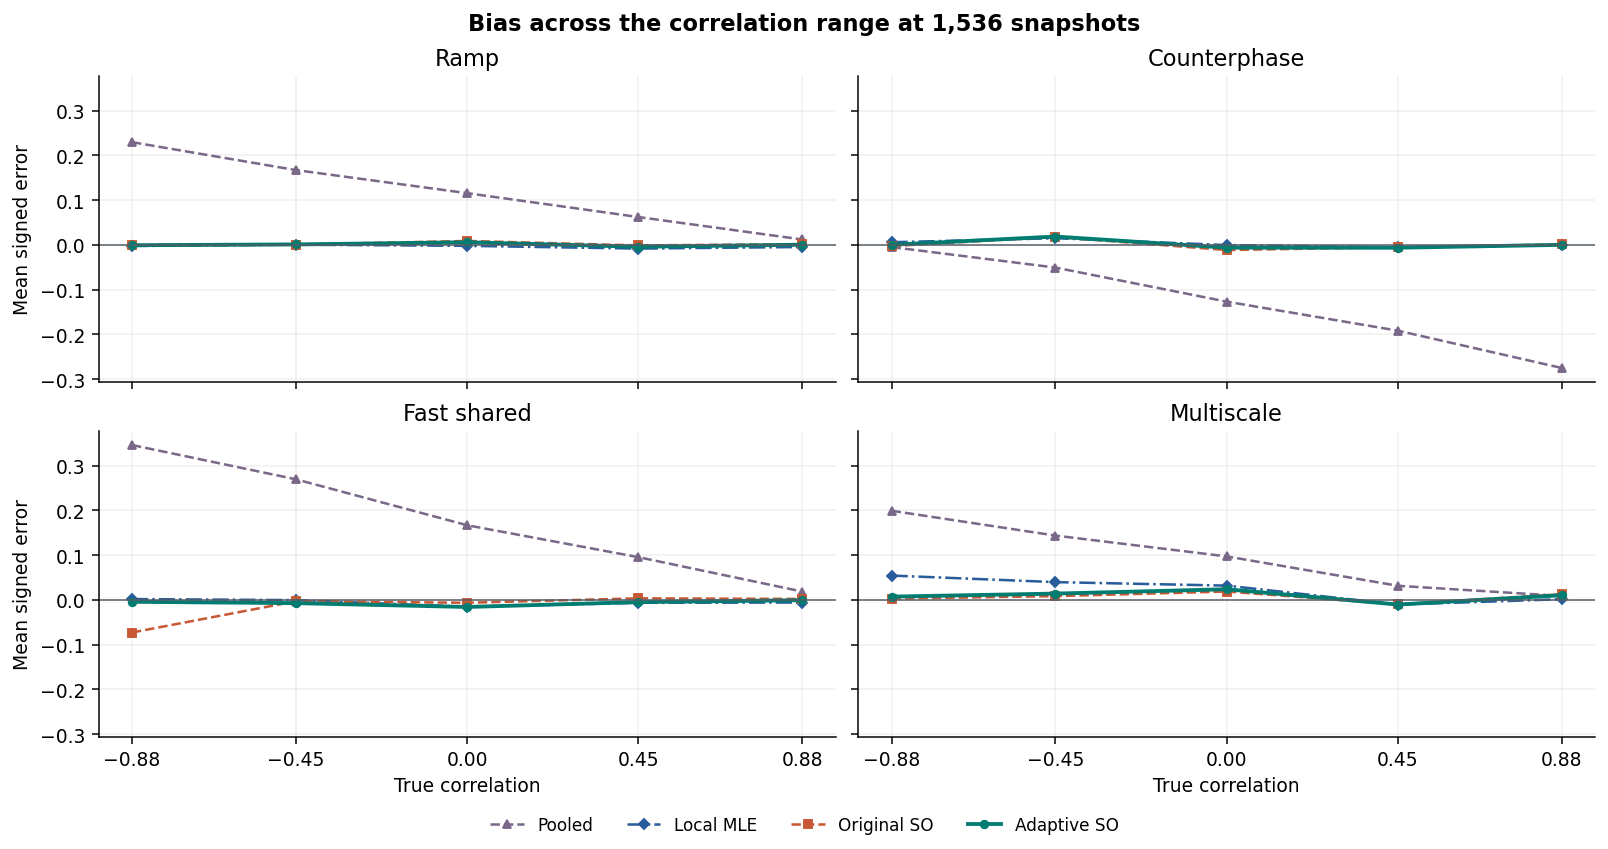

In [ ]:
# Signed bias across negative and positive correlation
bias_curves = empirical_metrics(core.loc[core["n"] == CORE_N[1]], ["drift", "truth", "method"])
fig, axes = plt.subplots(2, 2, figsize=(11.8, 6.2), layout="constrained", sharex=True, sharey=True)
for ax, drift in zip(axes.flat, ("Ramp", "Counterphase", "Fast shared", "Multiscale")):
    for name in ("Pooled", "Local MLE", "Original SO", "Adaptive SO"):
        s = bias_curves.loc[(bias_curves["drift"] == drift) & (bias_curves["method"] == name)].sort_values("truth")
        method_curve(ax, s["truth"], s["bias"], name)
    ax.axhline(0, linewidth=0.8, color="#555D66")
    ax.set(title=drift, xticks=RHO_GRID)
for ax in axes[:, 0]:
    ax.set_ylabel("Mean signed error")
for ax in axes[-1]:
    ax.set_xlabel("True correlation")
figure_key(fig, axes, 4)
fig.suptitle(f"Bias across the correlation range at {CORE_N[1]:,} snapshots", fontweight="bold")
plt.show()


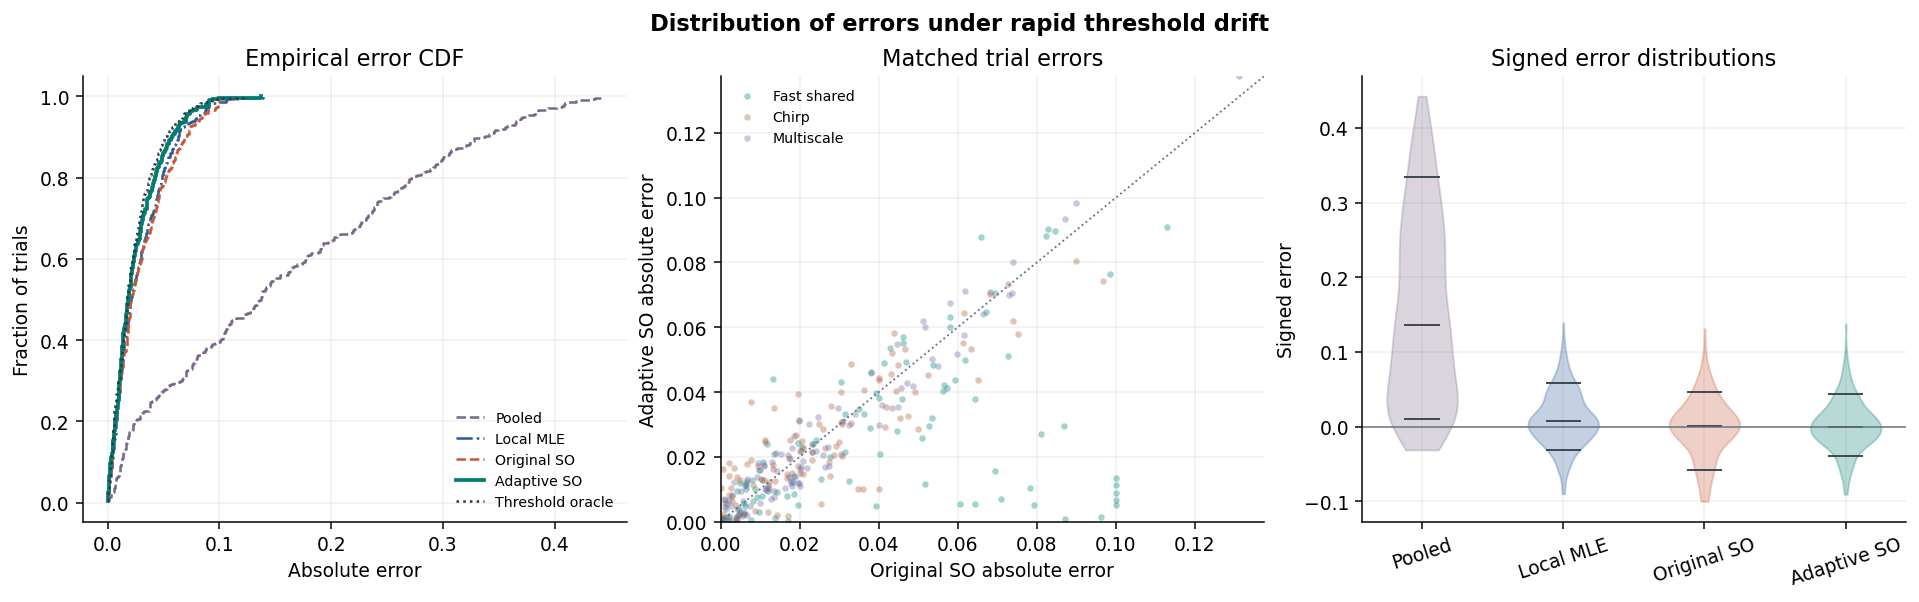

In [ ]:
# Paired errors, empirical tails, and trial-level distributions
rapid = core.loc[core["drift"].isin(("Fast shared", "Chirp", "Multiscale")) & (core["n"] == CORE_N[1])]
fig, axes = plt.subplots(1, 3, figsize=(14.1, 4.35), layout="constrained")
for name in PRIMARY:
    error = np.sort(rapid.loc[rapid["method"] == name, "error"].abs().dropna().to_numpy())
    cdf = np.arange(1, len(error) + 1) / len(error)
    axes[0].step(error, cdf, where="post", color=PALETTE[name], linestyle=LINESTYLES[name],
                 linewidth=2 if name == "Adaptive SO" else 1.35, label=name)
axes[0].set(title="Empirical error CDF", xlabel="Absolute error", ylabel="Fraction of trials")
axes[0].legend(fontsize=7.5, loc="lower right")

paired = rapid.pivot(index=["drift", "truth", "rep"], columns="method", values="error").abs()
for drift, color in (("Fast shared", "#008579"), ("Chirp", "#AF5C37"), ("Multiscale", "#6B68A1")):
    s = paired.loc[drift]
    axes[1].scatter(s["Original SO"], s["Adaptive SO"], label=drift, color=color,
                    s=12, alpha=0.36, linewidths=0)
bound = max(0.12, paired[["Original SO", "Adaptive SO"]].max().max())
axes[1].plot([0, bound], [0, bound], color="#667480", linewidth=1, linestyle=":")
axes[1].set(title="Matched trial errors", xlabel="Original SO absolute error",
            ylabel="Adaptive SO absolute error", xlim=(0, bound), ylim=(0, bound))
axes[1].legend(fontsize=7.5)

names = ("Pooled", "Local MLE", "Original SO", "Adaptive SO")
distributions = [rapid.loc[rapid["method"] == name, "error"].dropna().to_numpy() for name in names]
violins = axes[2].violinplot(distributions, showextrema=False, showmedians=True,
                             quantiles=[[0.10, 0.90] for _ in names])
for violin, name in zip(violins["bodies"], names):
    violin.set_facecolor(PALETTE[name])
    violin.set_edgecolor(PALETTE[name])
    violin.set_alpha(0.28)
for line in ("cmedians", "cquantiles"):
    violins[line].set_color("#37424D")
    violins[line].set_linewidth(1.0)
axes[2].axhline(0, color="#667480", linewidth=0.8)
axes[2].set(title="Signed error distributions", ylabel="Signed error",
            xticks=np.arange(1, len(names) + 1), xticklabels=names)
axes[2].tick_params(axis="x", rotation=18)
fig.suptitle("Distribution of errors under rapid threshold drift", fontweight="bold")
plt.show()


In [ ]:
# Stress endpoints and diagnostics
stress_end = stress.loc[stress["level"] == stress.groupby("family")["level"].transform("max")]
stress_table = pivot_rmse(stress_end, "family")
stress_diagnostics = stress_end.loc[stress_end["method"] == "Adaptive SO"].groupby("family").agg(
    coverage=("covered", "mean"), interval_width=("width", "median"),
    regular=("status", lambda x: x.eq("OK").mean()),
)
stress_table = stress_table.join(stress_diagnostics).reindex(list(STRESS_GRID))
display(stress_table[["Pooled", "Local MLE", "Original SO", "Adaptive SO",
                      "Calibrated SO", "Threshold oracle", "coverage",
                      "interval_width", "regular"]].rename(
    columns={"coverage": "Adaptive coverage", "interval_width": "Median interval width",
             "regular": "Regular fits"}).round(3))


,Pooled,Local MLE,Original SO,Adaptive SO,Calibrated SO,Threshold oracle,Adaptive coverage,Median interval width,Regular fits
family,,,,,,,,,
AR positive,0.154,0.095,0.531,0.097,NaN,0.074,0.946,0.266,0.982
AR negative,0.183,0.076,0.052,0.059,NaN,0.042,0.964,0.172,1.000
MA dependence,0.116,0.058,0.046,0.044,NaN,0.038,0.964,0.133,1.000
Random loss,0.170,0.093,0.108,0.101,NaN,0.073,0.964,0.304,1.000
Burst loss,0.225,0.102,0.067,0.061,NaN,0.063,0.964,0.207,1.000
Independent flips,0.361,0.322,0.318,0.318,0.092,0.089,0.000,0.166,1.000
Heavy tails,0.073,0.079,0.075,0.077,0.050,0.048,0.696,0.136,1.000
Saturation,0.258,0.227,0.301,0.101,NaN,0.258,1.000,1.281,0.500
Impulsive signals,0.143,0.160,0.158,0.159,NaN,NaN,0.250,0.137,1.000


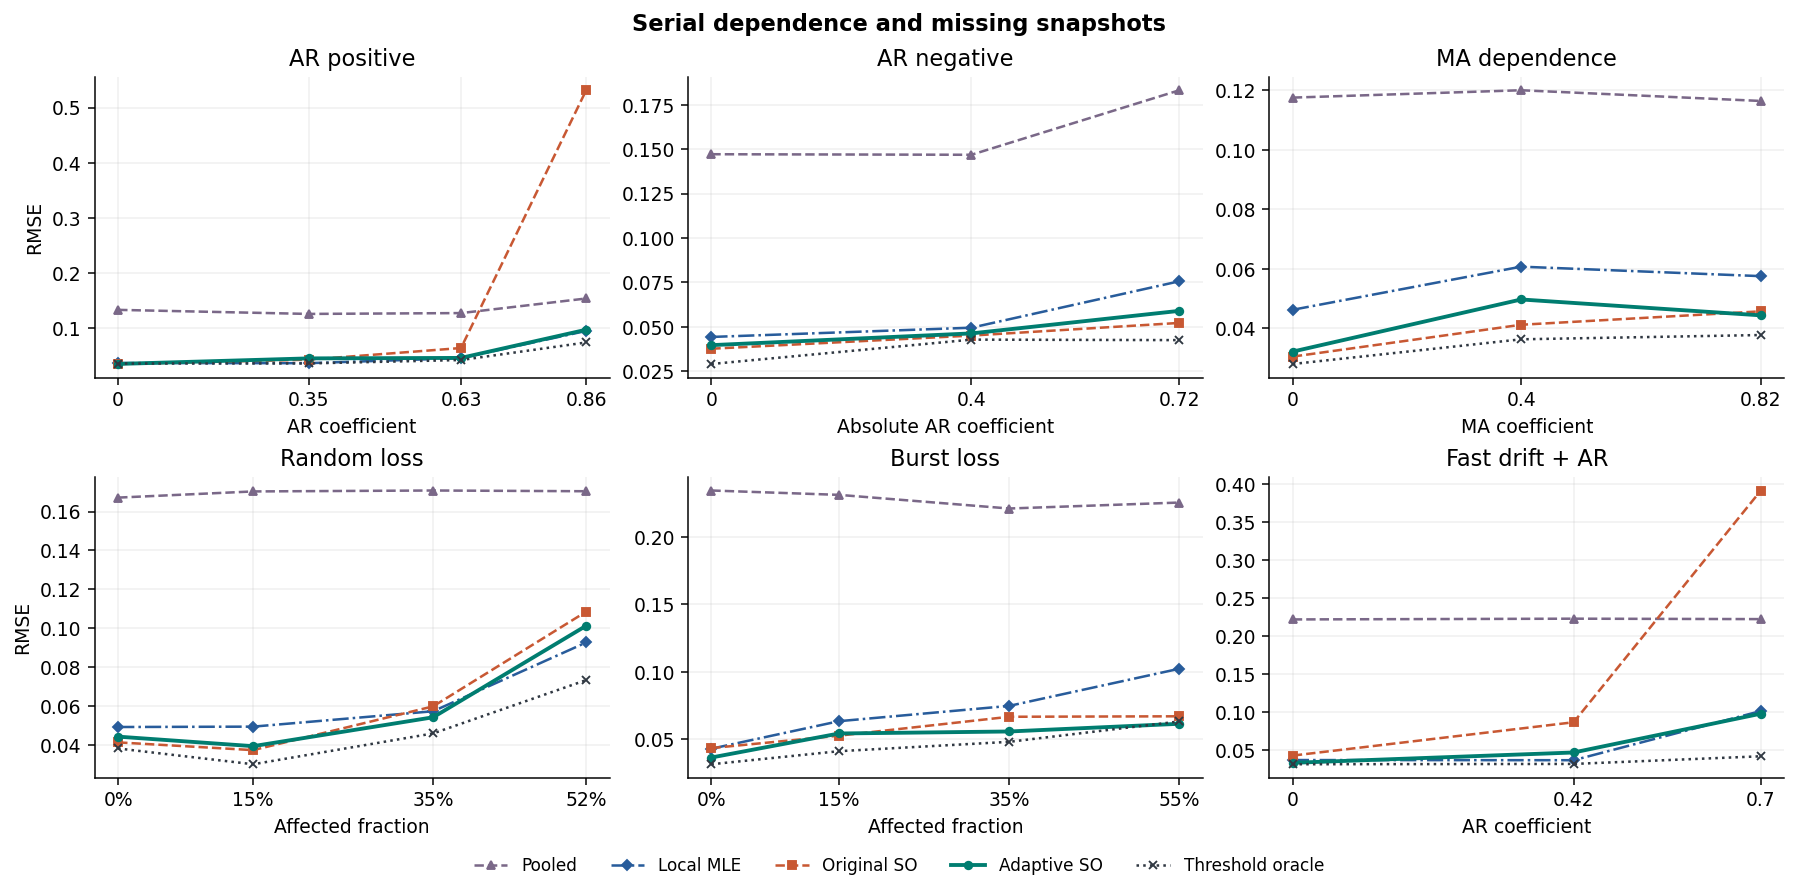

In [ ]:
# Sensitivity curves across impairment strengths
stress_curves = empirical_metrics(stress, ["family", "level", "method"])
calibrated_families = {"Independent flips", "Heavy tails", "Heavy tails + flips"}
percentage_families = {"Random loss", "Burst loss", "Independent flips", "Impulsive signals",
                       "Informative loss", "Burst bit errors", "Fast drift + AR + loss",
                       "Heavy tails + flips"}
stress_labels = {"AR positive": "AR coefficient", "AR negative": "Absolute AR coefficient",
                 "MA dependence": "MA coefficient", "Saturation": "Saturation strength",
                 "Heavy tails": "Student t degrees of freedom", "Fast drift + AR": "AR coefficient",
                 "Independent flips": "Channel 1 flip rate", "Heavy tails + flips": "Bit flip rate"}


def plot_stress_group(families, title):
    fig, axes = plt.subplots(2, 3, figsize=(13.2, 6.5), layout="constrained")
    for ax, family in zip(axes.flat, families):
        subset = stress_curves.loc[stress_curves["family"] == family]
        names = ["Pooled", "Local MLE", "Original SO", "Adaptive SO", "Threshold oracle"]
        if family in calibrated_families:
            names.insert(4, "Calibrated SO")
        for name in names:
            curve = subset.loc[subset["method"] == name].sort_values("level")
            if name == "Calibrated SO" and len(curve) and curve["level"].min() > 0 and subset["level"].min() == 0:
                zero = subset.loc[(subset["method"] == "Adaptive SO") & (subset["level"] == 0)]
                curve = pd.concat((zero, curve))
            if not curve.empty:
                method_curve(ax, curve["level"], curve["rmse"], name)
        levels = np.sort(subset["level"].unique())
        if family == "Heavy tails":
            labels = ["∞", "12", "6", "3"]
        elif family in percentage_families:
            labels = [f"{100 * v:g}%" for v in levels]
        else:
            labels = [f"{v:g}" for v in levels]
        ax.set(title=family, xlabel=stress_labels.get(family, "Affected fraction"), xticks=levels)
        ax.set_xticklabels(labels)
    for ax in axes[:, 0]:
        ax.set_ylabel("RMSE")
    figure_key(fig, axes, 6)
    fig.suptitle(title, fontweight="bold")
    plt.show()


plot_stress_group(("AR positive", "AR negative", "MA dependence", "Random loss", "Burst loss",
                   "Fast drift + AR"), "Serial dependence and missing snapshots")


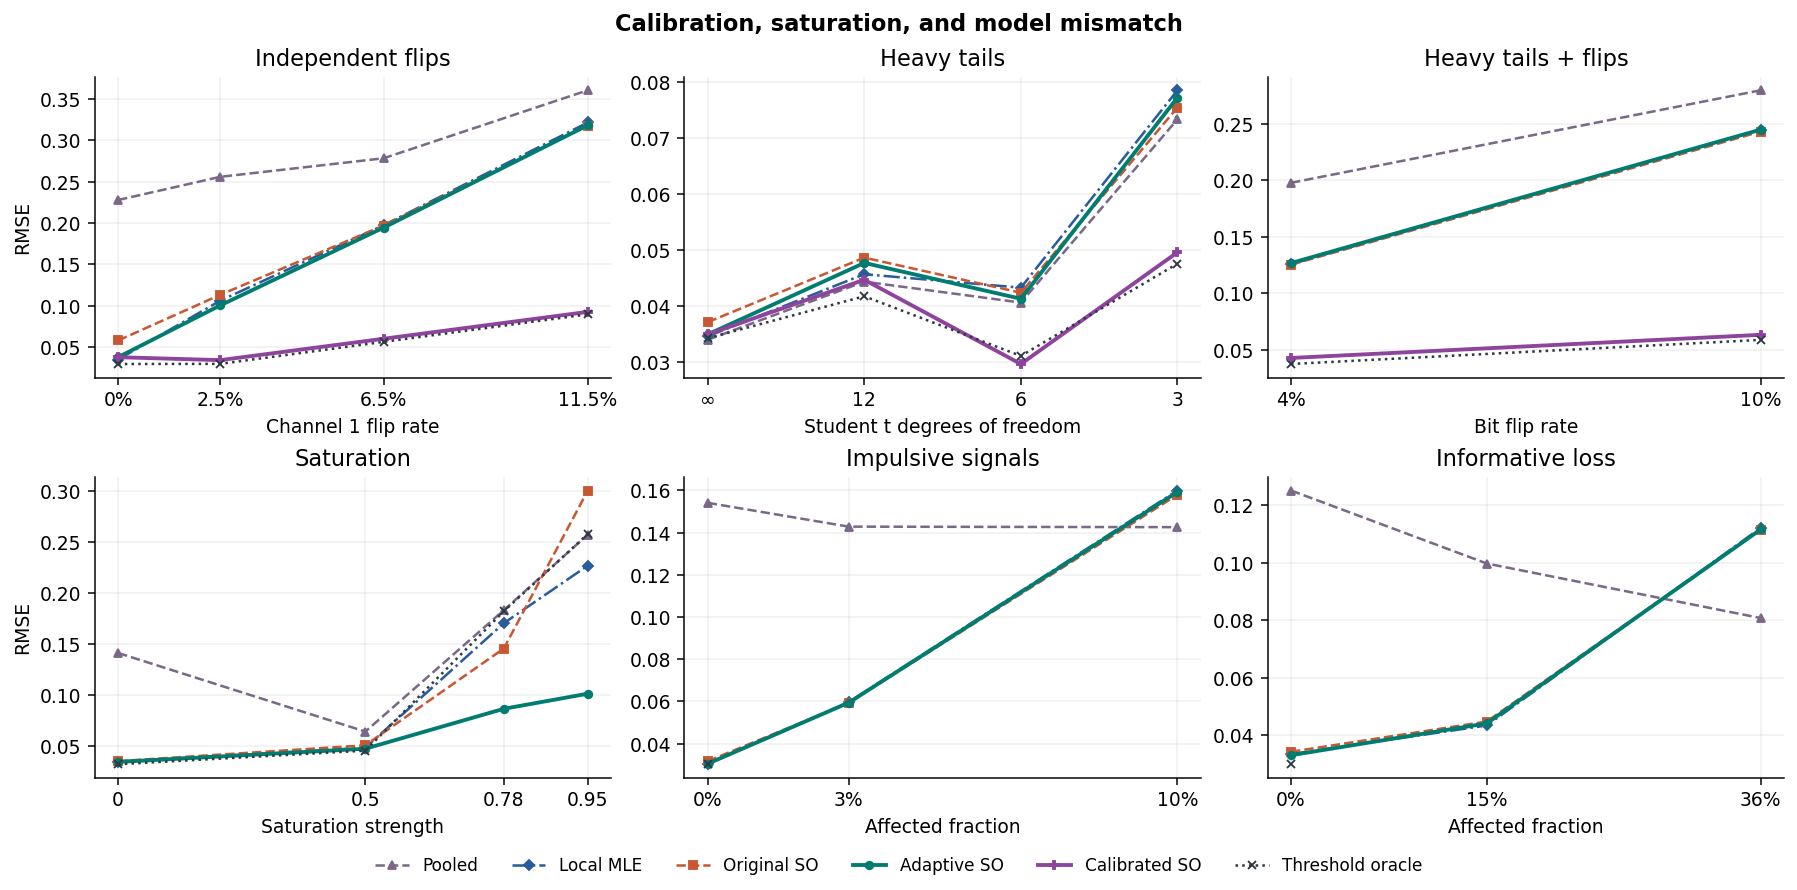

In [ ]:
plot_stress_group(("Independent flips", "Heavy tails", "Heavy tails + flips", "Saturation",
                   "Impulsive signals", "Informative loss"), "Calibration, saturation, and model mismatch")


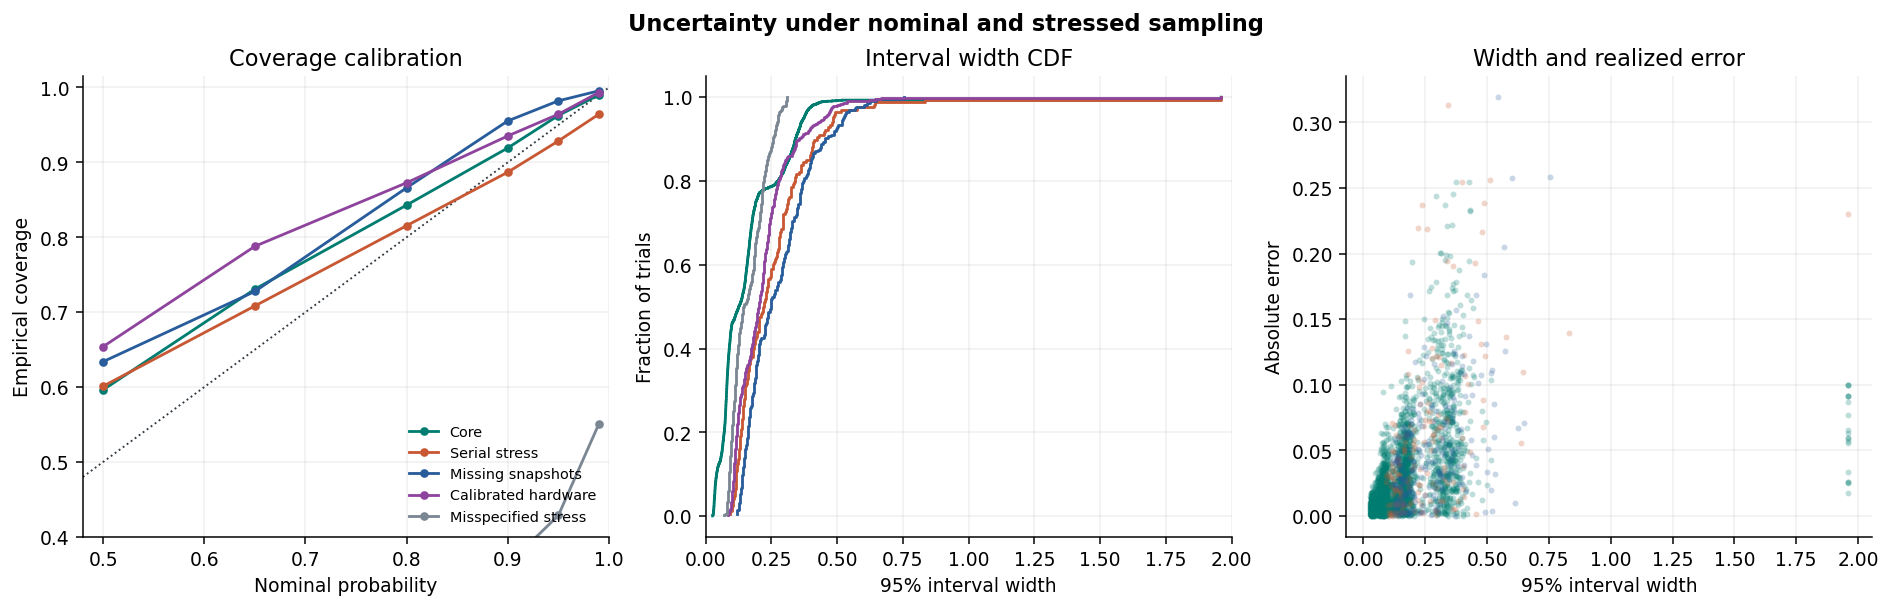

In [ ]:
# Confidence coverage and interval width
def with_method(frame, method="Adaptive SO"):
    return frame.loc[(frame["method"] == method) & np.isfinite(frame["estimate"])].copy()


def calibration_curve(frame, levels):
    error = frame["error"].abs().to_numpy()
    standard = frame["se"].to_numpy()
    adjustment = frame["bias_guard"].to_numpy()
    wide = frame["status"].eq("Weak information").to_numpy()
    return np.array([np.mean((error <= stats.norm.ppf((1 + p) / 2) * standard + adjustment) | wide)
                     for p in levels])


levels = np.array([0.50, 0.65, 0.80, 0.90, 0.95, 0.99])
core_intervals = with_method(core)
stress_intervals = with_method(stress)
serial_intervals = stress_intervals.loc[stress_intervals["family"].isin(("AR positive", "Fast drift + AR"))
                                       & (stress_intervals["level"] >= 0.6)]
drop_intervals = stress_intervals.loc[stress_intervals["family"].isin(("Random loss", "Burst loss"))
                                     & (stress_intervals["level"] >= 0.35)]
cal_intervals = with_method(stress, "Calibrated SO")
misfit_intervals = stress_intervals.loc[stress_intervals["family"].isin(("Impulsive signals", "Informative loss", "Burst bit errors"))
                                       & (stress_intervals["level"] > 0)]
interval_groups = (
    ("Core", core_intervals, "#007D70"), ("Serial stress", serial_intervals, "#C85833"),
    ("Missing snapshots", drop_intervals, "#285C9B"), ("Calibrated hardware", cal_intervals, "#8E449D"),
    ("Misspecified stress", misfit_intervals, "#7B8693"),
)
fig, axes = plt.subplots(1, 3, figsize=(13.9, 4.4), layout="constrained")
axes[0].plot([0.48, 1], [0.48, 1], color="#303842", linewidth=1, linestyle=":")
for label, samples, color in interval_groups:
    axes[0].plot(levels, calibration_curve(samples, levels), marker="o", markersize=3.6, color=color, label=label)
    widths = np.sort(samples["width"].dropna())
    axes[1].step(widths, np.arange(1, len(widths) + 1) / len(widths), where="post",
                 linewidth=1.5, color=color, label=label)
    if label in {"Core", "Serial stress", "Missing snapshots"}:
        axes[2].scatter(samples["width"], samples["error"].abs(), color=color, s=10, alpha=0.25, linewidths=0)
axes[0].set(title="Coverage calibration", xlabel="Nominal probability", ylabel="Empirical coverage",
            xlim=(0.48, 1), ylim=(0.40, 1.015))
axes[1].set(title="Interval width CDF", xlabel="95% interval width", ylabel="Fraction of trials", xlim=(0, 2))
axes[2].set(title="Width and realized error", xlabel="95% interval width", ylabel="Absolute error")
axes[0].legend(fontsize=7.7, loc="lower right")
fig.suptitle("Uncertainty under nominal and stressed sampling", fontweight="bold")
plt.show()


In [ ]:
# Paired bootstrap for the component ablations
ABLATIONS = ("No quadratic term", "Fixed pilot", "No spectral pilot", "No lag buffer",
             "No shrinkage", "Uniform weights", "No stabilization")


def paired_ablation(frame, seed, draws=450):
    columns = ("Adaptive SO", *ABLATIONS)
    wide = frame.loc[frame["method"].isin(columns)].pivot(
        index=["family", "n", "truth", "rep"], columns="method", values="error"
    ).reindex(columns=columns).dropna()
    matrix = wide.to_numpy() ** 2
    sample_rmse = np.sqrt(matrix.mean(axis=0))
    rng = np.random.default_rng(seed)
    bootstrap = np.zeros((draws, len(columns)))
    for indices in wide.groupby(level=["family", "n", "truth"], sort=False).indices.values():
        indices = np.asarray(indices)
        resampled = rng.choice(indices, size=(draws, len(indices)), replace=True)
        bootstrap += matrix[resampled].sum(axis=1)
    bootstrap = np.sqrt(bootstrap / len(matrix))
    delta = bootstrap[:, 1:] - bootstrap[:, :1]
    return pd.DataFrame({"component removed": ABLATIONS,
                         "delta": sample_rmse[1:] - sample_rmse[0],
                         "lower": np.quantile(delta, 0.025, axis=0),
                         "upper": np.quantile(delta, 0.975, axis=0)})


delta_table = pivot_rmse(ablation, "family")
delta_table = delta_table.loc[:, list(ABLATIONS)].subtract(delta_table["Adaptive SO"], axis=0)
delta_table.insert(0, "Adaptive SO RMSE", pivot_rmse(ablation, "family")["Adaptive SO"])
display(delta_table.reindex([x[0] for x in ABLATION_GRID]).round(4))


method,Adaptive SO RMSE,No quadratic term,Fixed pilot,No spectral pilot,No lag buffer,No shrinkage,Uniform weights,No stabilization
family,,,,,,,,
Stable,0.0423,-0.0008,0.0004,0.0000,0.0000,0.0015,0.0001,-0.0000
Smooth,0.0420,0.0015,-0.0009,-0.0002,0.0000,-0.0003,-0.0002,0.0001
Periodic,0.0389,0.0001,0.0102,0.0068,0.0000,0.0012,0.0000,-0.0002
Chirp,0.0437,0.0080,0.0100,0.0074,0.0000,0.0007,-0.0004,-0.0002
Steps + loss,0.0729,-0.0047,0.0016,-0.0003,-0.0002,0.0061,0.0012,-0.0001
Serial,0.0686,-0.0010,0.0012,0.0009,0.1446,0.0168,-0.0010,-0.0002
Periodic + serial,0.0751,0.0045,0.0774,0.0751,0.0136,0.0135,0.0015,-0.0004
Saturation,0.0817,-0.0089,-0.0006,0.0000,0.0000,0.0090,0.0024,0.0444


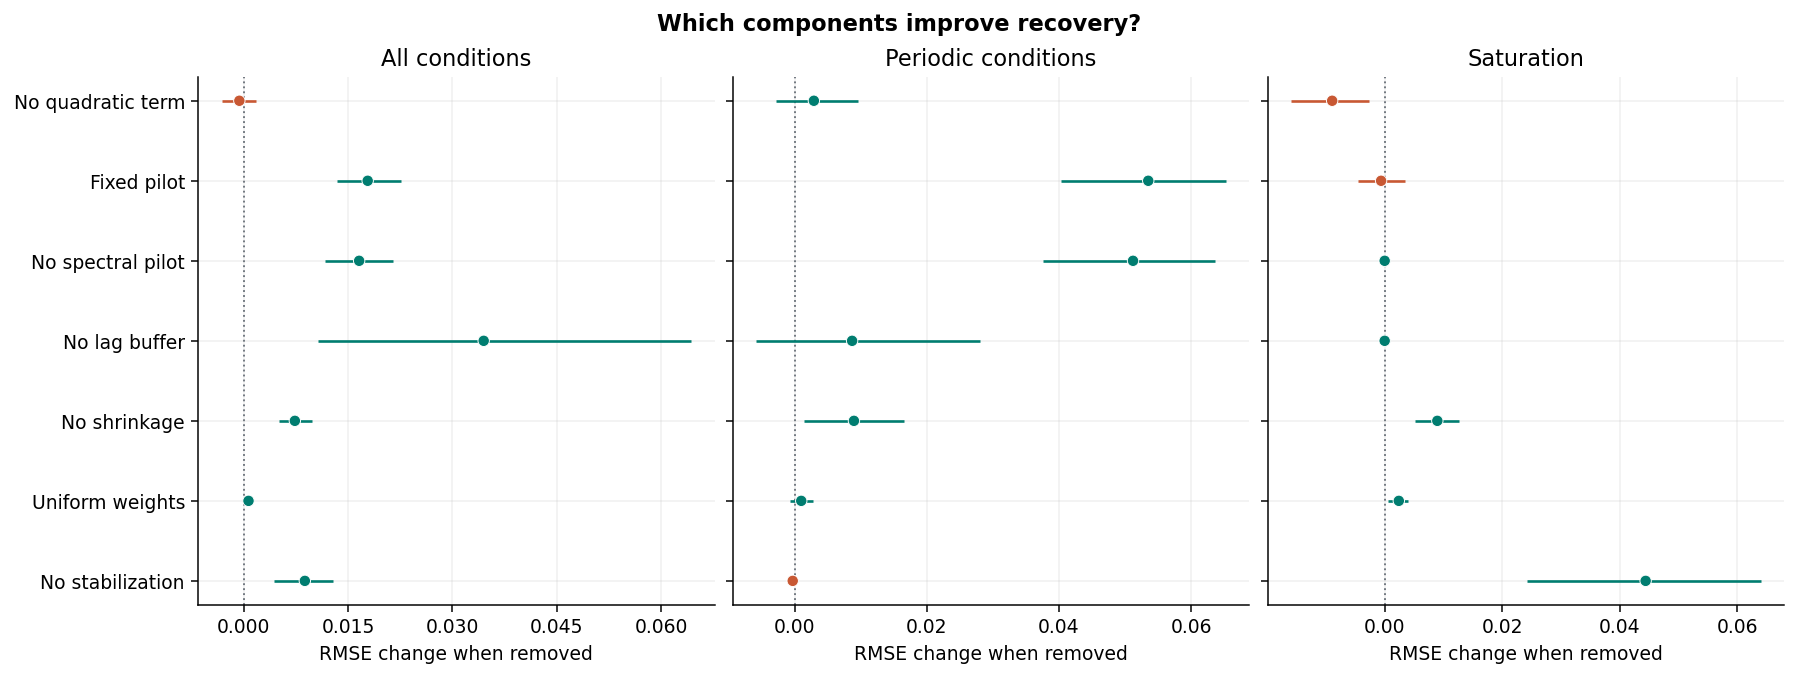

In [ ]:
# Paired changes in RMSE with bootstrap intervals
panels = (
    ("All conditions", ablation),
    ("Periodic conditions", ablation.loc[ablation["family"].isin(("Periodic", "Periodic + serial"))]),
    ("Saturation", ablation.loc[ablation["family"] == "Saturation"]),
)
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.9), layout="constrained", sharey=True)
positions = np.arange(len(ABLATIONS))
for k, (ax, (label, data)) in enumerate(zip(axes, panels)):
    result = paired_ablation(data, SEED + 503 + k)
    colors = np.where(result["delta"] >= 0, "#007D70", "#C85833")
    ax.axvline(0, color="#6D747C", linewidth=1, linestyle=":")
    ax.hlines(positions, result["lower"], result["upper"], color=colors, linewidth=1.4)
    ax.scatter(result["delta"], positions, c=colors, s=37, zorder=4, edgecolors="white", linewidths=0.5)
    ax.set(title=label, xlabel="RMSE change when removed", yticks=positions, yticklabels=ABLATIONS)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5))
axes[0].invert_yaxis()
fig.suptitle("Which components improve recovery?", fontweight="bold")
plt.show()


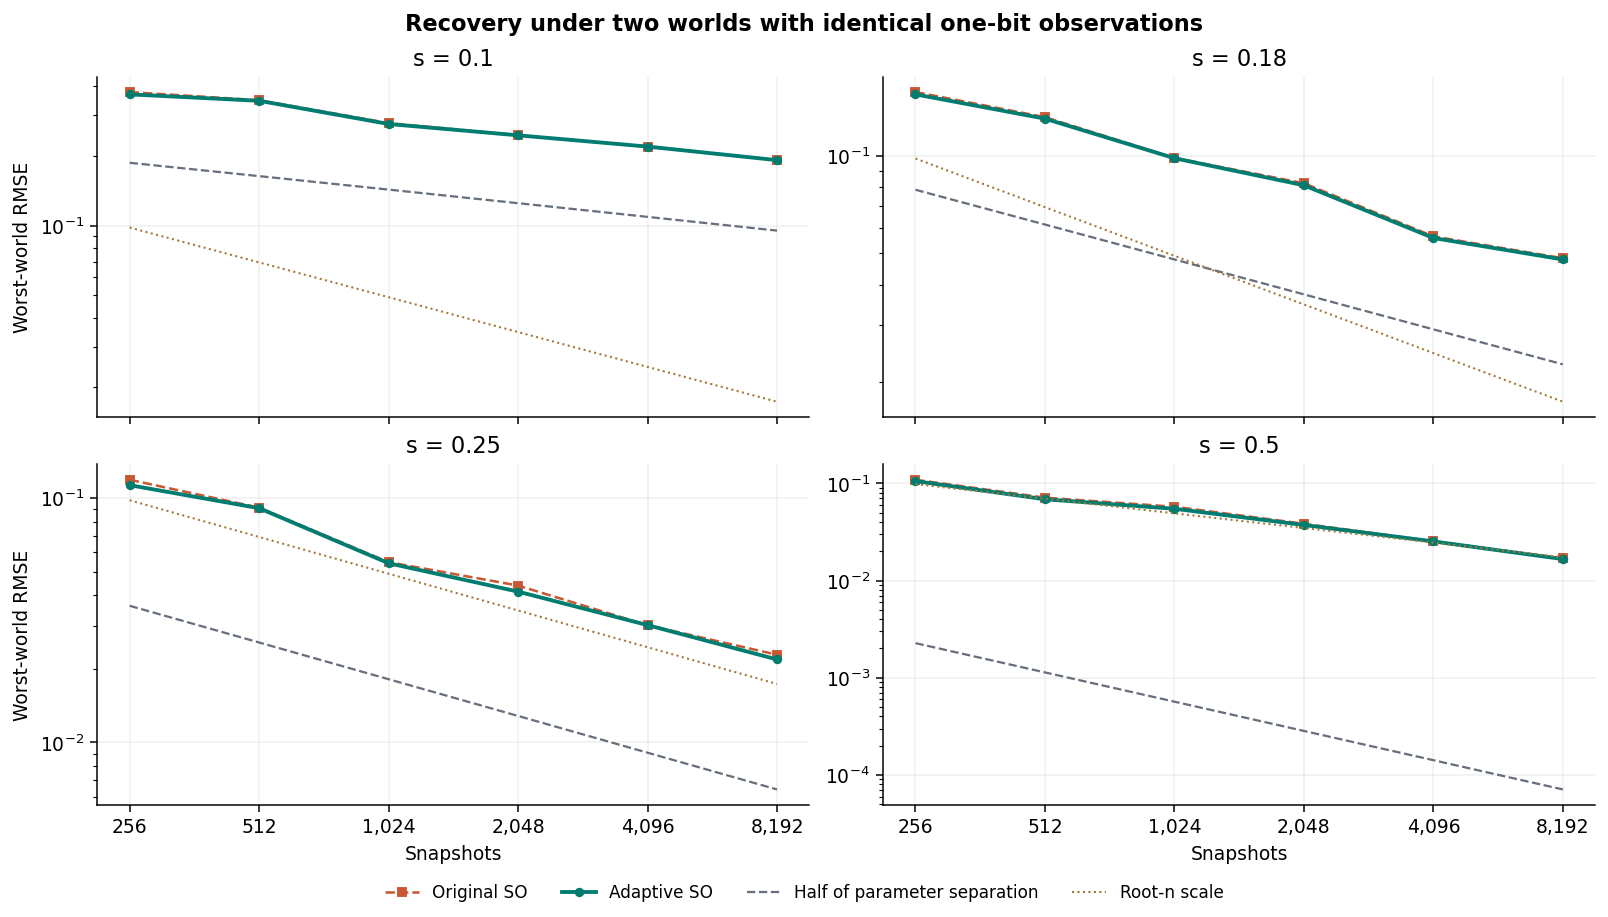

In [ ]:
# Empirical rate and the indistinguishable-world lower bound
rate_metrics = rate.groupby(["n", "s", "method"], as_index=False).agg(
    drift_rmse=("error_drift", rmse), fixed_rmse=("error_fixed", rmse),
    separation=("separation", "first"),
)
rate_metrics["worst_world_rmse"] = np.maximum(rate_metrics["drift_rmse"], rate_metrics["fixed_rmse"])
fig, axes = plt.subplots(2, 2, figsize=(11.8, 6.7), layout="constrained", sharex=True)
for ax, s in zip(axes.flat, sorted(rate_metrics["s"].unique())):
    for name in ("Original SO", "Adaptive SO"):
        series = rate_metrics.loc[(rate_metrics["s"] == s) & (rate_metrics["method"] == name)].sort_values("n")
        method_curve(ax, series["n"], series["worst_world_rmse"], name)
    ax.plot(series["n"], series["separation"] / 2, color="#666F7B", linewidth=1.2, linestyle="--",
            label="Half of parameter separation")
    ax.plot(series["n"], np.pi / (2 * np.sqrt(series["n"])), color="#A37938", linewidth=1.1,
            linestyle=":", label="Root-n scale")
    ax.set(title=f"s = {s:g}", xscale="log", yscale="log")
    ax.set_xticks(series["n"], [f"{n:,}" for n in series["n"]])
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
for ax in axes[:, 0]:
    ax.set_ylabel("Worst-world RMSE")
for ax in axes[-1]:
    ax.set_xlabel("Snapshots")
figure_key(fig, axes, 4)
fig.suptitle("Recovery under two worlds with identical one-bit observations", fontweight="bold")
plt.show()


In [ ]:
# Pairwise recovery for an array and nearest-correlation projection
def positive_projection(matrix, floor=0.0):
    eigenvalues, vectors = np.linalg.eigh((matrix + matrix.T) / 2)
    return (vectors * np.maximum(eigenvalues, floor)) @ vectors.T


def nearest_correlation(matrix, iterations=40, tol=1e-8):
    output = (matrix + matrix.T) / 2
    residual = np.zeros_like(output)
    for _ in range(iterations):
        shifted = output - residual
        positive = positive_projection(shifted)
        residual = positive - shifted
        previous = output
        output = positive.copy()
        np.fill_diagonal(output, 1.0)
        if np.linalg.norm(output - previous, ord="fro") < tol:
            break
    output = positive_projection(output, floor=1e-8)
    diagonal = np.sqrt(np.diag(output))
    return output / np.outer(diagonal, diagonal)


def estimate_array(bits, methods=("Pooled", "Original SO", "Adaptive SO")):
    bits = np.asarray(bits, dtype=float)
    if bits.ndim != 2 or bits.shape[1] < 2:
        raise ValueError("Expected n × channels with at least two channels.")
    channels = bits.shape[1]
    matrices = {name: np.eye(channels) for name in methods}
    unavailable = 0
    for i, j in combinations(range(channels), 2):
        pair = checked_bits(bits[:, [i, j]])
        if pair_status(pair) != "OK":
            unavailable += 1
            continue
        if "Pooled" in methods:
            matrices["Pooled"][i, j] = matrices["Pooled"][j, i] = pooled_estimate(pair)
        if "Original SO" in methods:
            fixed = prepare_moments(pair, block=8, gap=1, pilot="fixed")
            rho = MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho
            matrices["Original SO"][i, j] = matrices["Original SO"][j, i] = rho
        if "Adaptive SO" in methods:
            rho = fit_onebit(pair).rho
            matrices["Adaptive SO"][i, j] = matrices["Adaptive SO"][j, i] = rho
    return matrices, {name: nearest_correlation(value) for name, value in matrices.items()}, unavailable


def array_reference():
    theta = np.linspace(-1.25, 1.4, 6)
    loadings = np.column_stack((np.cos(theta), 0.93 * np.sin(theta), 0.46 * np.cos(2 * theta + 0.15)))
    raw = loadings @ loadings.T + 0.32 * np.eye(len(theta))
    scale = np.sqrt(np.diag(raw))
    return raw / np.outer(scale, scale)


def array_study(seed):
    rng = np.random.default_rng(seed)
    target = array_reference()
    n = 1800 if FULL else 720
    reps = 22 if FULL else 3
    rows, eigs, pairs = [], [], []
    _, true_vectors = np.linalg.eigh(target)
    true_space = true_vectors[:, -2:] @ true_vectors[:, -2:].T
    upper = np.triu_indices_from(target, k=1)
    for regime in ("Mixed drift", "Shared periodic", "Serial and loss"):
        for rep in range(reps):
            serial = 0.61 if regime == "Serial and loss" else 0.0
            analog = colored_normal(n, target, rng, ar=serial)
            t = (np.arange(n) + 0.5) / n
            if regime == "Shared periodic":
                carrier = 2 * np.pi * rng.uniform(17, 28) * t[:, None] + rng.uniform(0, 2 * np.pi)
                p = 0.5 + 0.23 * np.sin(carrier + np.linspace(0, 0.85, 6))
                p += 0.08 * np.cos(2 * np.pi * t[:, None] + np.linspace(0, 2.1, 6))
            else:
                names = ("Ramp", "Fast shared", "Steps", "Chirp", "Slow", "Multiscale")
                p = np.column_stack([drift_probabilities(name, n, rng)[:, j % 2] for j, name in enumerate(names)])
            bits = (analog <= special.ndtri(p)).astype(float)
            if serial:
                bits[rng.random(bits.shape) < 0.18] = np.nan
                bits[burst_mask(n, 0.14, rng), 3] = np.nan
            raw, projected, unavailable = estimate_array(bits)
            for name, estimate in projected.items():
                spectrum, vectors = np.linalg.eigh(estimate)
                fitted_space = vectors[:, -2:] @ vectors[:, -2:].T
                rows.append((regime, rep, name,
                             np.linalg.norm(estimate - target, ord="fro") / np.linalg.norm(target, ord="fro"),
                             np.linalg.norm(fitted_space - true_space, ord="fro") / 2,
                             np.linalg.eigvalsh(raw[name]).min(), unavailable))
                eigs.extend((regime, rep, name, k + 1, v) for k, v in enumerate(spectrum[::-1]))
                pairs.extend((regime, rep, name, x, y) for x, y in zip(target[upper], estimate[upper]))
                assert spectrum.min() >= -1e-10
                np.testing.assert_allclose(np.diag(estimate), 1.0, atol=1e-12)
    print(f"{3 * reps} array trials · 6 channels · {n:,} snapshots")
    return (pd.DataFrame(rows, columns=("regime", "rep", "method", "relative_error", "subspace_error",
                                        "raw_min_eigenvalue", "unavailable")),
            pd.DataFrame(eigs, columns=("regime", "rep", "method", "index", "eigenvalue")),
            pd.DataFrame(pairs, columns=("regime", "rep", "method", "truth", "estimate")))


array_results, array_eigs, array_pairs = array_study(SEED + 6000)


66 array trials · 6 channels · 1,800 snapshots


relative_matrix_error  subspace_error  \
regime          method                                               
Mixed drift     Adaptive SO                 0.0579          0.0321   
                Original SO                 0.0598          0.0330   
                Pooled                      0.1401          0.0521   
Serial and loss Adaptive SO                 0.0947          0.0510   
                Original SO                 0.1022          0.0484   
                Pooled                      0.1469          0.0721   
Shared periodic Adaptive SO                 0.0576          0.0333   
                Original SO                 0.0594          0.0336   
                Pooled                      0.2160          0.1275   

                             raw_non_psd  unavailable_pairs  
regime          method                                       
Mixed drift     Adaptive SO          0.0                  0  
                Original SO          0.0                  0  
                Pooled               0.0                  0  
Serial and loss Adaptive SO          0.0                  0  
                Original SO          0.0                  0  
                Pooled               0.0                  0  
Shared periodic Adaptive SO          0.0                  0  
                Original SO          0.0                  0  
                Pooled               0.0                  0

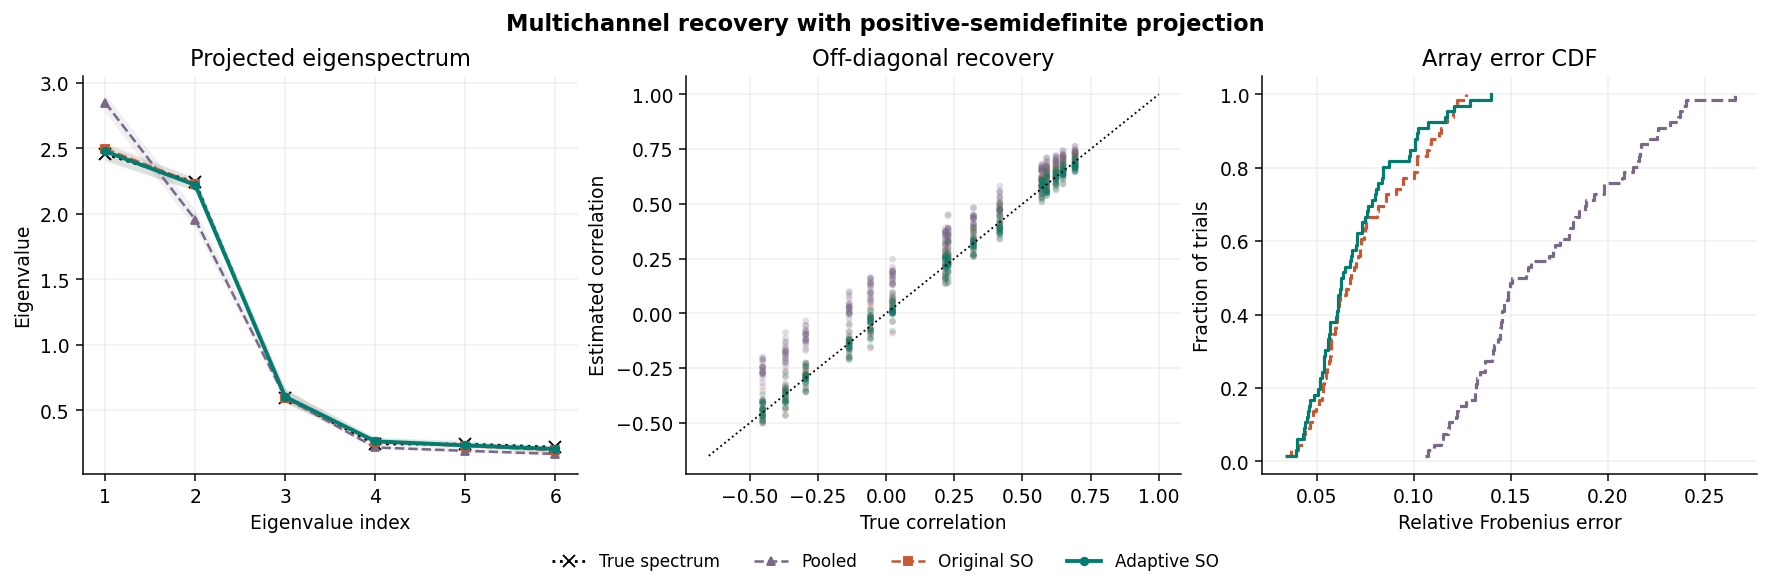

In [ ]:
# Array spectra and pairwise recovery
array_table = array_results.groupby(["regime", "method"]).agg(
    relative_matrix_error=("relative_error", "mean"), subspace_error=("subspace_error", "mean"),
    raw_non_psd=("raw_min_eigenvalue", lambda x: np.mean(x < -1e-8)),
    unavailable_pairs=("unavailable", "sum"),
)
display(array_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.25), layout="constrained")
regime = "Shared periodic"
spectrum = array_eigs.loc[array_eigs["regime"] == regime]
truth_eigen = np.linalg.eigvalsh(array_reference())[::-1]
axes[0].plot(np.arange(1, 7), truth_eigen, "k:", marker="x", label="True spectrum")
for name in ("Pooled", "Original SO", "Adaptive SO"):
    selected = spectrum.loc[spectrum["method"] == name].groupby("index")["eigenvalue"]
    method_curve(axes[0], np.arange(1, 7), selected.median(), name,
                 band=(selected.quantile(0.10), selected.quantile(0.90)))
axes[0].set(title="Projected eigenspectrum", xlabel="Eigenvalue index", ylabel="Eigenvalue", xticks=np.arange(1, 7))

for name in ("Pooled", "Original SO", "Adaptive SO"):
    selected = array_pairs.loc[(array_pairs["method"] == name) & (array_pairs["regime"] == regime)]
    axes[1].scatter(selected["truth"], selected["estimate"], c=PALETTE[name], s=13, alpha=0.22,
                    edgecolors="none")
axes[1].plot([-0.65, 1], [-0.65, 1], "k:", linewidth=1.0)
axes[1].set(title="Off-diagonal recovery", xlabel="True correlation", ylabel="Estimated correlation")

for name in ("Pooled", "Original SO", "Adaptive SO"):
    values = np.sort(array_results.loc[array_results["method"] == name, "relative_error"])
    axes[2].step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=PALETTE[name],
                 linestyle=LINESTYLES[name], linewidth=1.7)
axes[2].set(title="Array error CDF", xlabel="Relative Frobenius error", ylabel="Fraction of trials")
figure_key(fig, axes, 4)
fig.suptitle("Multichannel recovery with positive-semidefinite projection", fontweight="bold")
plt.show()


In [ ]:
# Packaged multichannel waveform with emulated one-bit comparators
# Source: https://matplotlib.org/3.0.2/gallery/specialty_plots/mri_with_eeg.html
def waveform_study(seed):
    sample = Path(mpl.get_data_path()) / "sample_data" / "eeg.dat"
    if not sample.is_file():
        print("This Matplotlib build omits its sample waveform.")
        return None, pd.DataFrame()
    waveform = np.fromfile(sample, dtype="<f8").reshape(-1, 4)
    waveform = (waveform - waveform.mean(axis=0)) / waveform.std(axis=0)
    rng = np.random.default_rng(seed)
    rows = []
    reps = 16 if FULL else 3
    target = np.corrcoef(waveform, rowvar=False)
    for pair in combinations(range(waveform.shape[1]), 2):
        truth = target[pair]
        for kind in ("Fixed offset", "Slow", "Fast shared", "Chirp", "Steps"):
            for rep in range(reps):
                p = drift_probabilities(kind, len(waveform), rng)
                threshold = special.ndtri(p)
                y = (waveform[:, pair] <= threshold).astype(float)
                fixed = prepare_moments(y, block=8, gap=1, pilot="fixed")
                values = {
                    "Pooled": pooled_estimate(y),
                    "Original SO": MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False).fit().rho,
                    "Adaptive SO": fit_onebit(y).rho,
                }
                for name, value in values.items():
                    rows.append((f"{pair[0] + 1}–{pair[1] + 1}", kind, rep, name, truth, value, value - truth))
    print(f"{len(rows) // 3} comparator perturbations of the same waveform · {len(waveform)} snapshots")
    return waveform, pd.DataFrame(rows, columns=("pair", "drift", "rep", "method", "truth", "estimate", "error"))


waveform, waveform_results = waveform_study(SEED + 7000)


480 comparator perturbations of the same waveform · 800 snapshots


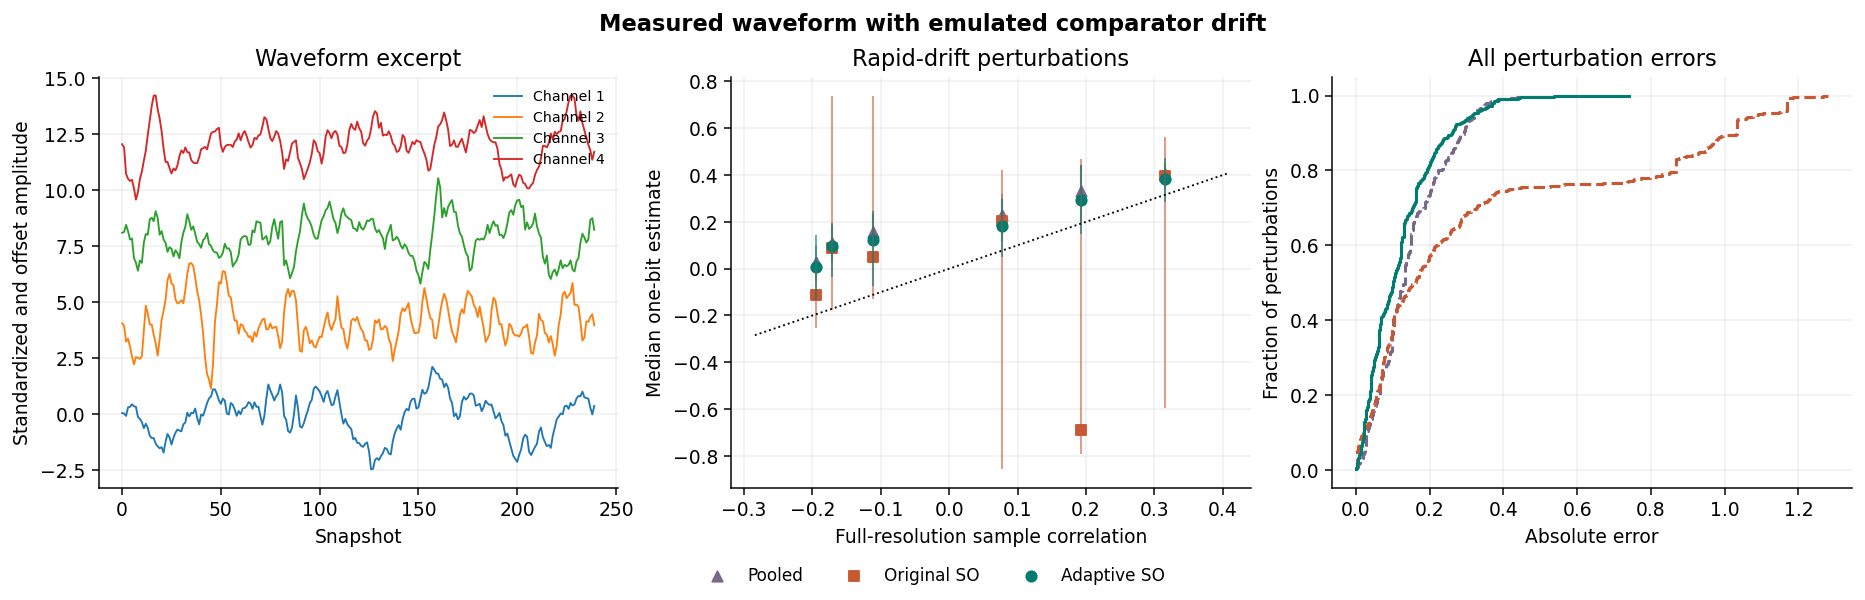

In [ ]:
# Waveform estimates against the high-resolution reference
if waveform is not None:
    fig, axes = plt.subplots(1, 3, figsize=(13.7, 4.35), layout="constrained")
    for k, col in enumerate(waveform.T):
        axes[0].plot(np.arange(240), col[:240] + 4.0 * k, linewidth=1.0,
                     label=f"Channel {k + 1}")
    axes[0].set(title="Waveform excerpt", xlabel="Snapshot", ylabel="Standardized and offset amplitude")
    axes[0].legend(fontsize=7.5, loc="upper right")

    focus = waveform_results.loc[waveform_results["drift"].isin(("Fast shared", "Chirp"))]
    for name in ("Pooled", "Original SO", "Adaptive SO"):
        sample = focus.loc[focus["method"] == name]
        med = sample.groupby("truth")["estimate"].median()
        low = sample.groupby("truth")["estimate"].quantile(0.10)
        high = sample.groupby("truth")["estimate"].quantile(0.90)
        axes[1].vlines(med.index, low, high, color=PALETTE[name], alpha=0.58, linewidth=1.1)
        axes[1].scatter(med.index, med, color=PALETTE[name], marker=MARKERS[name], s=30, label=name)
        values = np.sort(waveform_results.loc[waveform_results["method"] == name, "error"].abs())
        axes[2].step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=PALETTE[name],
                     linestyle=LINESTYLES[name], linewidth=1.65)
    bounds = [focus["truth"].min() - 0.09, focus["truth"].max() + 0.09]
    axes[1].plot(bounds, bounds, "k:", linewidth=1.0)
    axes[1].set(title="Rapid-drift perturbations", xlabel="Full-resolution sample correlation",
                ylabel="Median one-bit estimate")
    axes[2].set(title="All perturbation errors", xlabel="Absolute error", ylabel="Fraction of perturbations")
    figure_key(fig, [axes[1]], 3)
    fig.suptitle("Measured waveform with emulated comparator drift", fontweight="bold")
    plt.show()


In [ ]:
# Compound stress and near-boundary correlations
CHALLENGE_REPS = 16 if FULL else 3
challenge_cases = [
    Scenario(family="Chirp with serial dependence", drift="Chirp", n=n, rho=rho,
             level=ar, ar=ar)
    for n, rho, ar in product(STRESS_N, (-0.62, 0.62), (0.25, 0.55, 0.82))
] + [
    Scenario(family="Chirp with serial dependence and loss", drift="Chirp", n=n, rho=rho,
             level=ar, ar=ar, dropout=0.30)
    for n, rho, ar in product(STRESS_N, (-0.62, 0.62), (0.25, 0.55, 0.82))
] + [
    Scenario(family="Near correlation boundary", drift=drift, n=n, rho=rho)
    for n, rho, drift in product(STRESS_N, (-0.96, -0.92, 0.92, 0.96), ("Fast shared", "Ramp"))
]
challenge = benchmark(challenge_cases, CHALLENGE_REPS, BENCHMARK_SEED + 5000, compact=True)


10/40 settings complete
20/40 settings complete
30/40 settings complete
40 settings · 640 trials · 19.9 s


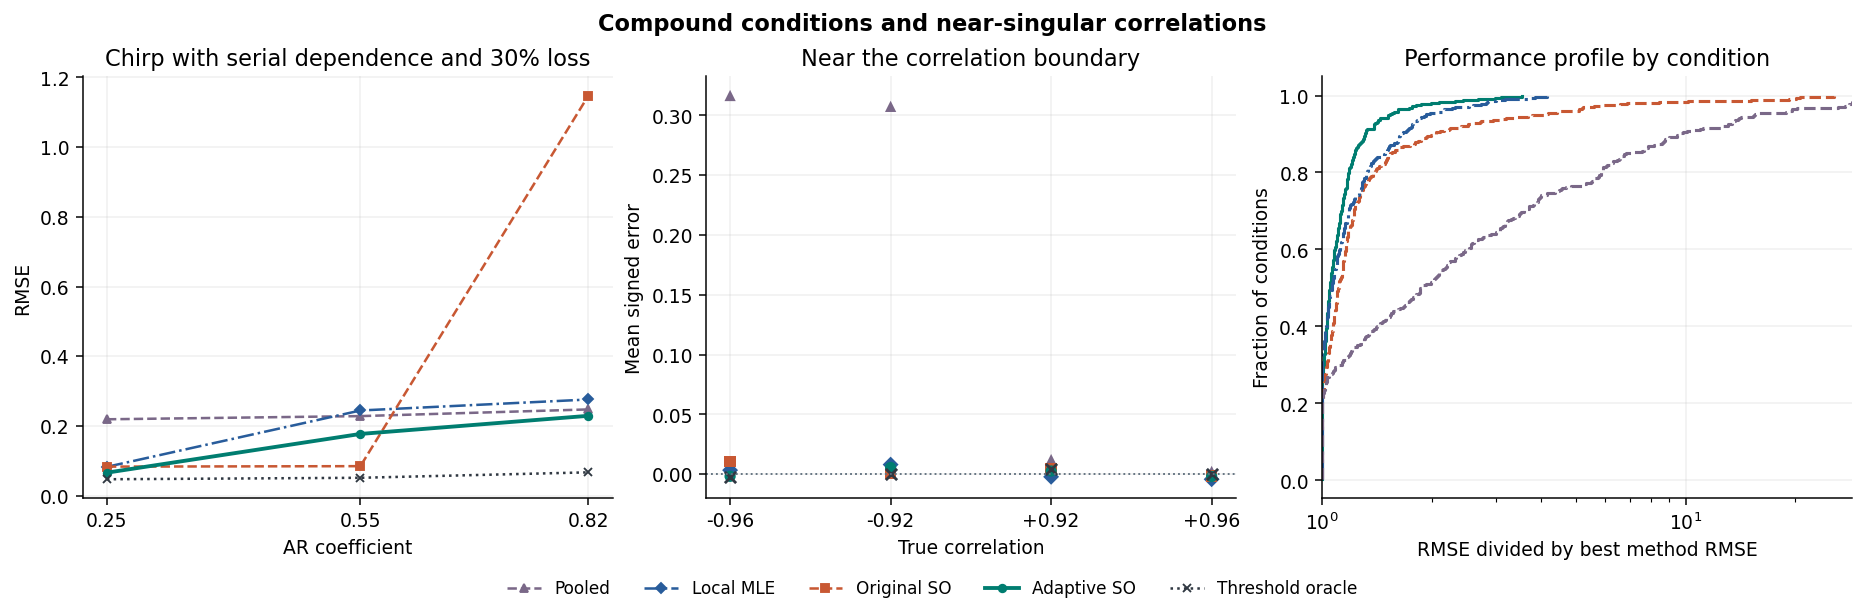

In [ ]:
# Difficult cases and condition-level performance profiles
fig, axes = plt.subplots(1, 3, figsize=(13.7, 4.45), layout="constrained")
focus = challenge.loc[challenge["family"] == "Chirp with serial dependence and loss"]
serial_chirp = empirical_metrics(focus, ["level", "method"])
endpoints = empirical_metrics(challenge.loc[challenge["family"] == "Near correlation boundary"],
                              ["truth", "method"])
near_boundary = np.sort(endpoints["truth"].unique())
for name in PRIMARY:
    a = serial_chirp.loc[serial_chirp["method"] == name].sort_values("level")
    b = endpoints.loc[endpoints["method"] == name].sort_values("truth")
    method_curve(axes[0], a["level"], a["rmse"], name)
    axes[1].scatter(np.searchsorted(near_boundary, b["truth"]), b["bias"],
                    color=PALETTE[name], s=36, marker=MARKERS[name],
                    edgecolors="none" if MARKERS[name] != "x" else None)
axes[0].set(title="Chirp with serial dependence and 30% loss", xlabel="AR coefficient", ylabel="RMSE",
            xticks=[0.25, 0.55, 0.82])
axes[1].axhline(0, linestyle=":", color="#60707E", linewidth=1.0)
axes[1].set(title="Near the correlation boundary", xlabel="True correlation", ylabel="Mean signed error",
            xticks=np.arange(len(near_boundary)), xticklabels=[f"{x:+.2f}" for x in near_boundary])

condition_methods = ("Adaptive SO", "Original SO", "Local MLE", "Pooled")
all_conditions = pd.concat((core, stress, challenge), ignore_index=True)
condition_rmse = empirical_metrics(
    all_conditions.loc[all_conditions["method"].isin(condition_methods)],
    ["family", "drift", "level", "n", "truth", "method"],
).pivot(index=["family", "drift", "level", "n", "truth"], columns="method", values="rmse").dropna()
ratio = condition_rmse.div(condition_rmse.min(axis=1).clip(lower=1e-12), axis=0)
for name in condition_methods:
    sorted_ratio = np.sort(ratio[name])
    axes[2].step(sorted_ratio, np.arange(1, len(sorted_ratio) + 1) / len(sorted_ratio),
                 where="post", color=PALETTE[name], linestyle=LINESTYLES[name], linewidth=1.65)
axes[2].set(title="Performance profile by condition", xlabel="RMSE divided by best method RMSE",
            ylabel="Fraction of conditions", xscale="log", xlim=(1, max(2, ratio.quantile(.98).max())))
figure_key(fig, axes, 5)
fig.suptitle("Compound conditions and near-singular correlations", fontweight="bold")
plt.show()


In [ ]:
# Direct-use example
bits_demo, _, _ = simulate(Scenario(n=3072, rho=0.52, drift="Fast shared", dropout=0.12), SEED + 809)
result = fit_onebit(bits_demo)
print(f"Correlation {result.rho:.4f} · nominal 95% interval [{result.lower:.4f}, {result.upper:.4f}]")
print(f"Selected lag {result.gap} · block {result.block} · {result.status}")
trial_count = (len(core_cases) * CORE_REPS + len(stress_cases) * STRESS_REPS
               + len(ablation_cases) * ABLATION_REPS + len(challenge_cases) * CHALLENGE_REPS)
rate_count = rate[["n", "s", "rep"]].drop_duplicates().shape[0]
print(f"{trial_count:,} benchmark trials · {rate_count:,} rate-study draws")


Correlation 0.4998 · nominal 95% interval [0.4376, 0.5620]
Selected lag 1 · block 8 · OK
6,780 benchmark trials · 912 rate-study draws


In [ ]:
# Independent holdout and serial-with-loss comparisons
spl_holdout = holdout_benchmark(SPL_SEED + 2000)
assert spl_holdout["estimate"].notna().all()


12/36 holdout settings complete
24/36 holdout settings complete
36/36 holdout settings complete
480 matched holdout trials in 49.0 s


In [ ]:
# Held-out accuracy, paired effects, and computational cost
holdout_rmse = empirical_metrics(spl_holdout, ["regime", "method"]).pivot(
    index="method", columns="regime", values="rmse").reindex(SPL_METHODS)
holdout_rmse["Median CPU ms"] = spl_holdout.groupby("method")["cpu_ms"].median()
holdout_rmse["Optimizer success (%)"] = 100 * spl_holdout.groupby("method")["converged"].mean()
display(holdout_rmse.round(4))
holdout_independent = spl_holdout.loc[spl_holdout["regime"] == "Independent"]
holdout_effects = paired_rmse_intervals(
    holdout_independent, ("Adaptive SO", "Original SO", "First order", "Local MLE", "Spline joint MLE"),
    seed=SPL_SEED + 10,
)
display(holdout_effects.set_index("baseline").round(2))
coverage = holdout_independent.loc[holdout_independent.method.eq("Adaptive SO"), "coverage"].astype(float)
print(f"Independent-trial interval coverage {coverage.mean():.1%}")


regime,Independent,Serial and loss,Median CPU ms,Optimizer success (%)
method,,,,
First order,0.1110,0.1704,15.6003,100.0
Local MLE,0.1110,0.1725,15.2055,100.0
Spline joint MLE,0.0946,0.1130,80.2865,100.0
Original SO,0.0588,0.0693,2.0957,100.0
Adaptive SO,0.0626,0.1456,16.6860,100.0
Threshold oracle,0.0385,0.0527,2.5995,100.0


,RMSE reduction (%),95% lower,95% upper,settings won,settings
baseline,,,,,
Original SO,-6.42,-14.79,1.31,11,24
First order,43.62,39.14,48.06,23,24
Local MLE,43.61,39.18,48.02,23,24
Spline joint MLE,33.83,28.32,39.76,24,24


Independent-trial interval coverage 90.6%


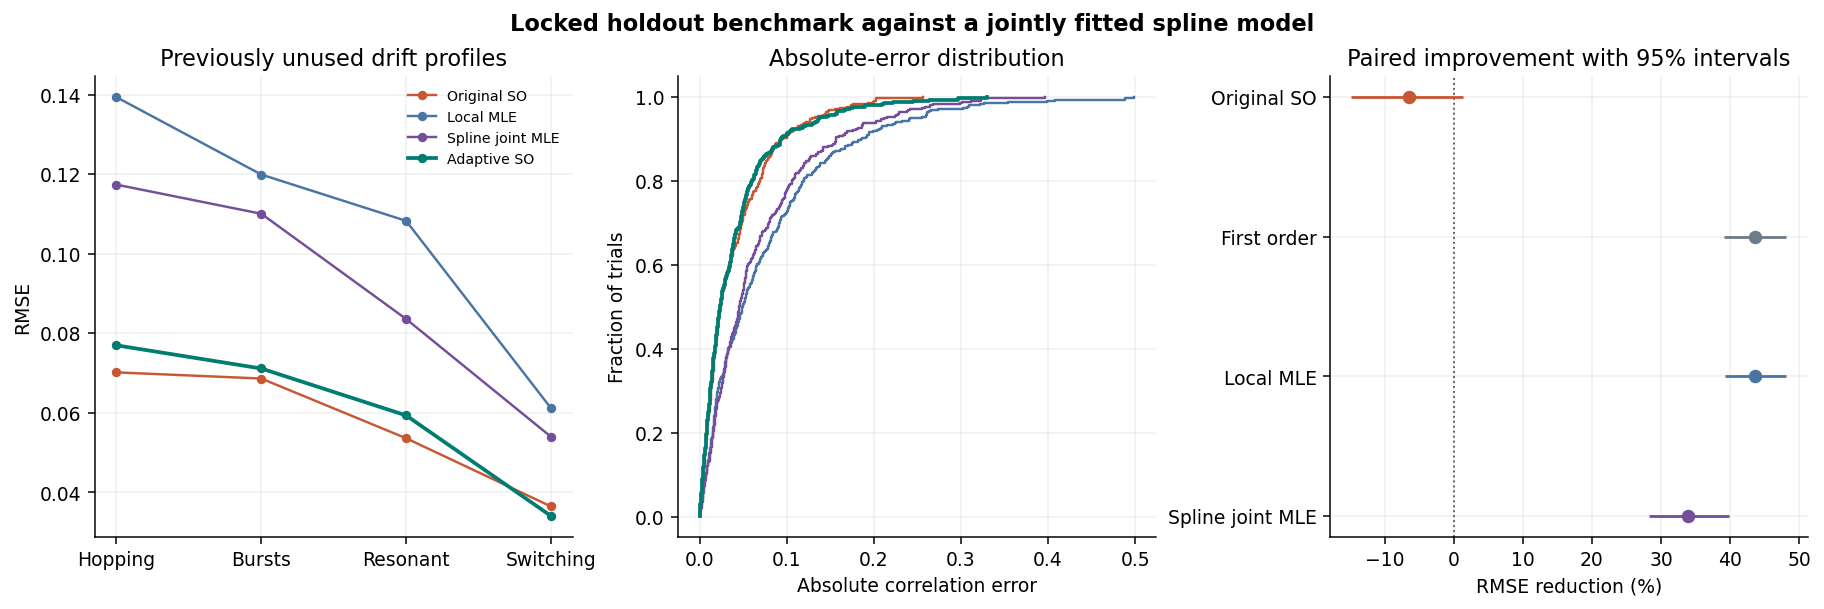

In [ ]:
# Distribution of paired performance on the fresh holdout
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.4), layout="constrained")
family_rmse = empirical_metrics(holdout_independent, ["family", "method"])
selected = ("Original SO", "Local MLE", "Spline joint MLE", "Adaptive SO")
for name in selected:
    m = family_rmse.loc[family_rmse.method.eq(name)].set_index("family").reindex(SPL_FAMILIES)
    axes[0].plot(np.arange(len(m)), m.rmse, marker="o", markersize=4, color=SPL_COLORS[name],
                 label=name, linewidth=2 if name == "Adaptive SO" else 1.3)
axes[0].set(title="Previously unused drift profiles", ylabel="RMSE", xticks=np.arange(4),
            xticklabels=("Hopping", "Bursts", "Resonant", "Switching"))
axes[0].legend(fontsize=7.5)
for name in selected:
    values = np.sort(holdout_independent.loc[holdout_independent.method.eq(name), "error"].abs().to_numpy())
    axes[1].step(values, np.arange(1, len(values) + 1) / len(values), where="post",
                 color=SPL_COLORS[name], linewidth=2 if name == "Adaptive SO" else 1.3)
axes[1].set(title="Absolute-error distribution", xlabel="Absolute correlation error", ylabel="Fraction of trials")
y = np.arange(len(holdout_effects))
axes[2].axvline(0, color="#555D66", linewidth=1, linestyle=":")
for k, row in holdout_effects.iterrows():
    color = SPL_COLORS[row["baseline"]]
    axes[2].hlines(k, row["95% lower"], row["95% upper"], color=color, linewidth=1.5)
    axes[2].scatter(row["RMSE reduction (%)"], k, color=color, s=38, zorder=3)
axes[2].set(title="Paired improvement with 95% intervals", xlabel="RMSE reduction (%)", yticks=y,
            yticklabels=holdout_effects["baseline"])
axes[2].invert_yaxis()
fig.suptitle("Locked holdout benchmark against a jointly fitted spline model", fontweight="bold")
plt.show()


In [ ]:
# Selection-adjusted second-order scores with calibrated logging probabilities
def corrected_packets(bits, inclusion, *, augment=True):
    bits = checked_bits(bits)
    p = np.asarray(inclusion, dtype=float)
    if p.shape != (4,) or not np.all(np.isfinite(p) & (p > 0) & (p <= 1)):
        raise ValueError("Supply four inclusion probabilities in (0, 1] in order 00, 10, 01, 11.")
    if np.isnan(bits[:, 0]).any():
        raise ValueError("The first bit and the second-bit presence flag are required at each snapshot.")
    a = bits[:, 0].astype(int)
    complete = np.isfinite(bits[:, 1])
    if augment:
        odds = 1.0 / p - 1.0
        total = odds[:2] + odds[2:]
        center = np.divide(odds[2:], total, out=np.full(2, 0.5), where=total > 0)
    else:
        center = np.zeros(2)
    proxy = center[a].copy()
    b = bits[complete, 1]
    observed_probability = p[a[complete] + 2 * b.astype(int)]
    proxy[complete] += (b - proxy[complete]) / observed_probability
    return np.column_stack((a, proxy))


def fit_selection_adjusted(bits, inclusion, *, augment=True, gap=1):
    pseudo = corrected_packets(bits, inclusion, augment=augment)
    status = pair_status(np.asarray(bits, dtype=float))
    if status != "OK":
        return Estimate(np.nan, -RHO_LIMIT, RHO_LIMIT, status=status)
    moments = prepare_moments(pseudo, gap=gap)
    return MomentEstimator(moments, weighted=False, stabilize=False).fit(interval=True)


def logged_mass(latent_mass, inclusion):
    observed = latent_mass * inclusion
    missing = latent_mass - observed
    return observed, missing[:2] + missing[2:]


def correlation_from_mass(mass):
    p = np.array([[mass[1] + mass[3], mass[2] + mass[3]]])
    q = float(mass[3])
    lo = max(0.0, p.sum() - 1.0)
    hi = float(p.min())
    if q <= lo + 1e-12:
        return -1.0
    if q >= hi - 1e-12:
        return 1.0
    link = BinaryLink(p, clip=False)
    limit = 1 - 1e-8
    return float(optimize.brentq(lambda r: q - link.coincidence(r).item(), -limit, limit))


def feasible_correlation_bounds(observed, missing, lower, upper):
    min_latent = observed / upper
    max_latent = np.divide(observed, lower, out=np.full(4, np.inf), where=lower > 0)
    low = np.maximum.reduce((np.zeros(2), min_latent[2:] - observed[2:],
                             missing + observed[:2] - max_latent[:2]))
    high = np.minimum.reduce((missing, max_latent[2:] - observed[2:],
                              missing + observed[:2] - min_latent[:2]))
    if np.any(low > high + 1e-11):
        raise ValueError("Calibration ranges and the logged probabilities are incompatible.")
    low = np.minimum(low, high)
    allocations = np.array([[high[0], low[1]], [low[0], high[1]]])
    masses = np.concatenate((observed[:2] + missing - allocations, observed[2:] + allocations), axis=1)
    return np.array([correlation_from_mass(mass) for mass in masses]), masses


def selection_identification_example():
    p = np.array([[0.42, 0.58]])
    rho = 0.52
    latent = cell_probabilities(p, BinaryLink(p).coincidence(rho))[0]
    inclusion = np.array([0.95, 0.77, 0.68, 0.34])
    observed, missing = logged_mass(latent, inclusion)
    unrestricted, alternatives = feasible_correlation_bounds(observed, missing, np.zeros(4), np.ones(4))
    for alternative in alternatives:
        comparable = logged_mass(alternative, observed / alternative)
        np.testing.assert_allclose(comparable[0], observed, atol=1e-12)
        np.testing.assert_allclose(comparable[1], missing, atol=1e-12)
    exact, _ = feasible_correlation_bounds(observed, missing, inclusion, inclusion)
    np.testing.assert_allclose(exact, [rho, rho], atol=1e-10)
    return observed, missing, inclusion, rho, unrestricted


selection_example = selection_identification_example()
print("Passed: two different latent correlations generate the same distribution of recorded bits and loss flags.")


Passed: two different latent correlations generate the same distribution of recorded bits and loss flags.


In [ ]:
# Calibrated selection benchmark
def selection_benchmark(seed):
    n = 1800 if SPL_FULL else 650
    reps = 15 if SPL_FULL else 2
    families = ("Frequency hopping", "Resonant random drift", "Slow")
    settings = list(product(families, (-0.64, 0.64), (0.0, 0.40, 0.72, 1.0)))
    rows = []
    started = perf_counter()
    for (family, rho, severity), child in zip(settings, np.random.SeedSequence(seed).spawn(len(settings))):
        inclusion = 1.0 - severity * np.array([0.05, 0.23, 0.32, 0.66])
        wrong = 1.0 - 0.72 * (1.0 - inclusion)
        for rep, trial_seed in enumerate(child.spawn(reps)):
            rng = np.random.default_rng(trial_seed)
            p = (drift_probabilities(family, n, rng) if family == "Slow"
                 else holdout_thresholds(family, n, rng))
            analog = colored_normal(n, np.array([[1.0, rho], [rho, 1.0]]), rng)
            full = (analog <= special.ndtri(p)).astype(float)
            category = (full[:, 0] + 2 * full[:, 1]).astype(int)
            lost = rng.random(n) > inclusion[category]
            bits = full.copy()
            bits[lost, 1] = np.nan
            fits = {
                "Complete cases": fit_onebit(bits, gap=1),
                "Inverse weighting": fit_selection_adjusted(bits, inclusion, augment=False),
                "Calibrated loss": fit_selection_adjusted(bits, inclusion),
                "Misspecified calibration": fit_selection_adjusted(bits, wrong),
                "All bits": fit_onebit(full, gap=1),
            }
            for name, fit in fits.items():
                rows.append({"family": family, "truth": rho, "severity": severity, "rep": rep,
                             "method": name, "error": fit.rho - rho,
                             "coverage": fit.lower <= rho <= fit.upper, "lost": lost.mean()})
    print(f"{len(settings) * reps} selection trials in {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows)


selection_results = selection_benchmark(SPL_SEED + 3000)
assert selection_results.error.notna().all()


360 selection trials in 34.4 s


,RMSE,bias,coverage
method,,,
All bits,0.0330,0.0006,0.9556
Calibrated loss,0.0394,-0.0014,0.9667
Complete cases,0.1313,-0.1200,0.2222
Inverse weighting,0.0758,0.0164,0.9556
Misspecified calibration,0.0680,-0.0058,0.6667


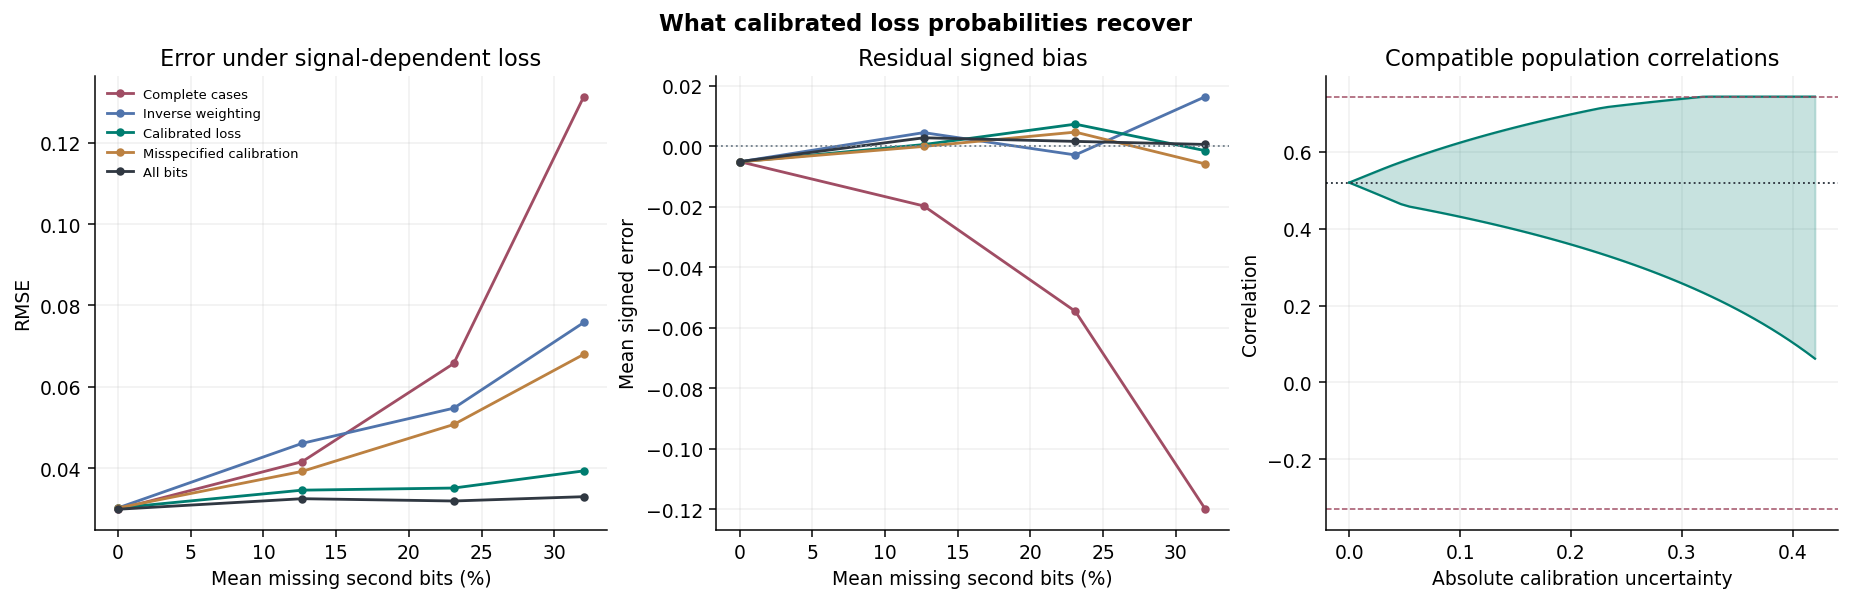

In [ ]:
# Calibration sensitivity and observational equivalence
selection_metrics = empirical_metrics(selection_results, ["severity", "method"])
worst = selection_results.loc[selection_results.severity.eq(1.0)]
worst_table = worst.groupby("method").agg(RMSE=("error", rmse), bias=("error", "mean"),
                                         coverage=("coverage", "mean"))
display(worst_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.35), layout="constrained")
selection_colors = {**SPL_COLORS, "All bits": "#303842", "Inverse weighting": "#5074AC"}
selection_labels = ("Complete cases", "Inverse weighting", "Calibrated loss",
                    "Misspecified calibration", "All bits")
mean_loss = selection_results.groupby("severity")["lost"].mean()
for name in selection_labels:
    sub = selection_metrics.loc[selection_metrics.method.eq(name)].sort_values("severity")
    x = 100 * mean_loss.loc[sub.severity].to_numpy()
    axes[0].plot(x, sub.rmse, color=selection_colors[name], label=name, marker="o", markersize=3.5)
    axes[1].plot(x, sub.bias, color=selection_colors[name], marker="o", markersize=3.5)
axes[0].set(title="Error under signal-dependent loss", xlabel="Mean missing second bits (%)", ylabel="RMSE")
axes[1].axhline(0, color="#75828E", linestyle=":", linewidth=1.0)
axes[1].set(title="Residual signed bias", xlabel="Mean missing second bits (%)", ylabel="Mean signed error")
axes[0].legend(fontsize=7.0)

observed, missing, known, true_rho, unrestricted = selection_example
widths = np.linspace(0, 0.42, 55)
limits = np.array([feasible_correlation_bounds(observed, missing, np.maximum(0.0, known - w),
                                               np.minimum(1.0, known + w))[0] for w in widths])
axes[2].fill_between(widths, limits[:, 0], limits[:, 1], alpha=0.22, color=SPL_COLORS["Calibrated loss"])
axes[2].plot(widths, limits, color=SPL_COLORS["Calibrated loss"], linewidth=1.2)
axes[2].axhline(true_rho, color="#303842", linestyle=":", linewidth=1.0, label="True correlation")
for bound in unrestricted:
    axes[2].axhline(bound, color="#A04D64", linestyle="--", linewidth=0.8)
axes[2].set(title="Compatible population correlations", xlabel="Absolute calibration uncertainty",
            ylabel="Correlation")
fig.suptitle("What calibrated loss probabilities recover", fontweight="bold")
plt.show()


In [ ]:
# Thermal replay using measured comparator group coefficients
# Iwata, Kitamura, and Islam, ICMTS 2023, Table I.
# https://mahfuz.design/wp-content/uploads/2023/03/c_iwata_icmts_2023.pdf
# The coefficients are measured group means. Temperatures and bits are generated offline.
THERMAL_SOURCE = "https://mahfuz.design/wp-content/uploads/2023/03/c_iwata_icmts_2023.pdf"
MEASURED_SLOPE_UV_C = {"Symmetric": 8.0, "Left-skewed": -94.0, "Right-skewed": 107.0}
THERMAL_PAIRS = {
    "Symmetric pair": ("Symmetric", "Symmetric"),
    "Left-skewed pair": ("Left-skewed", "Left-skewed"),
    "Right-skewed pair": ("Right-skewed", "Right-skewed"),
    "Opposing pair": ("Left-skewed", "Right-skewed"),
}
THERMAL_PROTOCOLS = ("Temperature sweep", "Two thermal cycles")
THERMAL_LEVELS = (4.0, 10.0, 25.0)
THERMAL_METHODS = ("Pooled tetrachoric", "Matched first order", "Fixed-block second order",
                   "Joint spline likelihood", "Known-threshold oracle")
THERMAL_COLORS = {
    "Pooled tetrachoric": "#8B6889", "Matched first order": "#A04D64",
    "Fixed-block second order": "#007D70", "Joint spline likelihood": "#4975A4",
    "Known-threshold oracle": "#303842",
}


def thermal_thresholds(n, device_pair, protocol):
    t = np.linspace(0.0, 1.0, n)
    if protocol == "Temperature sweep":
        temperature = -20.0 + 100.0 * t
    elif protocol == "Two thermal cycles":
        temperature = 30.0 - 50.0 * np.cos(4.0 * np.pi * t)
    else:
        raise ValueError(f"Unrecognized protocol {protocol!r}.")
    slope = np.array([MEASURED_SLOPE_UV_C[device] for device in THERMAL_PAIRS[device_pair]])
    # Remove the static room-temperature offset at 20 °C.
    offset_mv = (temperature[:, None] - 20.0) * slope[None, :] / 1000.0
    return temperature, offset_mv


for profile in THERMAL_PAIRS:
    temperature, offset_mv = thermal_thresholds(101, profile, THERMAL_PROTOCOLS[0])
    np.testing.assert_allclose(offset_mv[40], 0.0, atol=1e-12)
    np.testing.assert_allclose((offset_mv[-1] - offset_mv[0]) * 10,
                               [MEASURED_SLOPE_UV_C[d] for d in THERMAL_PAIRS[profile]])
assert thermal_thresholds(401, "Opposing pair", "Two thermal cycles")[0].max() == 80.0


def thermal_estimators(bits):
    fixed = fixed_block_moments(bits)
    first = MomentEstimator(fixed, order=1, weighted=False, shrink=False, stabilize=False)
    second = MomentEstimator(fixed, weighted=False, shrink=False, stabilize=False)
    spline = tuned_spline_probit(bits)
    return {
        "Pooled tetrachoric": pooled_estimate(bits),
        "Matched first order": first.fit().rho,
        "Fixed-block second order": second.fit().rho,
        "Joint spline likelihood": spline.rho,
    }, spline.converged


In [ ]:
# Matched thermal replay with known Gaussian reference correlations
def thermal_benchmark(seed):
    sizes = (768, 3072) if PROFILE == "full" else (384, 768)
    repetitions = 6 if PROFILE == "full" else 1
    settings = list(product(THERMAL_PAIRS, THERMAL_PROTOCOLS, THERMAL_LEVELS,
                            sizes, (-0.65, 0.0, 0.65)))
    rows = []
    started = perf_counter()
    for index, (case, child) in enumerate(zip(settings, np.random.SeedSequence(seed).spawn(len(settings)))):
        device_pair, protocol, sigma, n, rho = case
        _, threshold = thermal_thresholds(n, device_pair, protocol)
        p = special.ndtr(threshold / sigma)
        for rep, trial_seed in enumerate(child.spawn(repetitions)):
            rng = np.random.default_rng(trial_seed)
            analog = sigma * colored_normal(n, np.array([[1, rho], [rho, 1]]), rng)
            bits = (analog <= threshold).astype(float)
            estimates, converged = thermal_estimators(bits)
            estimates["Known-threshold oracle"] = threshold_oracle(bits, p, GAUSSIAN)
            for name, value in estimates.items():
                rows.append({"regime": "Thermal replay", "family": f"{device_pair} / {protocol} / {sigma:g}",
                             "pair": device_pair, "protocol": protocol, "rms_mv": sigma,
                             "n": n, "truth": rho, "rep": rep, "method": name,
                             "estimate": value, "error": value - rho,
                             "converged": converged if name == "Joint spline likelihood" else True})
        if (index + 1) % 36 == 0:
            print(f"{index + 1}/{len(settings)} thermal settings complete", flush=True)
    print(f"{len(settings) * repetitions:,} matched replay trials in {perf_counter() - started:.1f} s")
    return pd.DataFrame(rows)


thermal_results = thermal_benchmark(196633)
assert thermal_results.estimate.notna().all()


36/144 thermal settings complete
72/144 thermal settings complete
108/144 thermal settings complete
144/144 thermal settings complete
864 matched replay trials in 75.7 s


,4 mV RMS,10 mV RMS,25 mV RMS,Overall RMSE,RMSE reduction (%),95% lower,95% upper,settings won,settings
method,,,,,,,,,
Fixed-block second order,0.0525,0.0431,0.0395,0.0453,NaN,NaN,NaN,NaN,NaN
Matched first order,0.0494,0.0429,0.0404,0.0444,-2.0759,-6.5381,2.2103,69.0,144.0
Joint spline likelihood,0.0487,0.0410,0.0374,0.0426,-6.3363,-10.1291,-2.9428,48.0,144.0
Pooled tetrachoric,0.4573,0.1072,0.0408,0.2722,83.3438,82.2767,84.4120,102.0,144.0
Known-threshold oracle,0.0473,0.0402,0.0366,0.0416,NaN,NaN,NaN,NaN,NaN


Joint spline optimizer convergence 100.0%


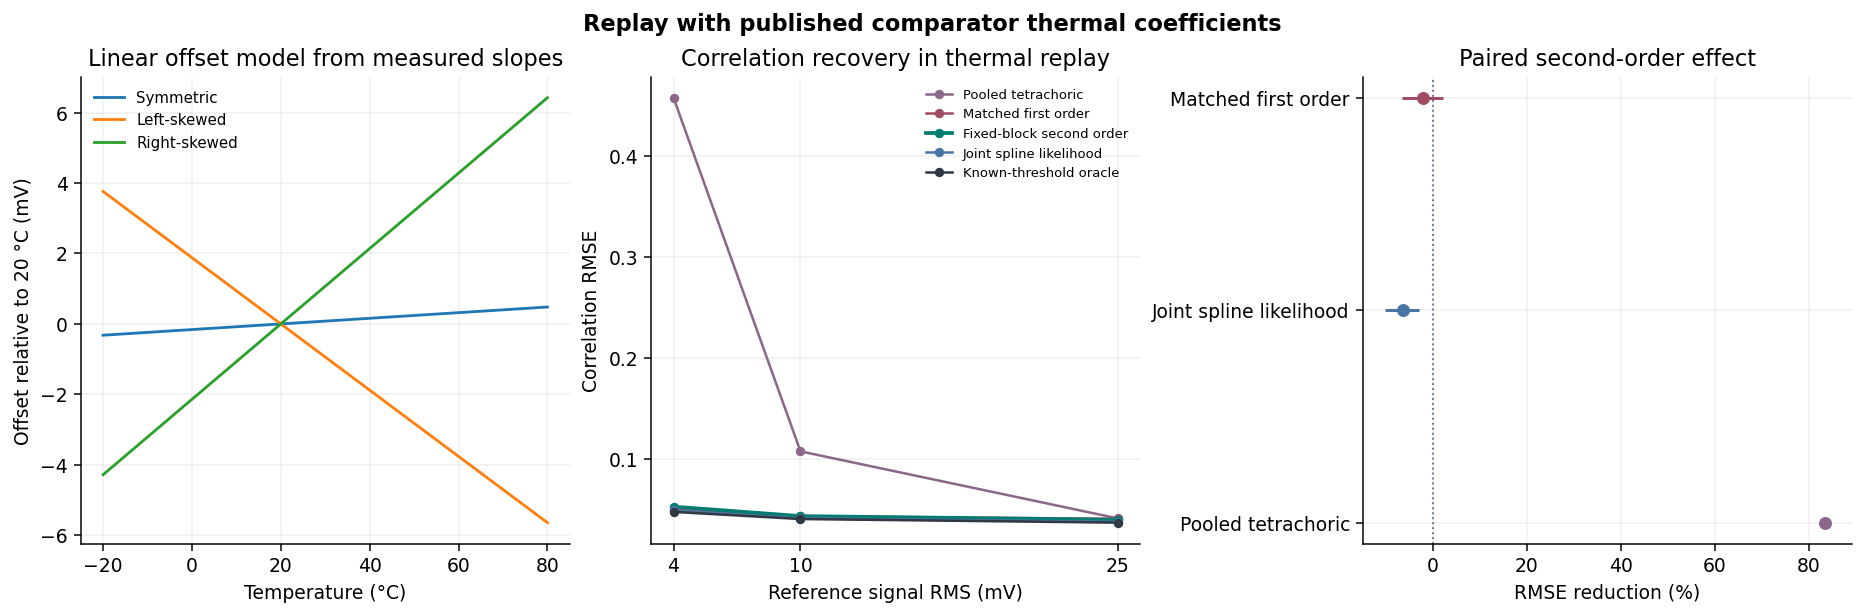

In [ ]:
# Thermal replay RMSE, paired intervals, and measured coefficient scale
thermal_order = ("Fixed-block second order", "Matched first order", "Joint spline likelihood",
                 "Pooled tetrachoric", "Known-threshold oracle")
thermal_rmse = empirical_metrics(thermal_results, ["rms_mv", "method"]).pivot(
    index="method", columns="rms_mv", values="rmse")
thermal_rmse.columns = [f"{x:g} mV RMS" for x in thermal_rmse.columns]
thermal_rmse["Overall RMSE"] = thermal_results.groupby("method")["error"].agg(rmse)
thermal_effects = paired_rmse_intervals(thermal_results, thermal_order[:-1], seed=196634)
thermal_table = thermal_rmse.join(thermal_effects.set_index("baseline")).reindex(thermal_order)
display(thermal_table.round(4))
converged = thermal_results.loc[thermal_results.method.eq("Joint spline likelihood"), "converged"]
print(f"Joint spline optimizer convergence {converged.mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(13.7, 4.45), layout="constrained")
t = np.linspace(-20, 80, 101)
for name, slope in MEASURED_SLOPE_UV_C.items():
    axes[0].plot(t, slope * (t - 20) / 1000, label=name)
axes[0].set(title="Linear offset model from measured slopes", xlabel="Temperature (°C)",
            ylabel="Offset relative to 20 °C (mV)")
axes[0].legend(fontsize=8)
for name in THERMAL_METHODS:
    values = thermal_rmse.loc[name, [f"{s:g} mV RMS" for s in THERMAL_LEVELS]].to_numpy()
    axes[1].plot(THERMAL_LEVELS, values, label=name, color=THERMAL_COLORS[name],
                 marker="o", markersize=4, linewidth=2 if name == "Fixed-block second order" else 1.35)
axes[1].set(title="Correlation recovery in thermal replay", xlabel="Reference signal RMS (mV)",
            ylabel="Correlation RMSE", xticks=THERMAL_LEVELS)
axes[1].legend(fontsize=7.0)
axes[2].axvline(0, linewidth=1.0, color="#657483", linestyle=":")
for j, row in thermal_effects.iterrows():
    color = THERMAL_COLORS[row["baseline"]]
    axes[2].hlines(j, row["95% lower"], row["95% upper"], color=color, linewidth=1.6)
    axes[2].scatter(row["RMSE reduction (%)"], j, color=color, s=35, zorder=4)
axes[2].set(title="Paired second-order effect", xlabel="RMSE reduction (%)",
            yticks=np.arange(len(thermal_effects)), yticklabels=thermal_effects["baseline"])
axes[2].invert_yaxis()
fig.suptitle("Replay with published comparator thermal coefficients", fontweight="bold")
plt.show()


In [ ]:
# Recorded reference waveform replay with offline comparator decisions
def recorded_thermal_replay():
    path = Path(mpl.get_data_path()) / "sample_data" / "eeg.dat"
    if not path.is_file():
        print("The installed Matplotlib package has no sample waveform.")
        return pd.DataFrame()
    # Reference recording: https://matplotlib.org/3.0.2/gallery/specialty_plots/mri_with_eeg.html
    raw = np.fromfile(path, dtype="<f8").reshape(-1, 4)
    standard = (raw - raw.mean(axis=0)) / raw.std(axis=0)
    rows = []
    for pair, device_pair, protocol, sigma in product(combinations(range(4), 2), THERMAL_PAIRS,
                                                     THERMAL_PROTOCOLS, (4.0, 10.0, 25.0)):
        analog = sigma * standard[:, pair]
        truth = float(np.corrcoef(analog.T)[0, 1])
        _, threshold = thermal_thresholds(len(analog), device_pair, protocol)
        bits = (analog <= threshold).astype(float)
        if pair_status(bits) != "OK":
            continue
        values, _ = thermal_estimators(bits)
        for name, value in values.items():
            rows.append({"pair": pair, "device pair": device_pair, "protocol": protocol, "rms_mv": sigma,
                         "method": name, "estimate": value, "error": value - truth})
    print(f"{len(rows) // 4} offline quantizations of the same reference recording")
    return pd.DataFrame(rows)


recorded_thermal = recorded_thermal_replay()
if not recorded_thermal.empty:
    display(recorded_thermal.groupby("method")["error"].agg(RMSE=rmse,
            MAE=lambda e: e.abs().mean()).round(4))


144 offline quantizations of the same reference recording


,RMSE,MAE
method,,
Fixed-block second order,0.4502,0.2977
Joint spline likelihood,0.1712,0.1290
Matched first order,0.0827,0.0671
Pooled tetrachoric,0.2686,0.1813


In [ ]:
# Temporal ordering diagnostic on the recorded reference
def temporal_replay_diagnostic(seed):
    sample = Path(mpl.get_data_path()) / "sample_data" / "eeg.dat"
    if not sample.is_file():
        return pd.DataFrame()
    raw = np.fromfile(sample, dtype="<f8").reshape(-1, 4)
    z = (raw - raw.mean(axis=0)) / raw.std(axis=0)
    rng = np.random.default_rng(seed)
    rows = []
    for pair, device_pair, protocol, sigma in product(combinations(range(4), 2), THERMAL_PAIRS,
                                                     THERMAL_PROTOCOLS, THERMAL_LEVELS):
        analog = sigma * z[:, pair]
        reference = np.corrcoef(analog.T)[0, 1]
        _, offsets = thermal_thresholds(len(analog), device_pair, protocol)
        permutations = (("Recorded order", np.arange(len(analog))),
                        ("Permuted paired rows", rng.permutation(len(analog))))
        for order, permutation in permutations:
            data = analog[permutation]
            np.testing.assert_allclose(np.corrcoef(data.T)[0, 1], reference, atol=1e-12)
            bits = (data <= offsets).astype(float)
            if pair_status(bits) != "OK":
                continue
            block = fixed_block_moments(bits)
            first = MomentEstimator(block, order=1, weighted=False, shrink=False, stabilize=False).fit().rho
            second = MomentEstimator(block, weighted=False, shrink=False, stabilize=False).fit().rho
            lag = np.mean([abs(np.corrcoef(data[1:, j], data[:-1, j])[0, 1]) for j in (0, 1)])
            rows.extend((order, name, estimate - reference, lag, np.nan) for name, estimate in
                        (("Matched first order", first), ("Fixed-block second order", second)))
            if order == "Recorded order":
                buffered = fit_onebit(bits)
                rows.append((order, "Adaptive lag buffer", buffered.rho - reference, lag, buffered.gap))
    return pd.DataFrame(rows, columns=("order", "method", "error", "absolute lag-1 reference correlation", "gap"))


temporal_diagnostic = temporal_replay_diagnostic(196636)
if not temporal_diagnostic.empty:
    temporal_summary = temporal_diagnostic.groupby(["order", "method"]).agg(
        RMSE=("error", rmse), MAE=("error", lambda e: e.abs().mean()),
        mean_abs_lag1=("absolute lag-1 reference correlation", "mean"),
        median_selected_gap=("gap", "median"),
    )
    display(temporal_summary.round(4))


RMSE     MAE  mean_abs_lag1  \
order                method                                                    
Permuted paired rows Fixed-block second order  0.0736  0.0577         0.0281   
                     Matched first order       0.0707  0.0557         0.0281   
Recorded order       Adaptive lag buffer       0.1349  0.0865         0.8839   
                     Fixed-block second order  0.4502  0.2977         0.8839   
                     Matched first order       0.0827  0.0671         0.8839   

                                               median_selected_gap  
order                method                                         
Permuted paired rows Fixed-block second order                  NaN  
                     Matched first order                       NaN  
Recorded order       Adaptive lag buffer                       8.0  
                     Fixed-block second order                  NaN  
                     Matched first order                       NaN

In [ ]:
# Main manuscript comparisons by evidence type
def comparison_row(label, source, cases, errors, second, first, spline=None):
    return {"Study": label, "Evidence": source, "Cases": cases,
            "Second-order RMSE": errors[second], "First-order RMSE": errors[first],
            "Spline RMSE": errors[spline] if spline else np.nan}


paper_rows = [comparison_row(
    "Gaussian confirmation", "Independent simulated snapshots",
    confirmation[["family", "n", "truth", "rep"]].drop_duplicates().shape[0],
    confirmation_table.rmse, "Smoothness-free SO", "Matched first order", "Spline joint MLE",
), comparison_row(
    "Thermal-coefficient replay", "Measured offset slopes, simulated bits",
    thermal_results[["family", "n", "truth", "rep"]].drop_duplicates().shape[0],
    thermal_table["Overall RMSE"], "Fixed-block second order", "Matched first order",
    "Joint spline likelihood",
)]
if not recorded_thermal.empty:
    paper_rows.append(comparison_row(
        "Waveform replay in original order", "Bundled EEG waveform, offline bits",
        recorded_thermal[["pair", "device pair", "protocol", "rms_mv"]].drop_duplicates().shape[0],
        recorded_thermal.groupby("method")["error"].agg(rmse), "Fixed-block second order",
        "Matched first order", "Joint spline likelihood",
    ))
if not temporal_diagnostic.empty:
    permuted = temporal_diagnostic.loc[temporal_diagnostic.order.eq("Permuted paired rows")]
    paper_rows.append(comparison_row(
        "Waveform replay with permuted pairs", "Same EEG waveform, offline bits",
        int(permuted.method.eq("Fixed-block second order").sum()),
        permuted.groupby("method")["error"].agg(rmse), "Fixed-block second order", "Matched first order",
    ))
paper_results = pd.DataFrame(paper_rows).set_index("Study")
display(paper_results.round(4))

# Related one-bit autocorrelation work: Liu and Chiu, IEEE SAM, doi:10.1109/SAM68950.2026.11687999.
# The fixed-block rate analysis assumes independent Gaussian snapshots and Hölder threshold drift.


,Evidence,Cases,Second-order RMSE,First-order RMSE,Spline RMSE
Study,,,,,
Gaussian confirmation,Independent simulated snapshots,240,0.0555,0.1240,0.0837
Thermal-coefficient replay,"Measured offset slopes, simulated bits",864,0.0453,0.0444,0.0426
Waveform replay in original order,"Bundled EEG waveform, offline bits",144,0.4502,0.0827,0.1712
Waveform replay with permuted pairs,"Same EEG waveform, offline bits",144,0.0736,0.0707,NaN


rho_nominal,0.65,0.00,-0.65
Planned runs,,,
Fixed,4,4,4
Ramp,4,4,4
Cycle,4,4,4
Fast cycle,4,4,4


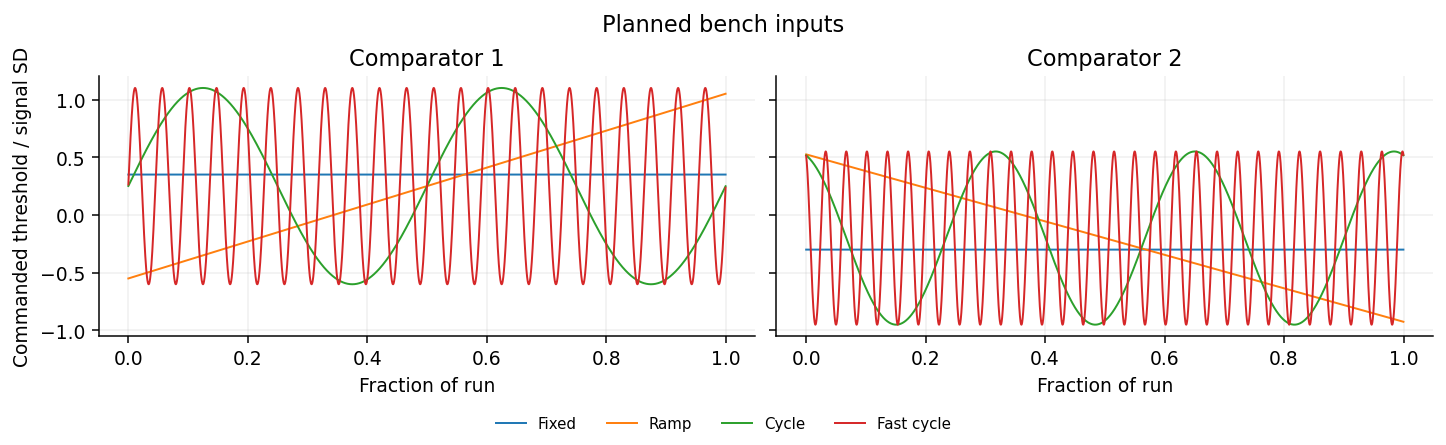

In [ ]:
# Randomized bench schedule and normalized AWG commands
# Split both stimulus outputs to the comparators and reference ADC inputs.
# Record both comparator outputs and reference voltages on one clock.
# Calibrate channel delay with a common edge before collecting trials.
# Export one row per Gaussian step after analog and comparator settling.
# Log input-referred thresholds or align temperature to the capture timebase.
bench_rng = np.random.default_rng(196634)
conditions = ("Fixed", "Ramp", "Cycle", "Fast cycle")
bench_cases = list(product(conditions, (-0.65, 0.0, 0.65), range(1, 5)))
bench_plan = pd.DataFrame([bench_cases[i] for i in bench_rng.permutation(len(bench_cases))],
                          columns=["condition", "rho_nominal", "repeat"])
bench_plan.insert(0, "run_id", [f"R{i:02}" for i in range(1, len(bench_plan) + 1)])
bench_plan["seed"] = bench_rng.integers(0, 2**32, len(bench_plan))


def bench_program(run_id):
    row = bench_plan.set_index("run_id").loc[run_id]
    rng = np.random.default_rng(int(row.seed))
    a, z = rng.standard_normal((2, SNAPSHOTS_PER_RUN))
    rho = row.rho_nominal
    b = rho * a + np.sqrt(1 - rho**2) * z
    step = np.arange(SNAPSHOTS_PER_RUN)
    u = (step + 0.5) / SNAPSHOTS_PER_RUN
    if row.condition == "Fixed":
        th1, th2 = np.full_like(u, 0.35), np.full_like(u, -0.30)
    elif row.condition == "Ramp":
        th1, th2 = 1.6 * (u - 0.5) + 0.25, -1.45 * (u - 0.5) - 0.20
    else:
        f1, f2 = (2, 3) if row.condition == "Cycle" else (22, 29)
        th1 = 0.25 + 0.85 * np.sin(2 * np.pi * f1 * u)
        th2 = -0.20 + 0.75 * np.cos(2 * np.pi * f2 * u + 0.3)
    return pd.DataFrame({"step": step, "ref_1_sigma": a, "ref_2_sigma": b,
                         "threshold_1_sigma": th1, "threshold_2_sigma": th2})


def awg_voltages(run_id, *, dwell_s, common_mode_v, sigma_v):
    # Choose amplitudes and dwell for the measured input range and settling time.
    if not np.all(np.isfinite([dwell_s, common_mode_v, sigma_v])) or min(dwell_s, sigma_v) <= 0:
        raise ValueError("Use a finite common mode, positive dwell, and positive signal scale.")
    program = bench_program(run_id)
    columns = program.columns.drop("step")
    volts = program[columns] * sigma_v + common_mode_v
    volts.columns = [c.removesuffix("_sigma") + "_v" for c in columns]
    volts.insert(0, "time_s", program.step * dwell_s)
    return volts


display(bench_plan.groupby(["condition", "rho_nominal"], sort=False).size()
        .unstack("rho_nominal").reindex(conditions).rename_axis("Planned runs"))
fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.2), sharey=True, layout="constrained")
for condition in conditions:
    run_id = bench_plan.loc[bench_plan.condition == condition, "run_id"].iat[0]
    program = bench_program(run_id)
    for j, ax in enumerate(axes, start=1):
        ax.plot(program.step / SNAPSHOTS_PER_RUN, program[f"threshold_{j}_sigma"],
                lw=1.05, label=condition)
for j, ax in enumerate(axes, start=1):
    ax.set(title=f"Comparator {j}", xlabel="Fraction of run")
axes[0].set_ylabel("Commanded threshold / signal SD")
fig.legend(*axes[0].get_legend_handles_labels(), ncols=4, fontsize=8, loc="outside lower center")
fig.suptitle("Planned bench inputs")
plt.show()


In [ ]:
# CSV schema and capture quality checks
REF_COLUMNS = ["ref_1_v", "ref_2_v"]
BIT_COLUMNS = ["bit_1", "bit_2"]
THRESHOLD_COLUMNS = ["threshold_1_v", "threshold_2_v"]
CAPTURE_COLUMNS = ["run_id", "time_s", *REF_COLUMNS, *BIT_COLUMNS]
METHOD_COLORS = {"Pooled tetrachoric": "#737D88", "Matched first order": "#3C70A7",
                 "Fixed-block second order": "#007D70", "Joint spline likelihood": "#884E93"}
PROPOSED = "Fixed-block second order"


def read_capture(path):
    # Add both measured threshold columns or a synchronized temp_c column.
    frame = pd.read_csv(path, dtype={"run_id": "string", "run": "string", "condition": "string"})
    aliases = {"run": "run_id", "reference_1": "ref_1_v", "reference_2": "ref_2_v"}
    frame = frame.rename(columns={key: value for key, value in aliases.items() if value not in frame})
    required = set(CAPTURE_COLUMNS)
    if missing := required - set(frame):
        raise ValueError(f"Missing capture columns {sorted(missing)}.")
    if frame.empty:
        raise ValueError("The capture has no samples.")
    if "condition" not in frame:
        frame["condition"] = "Unspecified"
    for key in ("run_id", "condition"):
        frame[key] = frame[key].str.strip()
        if frame[key].isna().any() or frame[key].eq("").any():
            raise ValueError(f"Each row needs a {key}.")
    for key in [*CAPTURE_COLUMNS[1:], *THRESHOLD_COLUMNS, "temp_c", "rho_nominal"]:
        if key in frame:
            frame[key] = pd.to_numeric(frame[key], errors="coerce")
        else:
            frame[key] = np.nan
    return frame


def lag_matrices(reference, max_lag=8):
    standardized = (reference - reference.mean(axis=0)) / reference.std(axis=0)
    return np.stack([standardized[:-k].T @ standardized[k:] / (len(reference) - k)
                     for k in range(1, max_lag + 1)])


def run_quality(frame):
    t = frame.time_s.to_numpy()
    x, bits = frame[REF_COLUMNS].to_numpy(), frame[BIT_COLUMNS].to_numpy()
    threshold = frame[THRESHOLD_COLUMNS].to_numpy()
    temp = frame.temp_c.to_numpy()
    has_thresholds = bool(np.isfinite(threshold).all())
    has_temp = bool(np.isfinite(temp).all())
    rho = frame.rho_nominal.to_numpy()
    info = {"run_id": frame.run_id.iat[0], "condition": frame.condition.iat[0],
            "n": len(frame), "rho_nominal": np.nan, "status": "OK"}
    errors = []
    if frame.condition.nunique() != 1:
        errors.append("mixed conditions")
    if len(frame) < MIN_SNAPSHOTS:
        errors.append("short capture")
    if not np.isfinite(t).all() or np.any(np.diff(t) <= 0):
        errors.append("timestamps must increase")
    elif len(t) > 1:
        dt = np.diff(t)
        spacing_error = np.max(np.abs(dt / np.median(dt) - 1))
        info["spacing_error"] = spacing_error
        if spacing_error > MAX_SPACING_ERROR:
            errors.append("irregular sampling")
    if not np.isfinite(x).all() or np.any(x.std(axis=0) <= 0):
        errors.append("invalid reference")
    if not np.isin(bits, (0, 1)).all() or np.any(np.ptp(bits, axis=0) == 0):
        errors.append("invalid or constant comparator output")
    if not (has_thresholds or has_temp):
        errors.append("missing synchronized drift log")
    if not np.isnan(rho).all():
        if not (np.isfinite(rho).all() and np.ptp(rho) == 0 and abs(rho[0]) < 1):
            errors.append("invalid nominal correlation")
        else:
            info["rho_nominal"] = rho[0]
    if errors:
        info["status"] = ", ".join(errors)
        return info
    info["rho_reference"] = np.corrcoef(x.T)[0, 1]
    info["peak_abs_lag_corr"] = np.abs(lag_matrices(x)).max()
    info["serial_flag"] = info["peak_abs_lag_corr"] > max(0.08, 4 / np.sqrt(len(x)))
    info["drift_log"] = "Threshold and temperature" if has_thresholds and has_temp else (
        "Threshold" if has_thresholds else "Temperature")
    info["temp_span_c"] = float(np.ptp(temp)) if has_temp else np.nan
    if has_thresholds:
        margin = x - threshold
        far = np.abs(margin) > 0.05 * x.std(axis=0)
        miss = (bits == 1) != (margin > 0)
        for j in range(2):
            info[f"threshold_span_{j+1}_sd"] = np.ptp(threshold[:, j]) / x[:, j].std()
            info[f"far_mismatch_{j+1}"] = miss[far[:, j], j].mean() if far[:, j].any() else np.nan
    return info


def analyze_capture(frame):
    records, estimates = [], []
    for _, run in frame.groupby("run_id", sort=False):
        quality = run_quality(run)
        records.append(quality)
        if quality["status"] != "OK":
            continue
        bits = run[BIT_COLUMNS].to_numpy(dtype=float)
        fitted, spline_ok = thermal_estimators(bits)
        for method, rho in fitted.items():
            status = "OK"
            if not np.isfinite(rho):
                status = "Invalid estimate"
            elif method == "Joint spline likelihood" and not spline_ok:
                status = "Optimizer warning"
            elif abs(rho) >= RHO_LIMIT - 2e-5:
                status = "Boundary"
            estimates.append({"run_id": quality["run_id"], "condition": quality["condition"],
                              "rho_nominal": quality["rho_nominal"],
                              "method": method, "estimate": rho, "fit_status": status,
                              "reference": quality["rho_reference"],
                              "error": rho - quality["rho_reference"]})
    return pd.DataFrame(records), pd.DataFrame(estimates)


def summarize_capture(estimates):
    errors = estimates.pivot(index=["condition", "run_id"], columns="method", values="error")
    errors = errors.replace([np.inf, -np.inf], np.nan).dropna()
    methods = list(METHOD_COLORS)
    meta = estimates.drop_duplicates("run_id").set_index("run_id")
    rows, comparisons = [], []
    rng = np.random.default_rng(196635)
    groups = [("All conditions", errors), *errors.groupby(level="condition", sort=False)]
    for condition, group in groups:
        if group.empty:
            continue
        values = group[methods].to_numpy()
        rmses = np.sqrt(np.mean(values**2, axis=0))
        for j, method in enumerate(methods):
            rows.append({"Condition": condition, "Method": method, "Runs": len(group),
                         "RMSE": rmses[j], "MAE": np.abs(values[:, j]).mean(),
                         "Bias": values[:, j].mean()})
        z = group.reset_index()[["condition", "run_id"]]
        z["rho_nominal"] = meta.loc[z.run_id, "rho_nominal"].to_numpy()
        strata = ["condition", "rho_nominal"] if z.rho_nominal.notna().all() else ["condition"]
        strata = list(z.groupby(strata, sort=False).indices.values())
        rmse_draw = None
        if len(group) >= 8 and min(map(len, strata)) >= 2:
            indices = np.column_stack([rng.choice(idx, (BOOTSTRAP_DRAWS, len(idx)))
                                       for idx in strata])
            rmse_draw = np.sqrt(np.mean(values[indices]**2, axis=1))
        j = methods.index(PROPOSED)
        for k, baseline in enumerate(methods):
            if k == j:
                continue
            lo, hi = (np.nan, np.nan) if rmse_draw is None else np.quantile(
                rmse_draw[:, j] - rmse_draw[:, k], [0.025, 0.975])
            comparisons.append({"Condition": condition, "Baseline": baseline, "Runs": len(group),
                                "RMSE difference": rmses[j] - rmses[k], "95% low": lo, "95% high": hi})
    return errors, pd.DataFrame(rows), pd.DataFrame(comparisons)


In [ ]:
# Hardware results for the aligned capture CSV
capture = quality = estimates = paired_errors = summary = comparisons = None
if UPLOAD_CAPTURE:
    from google.colab import files

    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Select one aligned capture CSV.")
    CAPTURE_CSV = Path(next(iter(uploaded)))

if not CAPTURE_CSV.is_file():
    print(f"Awaiting {CAPTURE_CSV.name}. Hardware metrics require a recorded capture.")
    display(pd.DataFrame({"Required columns": CAPTURE_COLUMNS}))
    print("Include threshold_1_v and threshold_2_v, or temp_c, for the drift log.")
    print("Use 0 or 1 for comparator bits. Optional columns are condition and rho_nominal.")
else:
    capture = read_capture(CAPTURE_CSV)
    quality, estimates = analyze_capture(capture)
    valid_count = int(quality.status.eq("OK").sum())
    print(f"{valid_count}/{len(quality)} runs passed the capture-format checks.")
    with pd.option_context("display.max_columns", None, "display.max_rows", 60):
        display(quality.round(5))
    if estimates.empty:
        print("The capture has no runs eligible for estimation. See the status column.")
    else:
        paired_errors, summary, comparisons = summarize_capture(estimates)
        print(f"{len(paired_errors)}/{valid_count} valid runs have a full set of finite estimates.")
        display(estimates.groupby(["method", "fit_status"]).size().rename("runs").to_frame())
        if not summary.empty:
            with pd.option_context("display.max_rows", 50):
                display(summary.round(5))
                display(comparisons.round(5))


Awaiting comparator_capture.csv. Hardware metrics require a recorded capture.


,Required columns
0,run_id
1,time_s
2,ref_1_v
3,ref_2_v
4,bit_1
5,bit_2


Include threshold_1_v and threshold_2_v, or temp_c, for the drift log.
Use 0 or 1 for comparator bits. Optional columns are condition and rho_nominal.


In [ ]:
# Estimate calibration, error distributions, and paired RMSE differences
if paired_errors is not None and not paired_errors.empty:
    paired_ids = paired_errors.index.get_level_values("run_id")
    paired = estimates.loc[estimates.run_id.isin(paired_ids)]
    fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.0), layout="constrained")
    for method, method_data in paired.groupby("method", sort=False):
        color = METHOD_COLORS[method]
        axes[0].scatter(method_data.reference, method_data.estimate, s=23, alpha=0.68,
                        color=color, label=method)
        ordered = np.sort(np.abs(method_data.error))
        axes[1].step(np.r_[0, ordered], np.arange(len(ordered) + 1) / len(ordered),
                     where="post", lw=1.6, color=color)
        midpoint = (method_data.reference + method_data.estimate) / 2
        axes[2].scatter(midpoint, method_data.error, color=color, alpha=0.66, s=21)
    extent = min(1.0, max(0.15, np.max(np.abs(paired[["reference", "estimate"]].to_numpy())) + 0.04))
    axes[0].plot([-extent, extent], [-extent, extent], color="#505861", ls="--", lw=1)
    axes[0].set(title="Correlation agreement", xlabel="Reference correlation",
                ylabel="Estimated correlation", xlim=(-extent, extent), ylim=(-extent, extent))
    axes[0].legend(fontsize=7, loc="upper left")
    axes[1].set(title="Absolute error distribution", xlabel="Absolute correlation error",
                ylabel="Fraction of matched runs")
    axes[2].axhline(0, color="#505861", ls="--", lw=1)
    axes[2].set(title="Bland–Altman comparison", xlabel="Mean of estimate and reference",
                ylabel="Estimate − reference")
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True, layout="constrained")
    for ax, (baseline, rows) in zip(axes, comparisons.groupby("Baseline", sort=False)):
        y = np.arange(len(rows))
        ax.axvline(0, lw=1, ls="--", color="#505861")
        ax.hlines(y, rows["95% low"], rows["95% high"], color=METHOD_COLORS[baseline], lw=1.8)
        ax.scatter(rows["RMSE difference"], y, s=26, color=METHOD_COLORS[baseline], zorder=3)
        ax.set(yticks=y, yticklabels=rows.Condition, title=baseline,
               xlabel="Second order − baseline RMSE")
    axes[0].invert_yaxis()
    plt.show()


In [ ]:
# Synchronized drift and reference diagnostics for one capture
if quality is not None and quality.status.eq("OK").any():
    valid = quality.loc[quality.status.eq("OK")]
    if TRACE_RUN is None:
        drifting = valid.loc[~valid.condition.str.lower().eq("fixed")]
        run_id = (drifting if len(drifting) else valid).run_id.iat[0]
    else:
        run_id = TRACE_RUN
        if run_id not in set(valid.run_id):
            raise ValueError("TRACE_RUN must identify a valid run in the capture.")
    run = capture.loc[capture.run_id == run_id]
    t = run.time_s.to_numpy() - run.time_s.iat[0]
    x, bits = run[REF_COLUMNS].to_numpy(), run[BIT_COLUMNS].to_numpy()
    threshold, temp = run[THRESHOLD_COLUMNS].to_numpy(), run.temp_c.to_numpy()
    normalized = (x - x.mean(axis=0)) / x.std(axis=0)
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.0), layout="constrained")
    chunks = np.array_split(np.arange(len(run)), min(32, len(run) // 32))
    center_times = [t[index].mean() for index in chunks]
    colors = ("#007D70", "#C85833")
    for j, color in enumerate(colors):
        axes[0, 0].plot(center_times, [bits[k, j].mean() for k in chunks],
                        "o-", ms=3, lw=1.05, color=color, label=f"Channel {j+1}")
        if np.isfinite(threshold).all():
            axes[0, 1].plot(t, (threshold[:, j] - x[:, j].mean()) / x[:, j].std(),
                            lw=1.2, color=color, label=f"Channel {j+1}")
        probabilities = np.linspace(0.01, 0.99, 99)
        axes[1, 0].plot(special.ndtri(probabilities), np.quantile(normalized[:, j], probabilities),
                        lw=1.2, color=color)
    axes[0, 0].set(title="Comparator duty cycle", xlabel="Time (s)", ylabel="Fraction of high bits")
    axes[0, 0].legend(fontsize=8)
    if np.isfinite(threshold).all():
        axes[0, 1].set(title="Logged thresholds", xlabel="Time (s)", ylabel="Threshold / signal SD")
        if np.isfinite(temp).all():
            temperature_axis = axes[0, 1].twinx()
            temperature_axis.plot(t, temp, color="#4B5260", ls=":", lw=1.2)
            temperature_axis.set_ylabel("Temperature (°C)")
    else:
        axes[0, 1].plot(t, temp, color="#4B5260", lw=1.3)
        axes[0, 1].set(title="Logged temperature", xlabel="Time (s)", ylabel="Temperature (°C)")
    axes[1, 0].plot([-2.35, 2.35], [-2.35, 2.35], ls="--", color="#505861", lw=1)
    axes[1, 0].set(title="Reference Gaussian Q–Q", xlabel="Normal quantile", ylabel="Reference quantile")
    lag = lag_matrices(x)
    for i, j in product(range(2), repeat=2):
        axes[1, 1].plot(np.arange(1, len(lag) + 1), lag[:, i, j], "o-", ms=3,
                        lw=1.05, label=f"{i+1} → {j+1}")
    axes[1, 1].axhline(0, color="#505861", lw=1)
    axes[1, 1].set(title="Reference dependence across snapshots", xlabel="Lag", ylabel="Lag correlation")
    axes[1, 1].legend(ncols=2, fontsize=8)
    fig.suptitle(f"Capture {run_id} · {run.condition.iat[0]}")
    plt.show()
